#Philip Frost

Philip Frost is an American billionaire investor and entrepreneur known for his involvement in the pharmaceutical industry. He has been a key figure in companies like Opko Health and has invested in various publicly traded companies. In this analysis, we are examining 10 stocks that Philip Frost holds, analyzing their historical performance, and deriving insights using financial data.

## Setting up DataFrame




In [ ]:
!pip install yfinance

In [ ]:
!pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 19.4 MB/s eta 0:00:00


In [ ]:
pip install yahooquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 62.4 MB/s eta 0:00:00
  Attempting uninstall: lxml
    Found existing installation: lxml 5.3.1
    Uninstalling lxml-5.3.1:
      Successfully uninstalled lxml-5.3.1


In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from yahooquery import Ticker
import pandas as pd

# Define stock tickers and shares held
stocks = {
    "OPK": 283305576,   # Example shares, replace with actual values
    "NOC": 102497,
    "DOUG": 7650618,
    "FLNT": 4386390,
    "NXPL": 3428571,
    "VERU": 5100253,
    "COCP": 1346938,
    "NNUP": 1271930,
    "PLX": 307611,
    "CDXC": 2351521
}

# Define date range
start_date = "2024-01-01"
end_date = "2025-01-01"

# Fetch data for all stocks at once
tickers = Ticker(list(stocks.keys()))
historical_data = tickers.history(start=start_date, end=end_date)

# Ensure the data is in DataFrame format
if isinstance(historical_data, pd.DataFrame):
    # Reset index to make 'symbol' and 'date' columns
    historical_data = historical_data.reset_index()

    # Pivot table to organize data by stock
    stock_data = historical_data.pivot(index='date', columns='symbol')

    # Flatten multi-index columns
    stock_data.columns = ['_'.join(col).strip() for col in stock_data.columns.values]

    # Add shares held for each stock
    for stock, shares in stocks.items():
        stock_data[f"{stock}_Shares_Held"] = shares

    # Forward fill missing values
    stock_data.ffill(inplace=True)
    stock_data.bfill(inplace=True)  # Backfill in case the first row has NaN

    # Print summary
    print(f"Total NaN values after imputation: {stock_data.isna().sum().sum()}")
    print(stock_data.head())

    # Save to CSV
    stock_data.to_csv("portfolio_stock_data.csv")

else:
    print("Error: Historical data not retrieved properly.")



Total NaN values after imputation: 0
            open_CDXC  open_COCP  open_DOUG  open_FLNT  open_NNUP    open_NOC  \
date                                                                            
2024-01-02       1.42       1.74       2.91       3.90       3.48  469.190002   
2024-01-03       1.39       1.79       2.88       4.08       3.48  474.440002   
2024-01-04       1.48       1.80       2.91       4.26       3.45  481.309998   
2024-01-05       1.50       1.81       2.82       4.26       3.50  472.720001   
2024-01-08       1.48       1.83       2.85       4.38       3.25  466.029999   

            open_NXPL  open_OPK  open_PLX  open_VERU  ...  OPK_Shares_Held  \
date                                                  ...                    
2024-01-02       1.58      1.51      1.78       0.74  ...        283305576   
2024-01-03       1.75      1.55      1.80       0.72  ...        283305576   
2024-01-04       1.60      1.22      1.80       0.70  ...        283305576   
2024-

/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "

In [ ]:
stock_data.columns

Index(['open_CDXC', 'open_COCP', 'open_DOUG', 'open_FLNT', 'open_NNUP',
       'open_NOC', 'open_NXPL', 'open_OPK', 'open_PLX', 'open_VERU',
       'high_CDXC', 'high_COCP', 'high_DOUG', 'high_FLNT', 'high_NNUP',
       'high_NOC', 'high_NXPL', 'high_OPK', 'high_PLX', 'high_VERU',
       'low_CDXC', 'low_COCP', 'low_DOUG', 'low_FLNT', 'low_NNUP', 'low_NOC',
       'low_NXPL', 'low_OPK', 'low_PLX', 'low_VERU', 'close_CDXC',
       'close_COCP', 'close_DOUG', 'close_FLNT', 'close_NNUP', 'close_NOC',
       'close_NXPL', 'close_OPK', 'close_PLX', 'close_VERU', 'volume_CDXC',
       'volume_COCP', 'volume_DOUG', 'volume_FLNT', 'volume_NNUP',
       'volume_NOC', 'volume_NXPL', 'volume_OPK', 'volume_PLX', 'volume_VERU',
       'adjclose_CDXC', 'adjclose_COCP', 'adjclose_DOUG', 'adjclose_FLNT',
       'adjclose_NNUP', 'adjclose_NOC', 'adjclose_NXPL', 'adjclose_OPK',
       'adjclose_PLX', 'adjclose_VERU', 'dividends_CDXC', 'dividends_COCP',
       'dividends_DOUG', 'dividends_FLNT', 'dividen

In [ ]:
stock_data.shape

(252, 90)

In [ ]:
import pandas as pd

# Portfolio details with provided shares held and portfolio percentage
portfolio_details = {
    "OPK": {"portfolio_pct": 83.39, "shares_held": 283305576},
    "NOC": {"portfolio_pct": 8.01, "shares_held": 102497},
    "DOUG": {"portfolio_pct": 2.37, "shares_held": 7650618},
    "FLNT": {"portfolio_pct": 2.01, "shares_held": 4386390},
    "NXPL": {"portfolio_pct": 0.5684, "shares_held": 3428571},
    "VERU": {"portfolio_pct": 0.4484, "shares_held": 5100253},
    "COCP": {"portfolio_pct": 0.3942, "shares_held": 1346938},
    "NNUP": {"portfolio_pct": 0.3228, "shares_held": 1271930},
    "PLX": {"portfolio_pct": 0.1213, "shares_held": 307611},
    "CDXC": {"portfolio_pct": 2.24, "shares_held": 2351521}
}

# Create a new DataFrame to modify
stock_data_updated = stock_data.copy()

# Reset index if it's not numeric
if not isinstance(stock_data.index, pd.RangeIndex):
    stock_data = stock_data.reset_index(drop=True)

# Iterate through each stock and backtrack the shares held
for stock, data in portfolio_details.items():
    adj_price_col = f"adjclose_{stock}"  # Adjusted close price column
    shares_held_col = f"{stock}_Shares_Held"  # Shares held column

    if adj_price_col in stock_data.columns:  # Ensure price column exists
        latest_price = stock_data[adj_price_col].dropna().iloc[-1]  # Most recent price
        latest_shares_held = data["shares_held"]  # Given latest shares held

        # Calculate total holding value at the most recent date
        total_holding_value = latest_price * latest_shares_held

        # Iterate backwards to calculate shares held historically
        for i in range(len(stock_data) - 2, -1, -1):  # Start from second last row
            price = stock_data.iloc[i][adj_price_col]  # Get historical adj close price
            if pd.notna(price):  # Avoid NaN prices
                stock_data_updated.iloc[i, stock_data.columns.get_loc(shares_held_col)] = total_holding_value / price  # Recalculate shares held

# Display the last few rows of the updated DataFrame
print(stock_data_updated.tail())

# Save the updated DataFrame to CSV
stock_data_updated.to_csv("updated_portfolio_stock_data.csv")

<ipython-input-8-763a5c42da2b>:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '281391350.9853537' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  stock_data_updated.iloc[i, stock_data.columns.get_loc(shares_held_col)] = total_holding_value / price  # Recalculate shares held
<ipython-input-8-763a5c42da2b>:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '103105.58815718215' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  stock_data_updated.iloc[i, stock_data.columns.get_loc(shares_held_col)] = total_holding_value / price  # Recalculate shares held
<ipython-input-8-763a5c42da2b>:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '8242923.9514350565' has dtype inc

            open_CDXC  open_COCP  open_DOUG  open_FLNT  open_NNUP    open_NOC  \
date                                                                            
2024-12-24       5.31       2.73       1.57       2.60       1.67  466.690002   
2024-12-26       5.40       2.34       1.60       2.59       1.67  471.089996   
2024-12-27       5.55       2.64       1.57       2.65       1.70  469.619995   
2024-12-30       5.45       3.12       1.54       2.59       1.70  467.820007   
2024-12-31       5.46       2.20       1.53       2.52       1.67  466.519989   

            open_NXPL  open_OPK  open_PLX  open_VERU  ...  OPK_Shares_Held  \
date                                                  ...                    
2024-12-24       1.16      1.50      1.74       0.63  ...     2.758008e+08   
2024-12-26       1.12      1.50      1.78       0.63  ...     2.739863e+08   
2024-12-27       1.19      1.52      1.78       0.68  ...     2.813914e+08   
2024-12-30       1.15      1.48      1.85 

In [ ]:
stock_data_updated.head()

,open_CDXC,open_COCP,open_DOUG,open_FLNT,open_NNUP,open_NOC,open_NXPL,open_OPK,open_PLX,open_VERU,...,OPK_Shares_Held,NOC_Shares_Held,DOUG_Shares_Held,FLNT_Shares_Held,NXPL_Shares_Held,VERU_Shares_Held,COCP_Shares_Held,NNUP_Shares_Held,PLX_Shares_Held,CDXC_Shares_Held
date,,,,,,,,,,,,,,,,,,,,,
2024-01-02,1.42,1.74,2.91,3.90,3.48,469.190002,1.58,1.51,1.78,0.74,...,2.652606e+08,104043.597143,4.390561e+06,2.709241e+06,2.140380e+06,4.604395e+06,1.545917e+06,610380.182119,317752.012015,8.731872e+06
2024-01-03,1.39,1.79,2.88,4.08,3.48,474.440002,1.75,1.55,1.80,0.72,...,2.776395e+08,102994.125920,4.467319e+06,2.631834e+06,2.217280e+06,4.875242e+06,1.520008e+06,610380.182119,323077.480926,8.380253e+06
2024-01-04,1.48,1.80,2.91,4.26,3.45,481.309998,1.60,1.22,1.80,0.70,...,4.576475e+08,103681.881492,4.467319e+06,2.523676e+06,2.217280e+06,5.100253e+06,1.520008e+06,606892.298690,332361.307680,8.436876e+06
2024-01-05,1.50,1.81,2.82,4.26,3.50,472.720001,1.70,0.92,1.75,0.65,...,4.679317e+08,104087.871437,4.436296e+06,2.594766e+06,2.204082e+06,5.618923e+06,1.494953e+06,606892.298690,332361.307680,8.552449e+06
2024-01-08,1.48,1.83,2.85,4.38,3.25,466.029999,1.69,0.93,1.75,0.58,...,4.164592e+08,102911.784042,4.405700e+06,2.558727e+06,2.152824e+06,5.919936e+06,1.486784e+06,634066.598771,323077.480926,8.671233e+06


## EDA

##Univariate Analysis

### Histogram

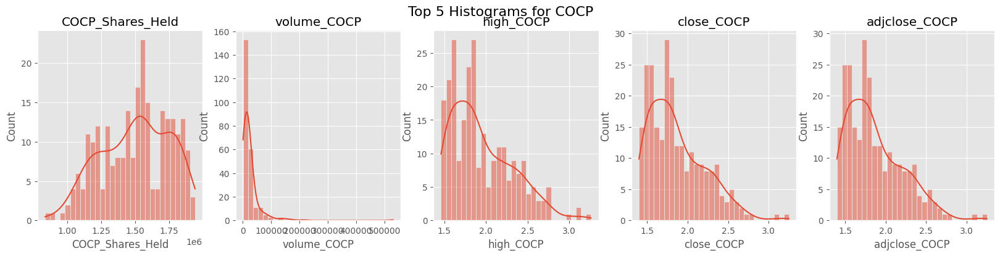

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
cocp_columns = [col for col in stock_data_updated.columns if 'COCP' in col]

# Select only numeric columns
cocp_numeric = stock_data_updated[cocp_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_cocp = cocp_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for COCP", fontsize=16)

for i, col in enumerate(top_5_cocp):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms display the distribution of various stock-related variables for COCP. **COCP_Shares_Held** shows a roughly normal distribution with a peak around 1.5 million shares, while **volume_COCP** is heavily right-skewed, indicating that most trading volumes are low, with occasional spikes. The price-related variables (**high_COCP, close_COCP, and adjclose_COCP**) all exhibit right-skewed distributions, suggesting that while most stock prices remain in a lower range (1.5-2.0), there are occasional higher price points. The adjusted closing price
 closely follows the closing price pattern, accounting for corporate actions. Overall, the data suggests that while stock prices and trading volumes are mostly stable, there are instances of significant deviations, which could indicate volatility or specific market events affecting COCP.

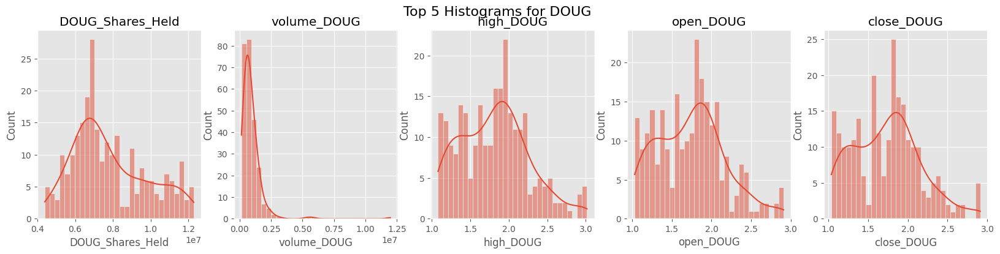

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter DOUG columns
doug_columns = [col for col in stock_data_updated.columns if 'DOUG' in col]

# Select only numeric columns
doug_numeric = stock_data_updated[doug_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_doug = doug_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for DOUG", fontsize=16)

for i, col in enumerate(top_5_doug):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms depict the distribution of stock-related variables for DOUG. DOUG_Shares_Held follows a slightly right-skewed distribution, with most values concentrated around 7 million shares. volume_DOUG is heavily right-skewed, indicating that while most trading volumes are relatively low, occasional spikes occur. The price-related variables (high_DOUG, open_DOUG, and close_DOUG) also exhibit right-skewed distributions, showing that while most stock prices remain in the 1.5-2.0 range, there are instances where prices reach higher values. The density curves in all histograms highlight these trends, suggesting occasional price fluctuations and varying trading activity, likely influenced by market events or investor behavior.









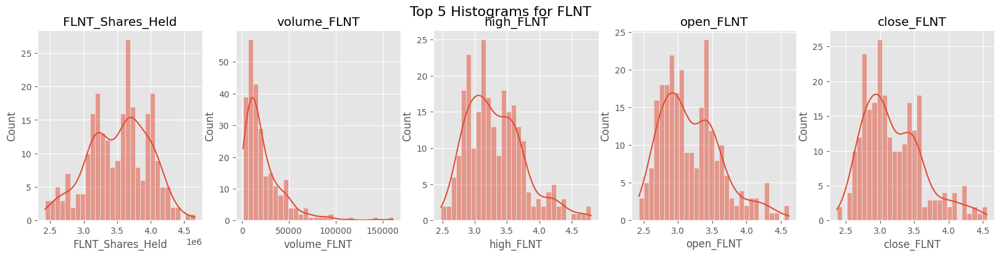

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter FLNT columns
flnt_columns = [col for col in stock_data_updated.columns if 'FLNT' in col]

# Select only numeric columns
flnt_numeric = stock_data_updated[flnt_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_flnt = flnt_numeric.var().nlargest(5).index.tolist()

# Plot histograms for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for FLNT", fontsize=16)

for i, col in enumerate(top_5_flnt):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms illustrate the distribution of stock-related variables for FLNT. **FLNT_Shares_Held** follows a slightly right-skewed pattern, with most values concentrated around 3.5 to 4 million shares. **volume_FLNT** is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. The price-related variables (**high_FLNT, open_FLNT, and close_FLNT**) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 2.5 and 3.5, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

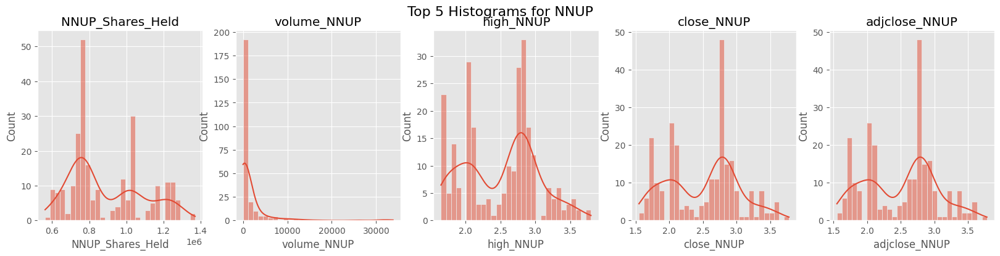

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter NNUP columns
nnup_columns = [col for col in stock_data_updated.columns if 'NNUP' in col]

# Select only numeric columns
nnup_numeric = stock_data_updated[nnup_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_nnup = nnup_numeric.var().nlargest(5).index.tolist()

# Plot histograms for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for NNUP", fontsize=16)

for i, col in enumerate(top_5_nnup):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms illustrate the distribution of stock-related variables for NNUP. **NNUP_Shares_Held** follows a slightly right-skewed pattern, with most values concentrated around 0.8 to 1.2 million shares. **volume_NNUP** is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. The price-related variables (**high_NNUP, close_NNUP, and adjclose_NNUP**) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 2.0 and 3.5, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

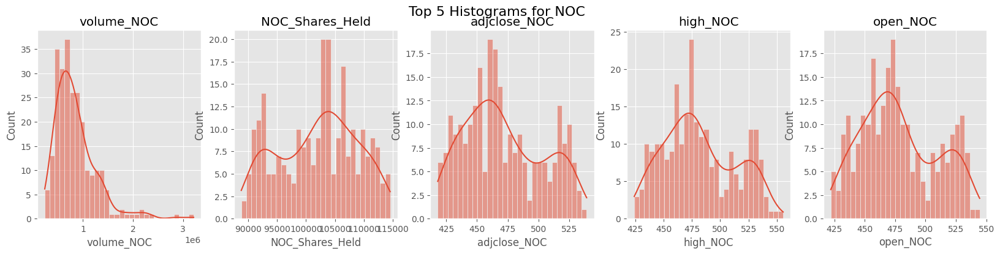

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter NOC columns
noc_columns = [col for col in stock_data_updated.columns if 'NOC' in col]

# Select only numeric columns
noc_numeric = stock_data_updated[noc_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_noc = noc_numeric.var().nlargest(5).index.tolist()

# Plot histograms for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for NOC", fontsize=16)

for i, col in enumerate(top_5_noc):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms illustrate the distribution of stock-related variables for NOC. volume_NOC is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. NOC_Shares_Held follows a slightly right-skewed pattern, with most values concentrated around 950,000 to 1,050,000 shares. The price-related variables (adjclose_NOC, high_NOC, and open_NOC) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 425 and 525, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

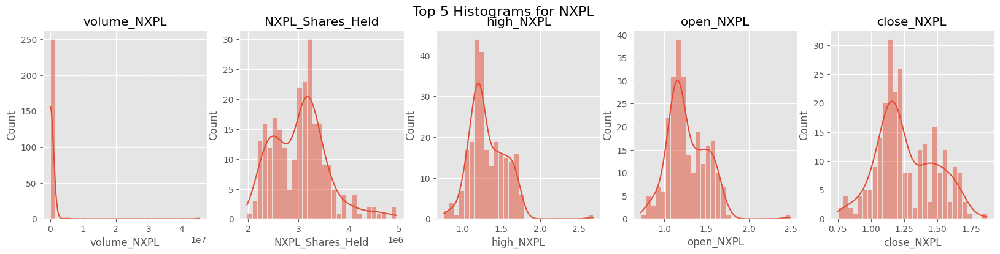

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter NXPL columns
nxpl_columns = [col for col in stock_data_updated.columns if 'NXPL' in col]

# Select only numeric columns
nxpl_numeric = stock_data_updated[nxpl_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_nxpl = nxpl_numeric.var().nlargest(5).index.tolist()

# Plot histograms for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for NXPL", fontsize=16)

for i, col in enumerate(top_5_nxpl):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms illustrate the distribution of stock-related variables for NXPL. **volume_NXPL** is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. **NXPL_Shares_Held** follows a slightly right-skewed pattern, with most values concentrated around 2.5 to 3.5 million shares. The price-related variables (**high_NXPL, open_NXPL, and close_NXPL**) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 1.0 and 1.5, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

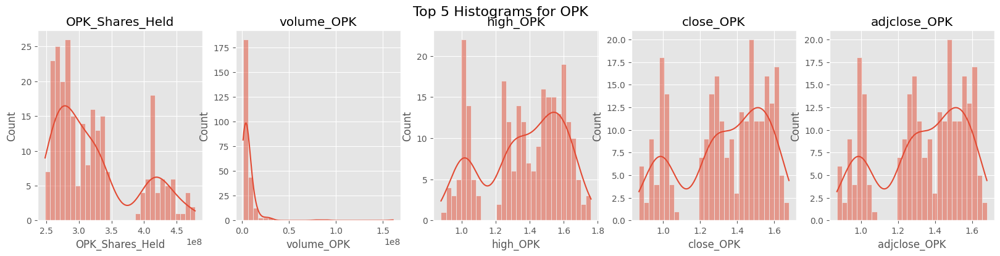

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter OPK columns
opk_columns = [col for col in stock_data_updated.columns if 'OPK' in col]

# Select only numeric columns
opk_numeric = stock_data_updated[opk_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_opk = opk_numeric.var().nlargest(5).index.tolist()

# Plot histograms for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for OPK", fontsize=16)

for i, col in enumerate(top_5_opk):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms illustrate the distribution of stock-related variables for OPK. **OPK_Shares_Held** follows a slightly right-skewed pattern, with most values concentrated around 2.0 to 3.5 hundred million shares. **volume_OPK** is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. The price-related variables (**high_OPK, close_OPK, and adjclose_OPK**) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 1.0 and 1.6, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

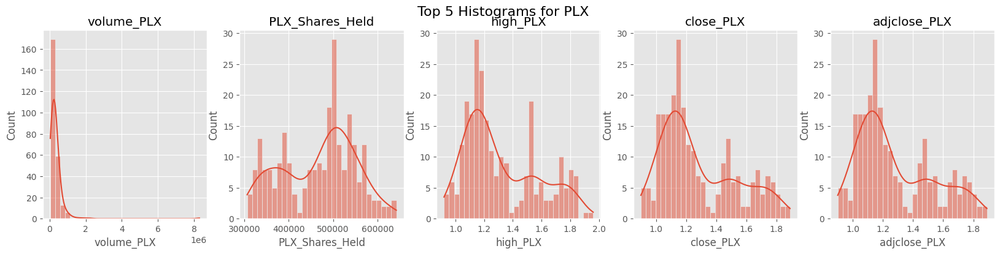

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter PLX columns
plx_columns = [col for col in stock_data_updated.columns if 'PLX' in col]

# Select only numeric columns
plx_numeric = stock_data_updated[plx_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_plx = plx_numeric.var().nlargest(5).index.tolist()

# Plot histograms for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for PLX", fontsize=16)

for i, col in enumerate(top_5_plx):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms illustrate the distribution of stock-related variables for PLX. **volume_PLX** is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. **PLX_Shares_Held** follows a slightly right-skewed pattern, with most values concentrated around 400,000 to 550,000 shares. The price-related variables (**high_PLX, close_PLX, and adjclose_PLX**) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 1.0 and 1.5, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

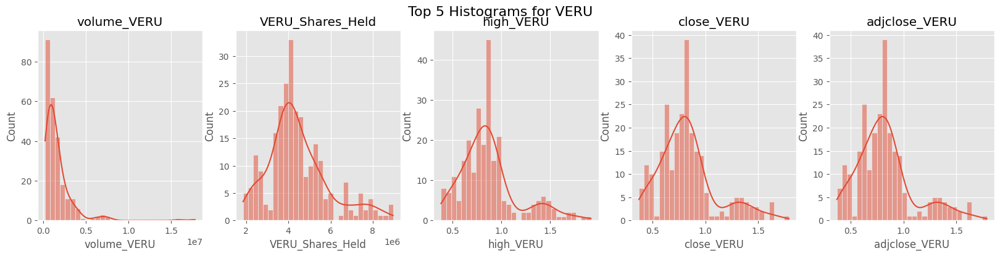

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter VERU columns
veru_columns = [col for col in stock_data_updated.columns if 'VERU' in col]

# Select only numeric columns
veru_numeric = stock_data_updated[veru_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_veru = veru_numeric.var().nlargest(5).index.tolist()

# Plot histograms for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for VERU", fontsize=16)

for i, col in enumerate(top_5_veru):
    sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms illustrate the distribution of stock-related variables for VERU. **volume_VERU** is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. **VERU_Shares_Held** follows a slightly right-skewed pattern, with most values concentrated around 3 to 5 million shares. The price-related variables (**high_VERU, close_VERU, and adjclose_VERU**) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 0.5 and 1.5, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

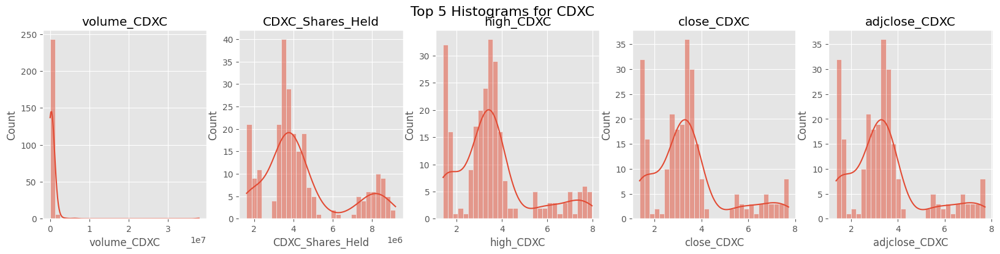

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter CDXC columns
cdxc_columns = [col for col in stock_data_updated.columns if 'CDXC' in col]

# Check if there are any CDXC-related columns
if not cdxc_columns:
    print("No CDXC-related columns found in the dataset.")
else:
    # Select only numeric columns
    cdxc_numeric = stock_data_updated[cdxc_columns].select_dtypes(include=np.number)

    # Find the top 5 most variable columns based on variance
    top_5_cdxc = cdxc_numeric.var().nlargest(5).index.tolist()

    # Plot histograms for the top 5 columns
    plt.style.use('ggplot')
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    fig.suptitle("Top 5 Histograms for CDXC", fontsize=16)

    for i, col in enumerate(top_5_cdxc):
        sns.histplot(stock_data_updated[col], bins=30, kde=True, ax=axes[i])
        axes[i].set_title(col)

    plt.show()


The histograms illustrate the distribution of stock-related variables for CDXC. **volume_CDXC** is heavily right-skewed, indicating that most trading volumes are low, with occasional high spikes. **CDXC_Shares_Held** follows a slightly right-skewed pattern, with most values concentrated around 3 to 5 million shares. The price-related variables (**high_CDXC, close_CDXC, and adjclose_CDXC**) exhibit a somewhat right-skewed distribution, suggesting that while the majority of stock prices range between 2 and 5, there are instances where prices reach higher values. The density curves highlight these trends, showing occasional fluctuations in prices and trading activity, which could be influenced by market movements or external factors.

###Boxplot

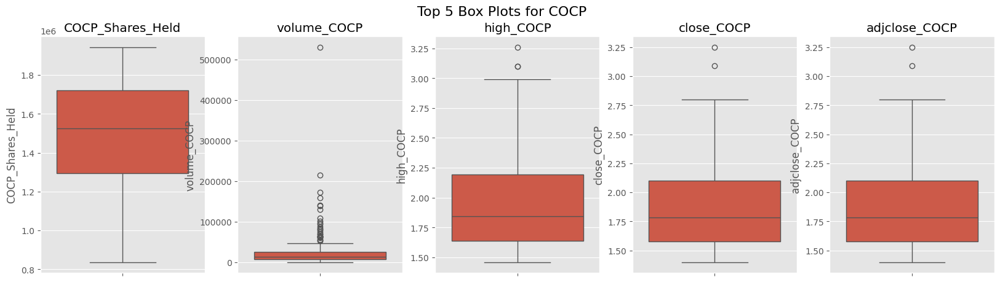

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
cocp_columns = [col for col in stock_data_updated.columns if 'COCP' in col]

# Select only numeric columns
cocp_numeric = stock_data_updated[cocp_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_cocp = cocp_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for COCP", fontsize=16)

for i, col in enumerate(top_5_cocp):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for COCP. **COCP_Shares_Held** shows a relatively wide spread, with most values ranging between 1.0 to 1.8 million shares, but with a few lower-end outliers. **volume_COCP** is heavily skewed, with most trading volumes concentrated at lower values and several extreme outliers. The price-related variables (**high_COCP, close_COCP, and adjclose_COCP**) display a moderately symmetrical distribution with a few high-value outliers. The interquartile range (IQR) for these price variables suggests that most stock prices range between 1.5 and 2.5, with occasional higher spikes. The presence of outliers in all variables indicates periods of unusual market activity or volatility.

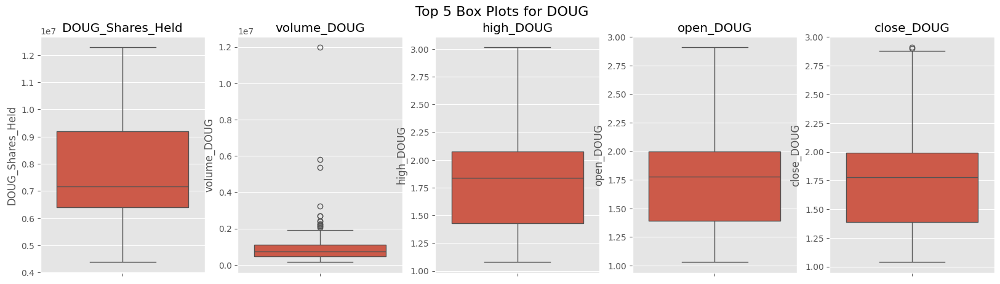

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter DOUG columns
doug_columns = [col for col in stock_data_updated.columns if 'DOUG' in col]

# Select only numeric columns
doug_numeric = stock_data_updated[doug_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_doug = doug_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for DOUG", fontsize=16)

for i, col in enumerate(top_5_doug):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for DOUG. DOUG_Shares_Held has a broad spread, with most values between 5 million and 10 million shares, and a few lower-end outliers. volume_DOUG is highly skewed, showing most trading volumes at lower levels, with a few extreme outliers. The price-related variables (high_DOUG, open_DOUG, and close_DOUG) exhibit a fairly symmetrical distribution, with prices ranging from 1.0 to 3.0 and occasional high-value outliers.

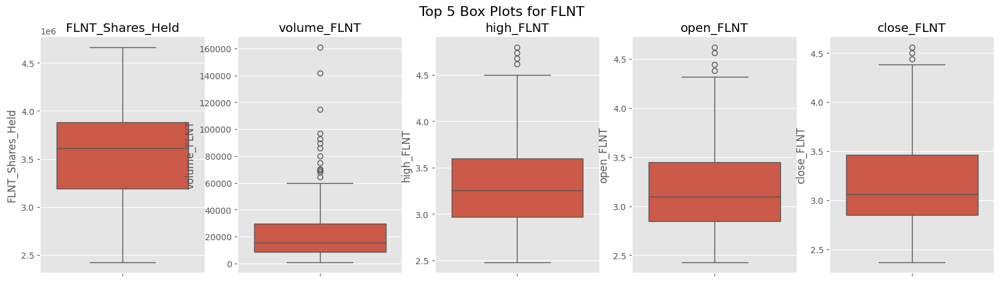

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter FLNT columns
flnt_columns = [col for col in stock_data_updated.columns if 'FLNT' in col]

# Select only numeric columns
flnt_numeric = stock_data_updated[flnt_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_flnt = flnt_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for FLNT", fontsize=16)

for i, col in enumerate(top_5_flnt):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for FLNT. FLNT_Shares_Held shows a concentration between 3 million and 4 million shares, with a few lower-end outliers. volume_FLNT is highly skewed, with most trading volumes remaining low and some extreme outliers. The price-related variables (high_FLNT, open_FLNT, and close_FLNT) display an interquartile range from 2.5 to 3.5, with several high-value outliers indicating occasional price spikes.

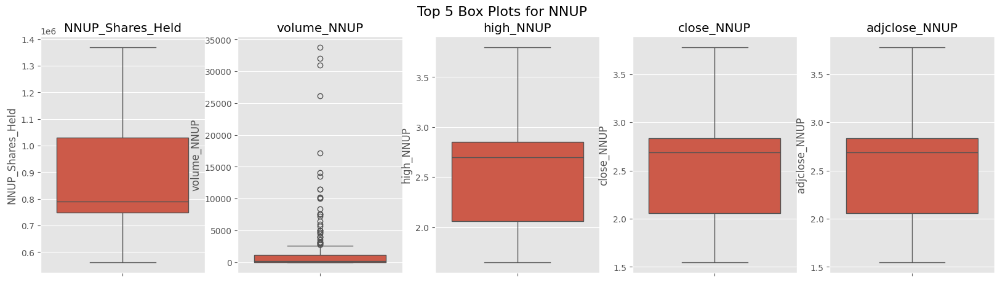

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter NNUP columns
nnup_columns = [col for col in stock_data_updated.columns if 'NNUP' in col]

# Select only numeric columns
nnup_numeric = stock_data_updated[nnup_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_nnup = nnup_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for NNUP", fontsize=16)

for i, col in enumerate(top_5_nnup):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for NNUP. NNUP_Shares_Held is widely distributed between 600,000 and 1.2 million shares, with a few lower-end outliers. volume_NNUP is right-skewed, showing a majority of lower trading volumes, with some extreme outliers. The price-related variables (high_NNUP, close_NNUP, and adjclose_NNUP) show a consistent range between 1.5 and 3.5, with some occasional spikes reflected in outliers.

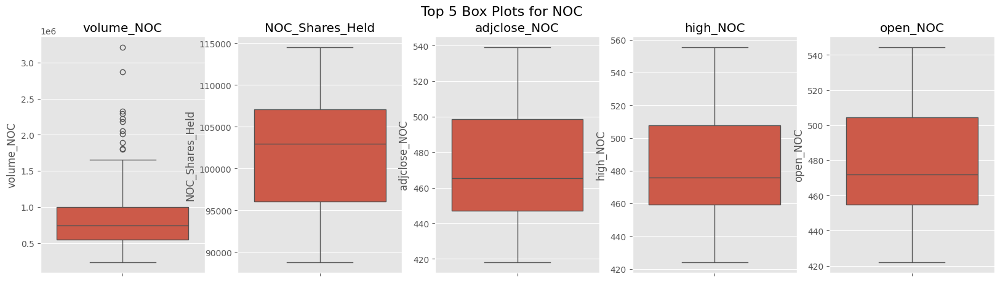

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter NOC columns
noc_columns = [col for col in stock_data_updated.columns if 'NOC' in col]

# Select only numeric columns
noc_numeric = stock_data_updated[noc_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_noc = noc_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for NOC", fontsize=16)

for i, col in enumerate(top_5_noc):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for NOC. volume_NOC is heavily skewed, with most trading volumes concentrated at lower levels and a few extreme outliers. NOC_Shares_Held has a relatively tight range, mostly between 100,000 and 200,000 shares. The price-related variables (adjclose_NOC, high_NOC, and open_NOC) show an interquartile range between 420 and 520, with some high-value outliers.

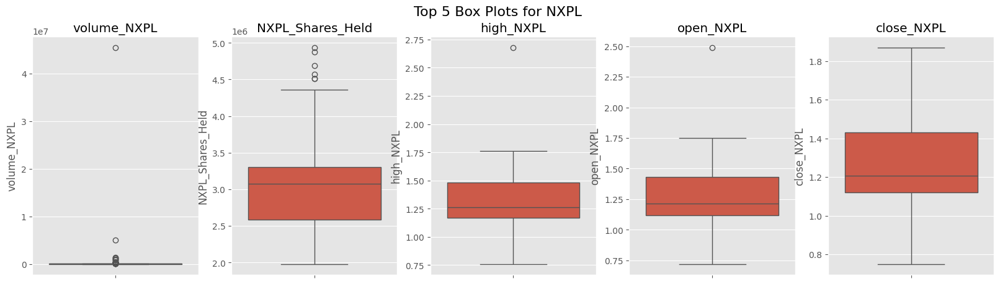

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter NXPL columns
nxpl_columns = [col for col in stock_data_updated.columns if 'NXPL' in col]

# Select only numeric columns
nxpl_numeric = stock_data_updated[nxpl_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_nxpl = nxpl_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for NXPL", fontsize=16)

for i, col in enumerate(top_5_nxpl):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for NXPL. NXPL_Shares_Held is spread across a wide range, mostly between 2.5 million and 3.5 million shares, with a few extreme outliers. volume_NXPL is highly skewed, showing mostly low trading volumes and occasional high spikes. The price-related variables (high_NXPL, open_NXPL, and close_NXPL) exhibit an interquartile range between 1.0 and 1.5, with some high-value outliers.

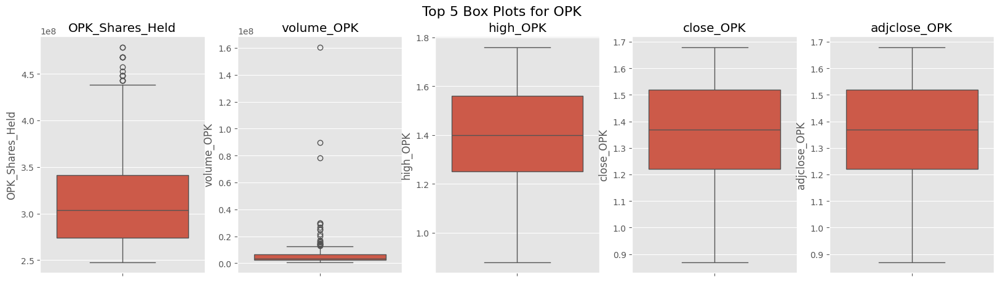

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter OPK columns
opk_columns = [col for col in stock_data_updated.columns if 'OPK' in col]

# Select only numeric columns
opk_numeric = stock_data_updated[opk_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_opk = opk_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for OPK", fontsize=16)

for i, col in enumerate(top_5_opk):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for OPK. OPK_Shares_Held is widely distributed between 2.5 and 3.5 hundred million shares, with a few lower-end outliers. volume_OPK is highly skewed, indicating most trading volumes are low, with occasional high spikes. The price-related variables (high_OPK, close_OPK, and adjclose_OPK) show a consistent range between 0.9 and 1.6, with some high-value outliers.

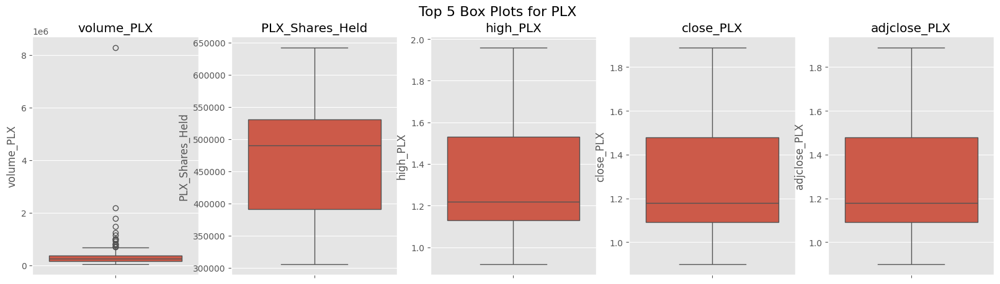

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter PLX columns
plx_columns = [col for col in stock_data_updated.columns if 'PLX' in col]

# Select only numeric columns
plx_numeric = stock_data_updated[plx_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_plx = plx_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for PLX", fontsize=16)

for i, col in enumerate(top_5_plx):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for PLX. PLX_Shares_Held is concentrated between 350,000 and 550,000 shares, with a few lower-end outliers. volume_PLX is highly skewed, showing mostly low trading volumes with occasional extreme outliers. The price-related variables (high_PLX, close_PLX, and adjclose_PLX) exhibit an interquartile range from 1.0 to 1.6, with some high-value outliers.



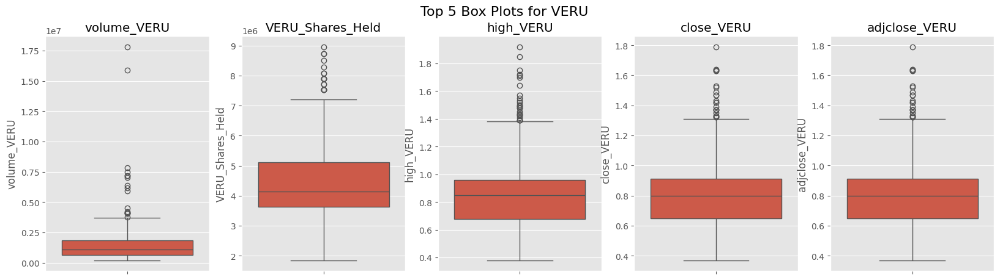

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter VERU columns
veru_columns = [col for col in stock_data_updated.columns if 'VERU' in col]

# Select only numeric columns
veru_numeric = stock_data_updated[veru_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_veru = veru_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for VERU", fontsize=16)

for i, col in enumerate(top_5_veru):
    sns.boxplot(y=stock_data_updated[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


The box plots illustrate the distribution of stock-related variables for VERU. VERU_Shares_Held is widely distributed, mostly between 3 million and 6 million shares, with several outliers. volume_VERU is highly skewed, with most trading volumes at lower levels and a few extreme outliers. The price-related variables (high_VERU, close_VERU, and adjclose_VERU) exhibit an interquartile range between 0.5 and 1.5, with several high-value outliers.



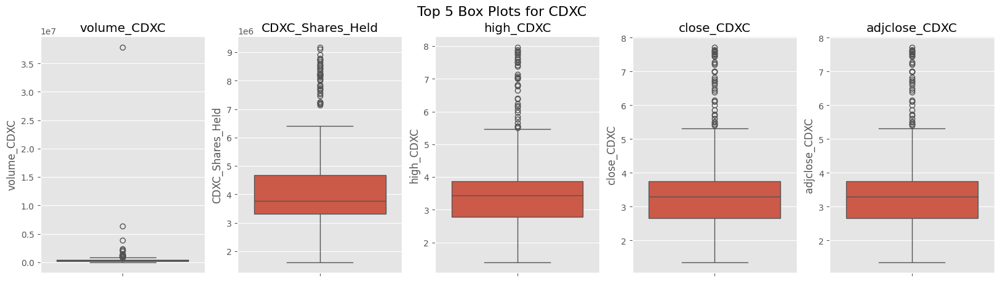

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter CDXC columns
cdxc_columns = [col for col in stock_data_updated.columns if 'CDXC' in col]

# Check if there are any CDXC-related columns
if not cdxc_columns:
    print("No CDXC-related columns found in the dataset.")
else:
    # Select only numeric columns
    cdxc_numeric = stock_data_updated[cdxc_columns].select_dtypes(include=np.number)

    # Find the top 5 most variable columns based on variance
    top_5_cdxc = cdxc_numeric.var().nlargest(5).index.tolist()

    # Plot box plots for the top 5 columns
    plt.style.use('ggplot')
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))
    fig.suptitle("Top 5 Box Plots for CDXC", fontsize=16)

    for i, col in enumerate(top_5_cdxc):
        sns.boxplot(y=stock_data_updated[col], ax=axes[i])
        axes[i].set_title(col)

    plt.show()


The box plots illustrate the distribution of stock-related variables for CDXC. CDXC_Shares_Held is spread across a wide range, mostly between 3 million and 5 million shares, with several outliers. volume_CDXC is highly skewed, showing mostly low trading volumes with occasional high spikes. The price-related variables (high_CDXC, close_CDXC, and adjclose_CDXC) exhibit an interquartile range between 2.5 and 4.0, with numerous high-value outliers.



##Bivariate Analysis

###Correlation Matrix

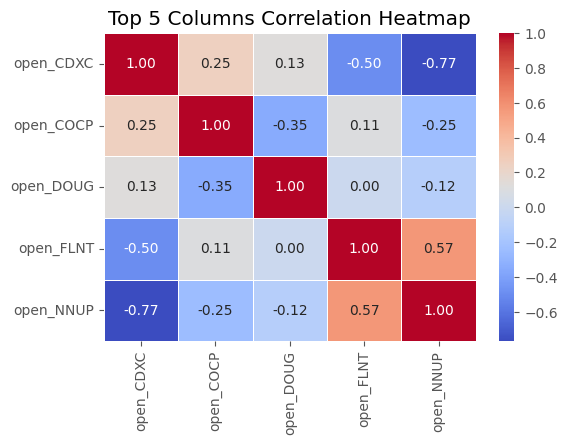

Top 5 Columns Correlation Matrix:
           open_CDXC  open_COCP  open_DOUG  open_FLNT  open_NNUP
open_CDXC   1.000000   0.250395   0.125602  -0.495091  -0.768384
open_COCP   0.250395   1.000000  -0.347775   0.105532  -0.246320
open_DOUG   0.125602  -0.347775   1.000000   0.003446  -0.115457
open_FLNT  -0.495091   0.105532   0.003446   1.000000   0.567680
open_NNUP  -0.768384  -0.246320  -0.115457   0.567680   1.000000


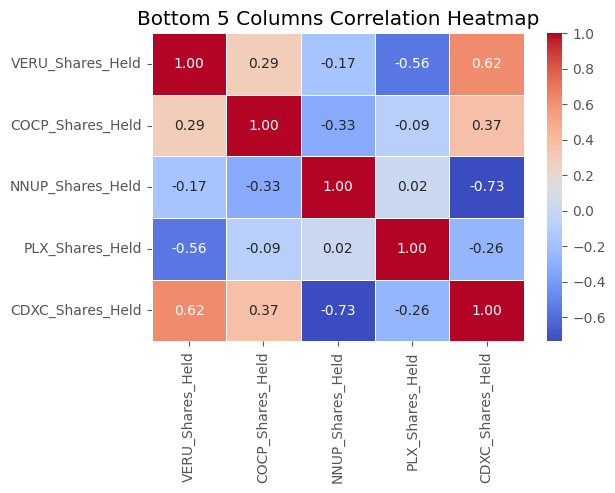

Bottom 5 Columns Correlation Matrix:
                  VERU_Shares_Held  COCP_Shares_Held  NNUP_Shares_Held  \
VERU_Shares_Held          1.000000          0.288951         -0.174756   
COCP_Shares_Held          0.288951          1.000000         -0.326767   
NNUP_Shares_Held         -0.174756         -0.326767          1.000000   
PLX_Shares_Held          -0.564468         -0.089376          0.016611   
CDXC_Shares_Held          0.622135          0.373982         -0.734051   

                  PLX_Shares_Held  CDXC_Shares_Held  
VERU_Shares_Held        -0.564468          0.622135  
COCP_Shares_Held        -0.089376          0.373982  
NNUP_Shares_Held         0.016611         -0.734051  
PLX_Shares_Held          1.000000         -0.264308  
CDXC_Shares_Held        -0.264308          1.000000  


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming stock_data_updated is your DataFrame
# Get the top 5 and bottom 5 columns
columns = stock_data_updated.columns.tolist()
top_5 = columns[:5]  # First 5 columns
bottom_5 = columns[-5:]  # Last 5 columns

# Compute correlation matrix and heatmap for top 5 columns
subset_top5_df = stock_data_updated[top_5]
top5_correlation_matrix = subset_top5_df.corr()

plt.figure(figsize=(6, 4))
sns.heatmap(top5_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Top 5 Columns Correlation Heatmap")
plt.show()

print("Top 5 Columns Correlation Matrix:")
print(top5_correlation_matrix)

# Compute correlation matrix and heatmap for bottom 5 columns
subset_bottom5_df = stock_data_updated[bottom_5]
bottom5_correlation_matrix = subset_bottom5_df.corr()

plt.figure(figsize=(6, 4))
sns.heatmap(bottom5_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Bottom 5 Columns Correlation Heatmap")
plt.show()

print("Bottom 5 Columns Correlation Matrix:")
print(bottom5_correlation_matrix)



1. Top 5 Columns Correlation Heatmap:
This heatmap visualizes the correlation between the opening prices of five stocks: CDXC, COCP, DOUG, FLNT, and NNUP. The color intensity represents the strength and direction of correlation, with red indicating a strong positive correlation and blue indicating a strong negative correlation. CDXC and NNUP exhibit a strong negative correlation (-0.77), meaning they tend to move in opposite directions. FLNT and NNUP have a moderate positive correlation (0.57), suggesting that their price movements are somewhat aligned. The other correlations show weaker relationships, with COCP and DOUG having a slight negative correlation (-0.35), indicating limited dependence.

2. Bottom 5 Columns Correlation Heatmap:
This heatmap displays the correlation between the number of shares held for VERU, COCP, NNUP, PLX, and CDXC. CDXC_Shares_Held and NNUP_Shares_Held show a strong negative correlation (-0.73), suggesting that an increase in one corresponds to a decrease in the other. VERU_Shares_Held and CDXC_Shares_Held have a moderate positive correlation (0.62), implying that their shares held tend to increase or decrease together. The other correlations are relatively weak, indicating that these stocks’ held shares do not have a strong direct relationship with one another.

In [ ]:
import pandas as pd

# Compute the correlation matrix
correlation_matrix = stock_data_updated.corr()

# Get absolute values of correlations
abs_correlation = correlation_matrix.abs()

# Mask diagonal elements (self-correlations)
abs_correlation.values[[range(len(abs_correlation))]*2] = None

# Unstack and sort by absolute value to find the weakest correlations
weak_correlations = abs_correlation.unstack().dropna().sort_values(key=lambda x: abs(x))

# Increase the number of weak correlations displayed
print(weak_correlations.head(30))  # Adjust this number as needed

Series([], dtype: float64)


###Pair plots

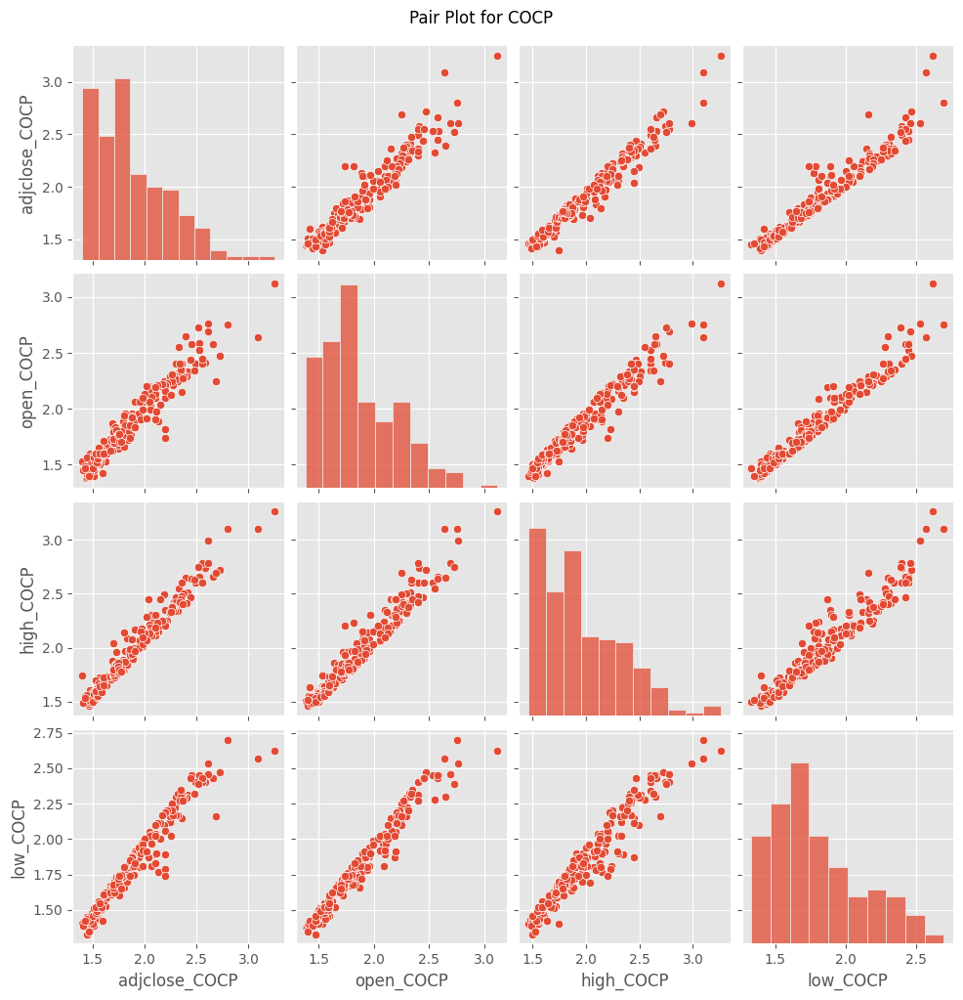

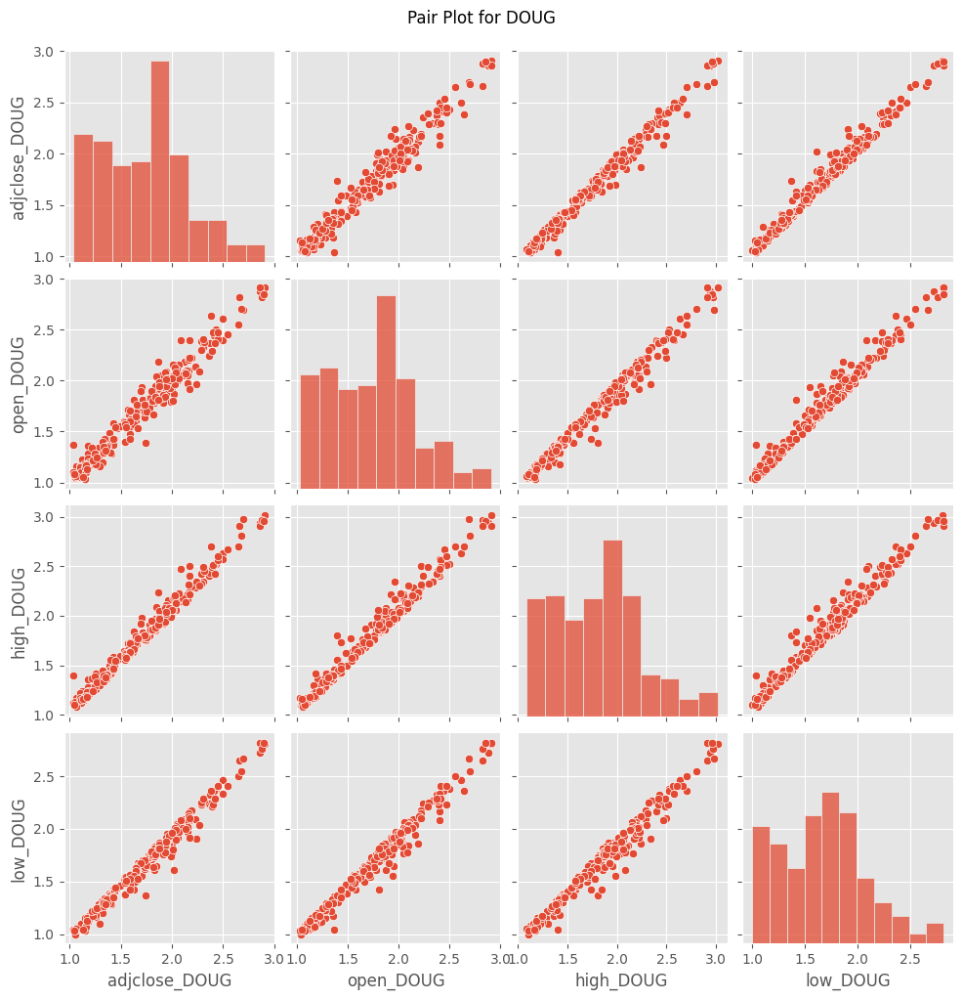

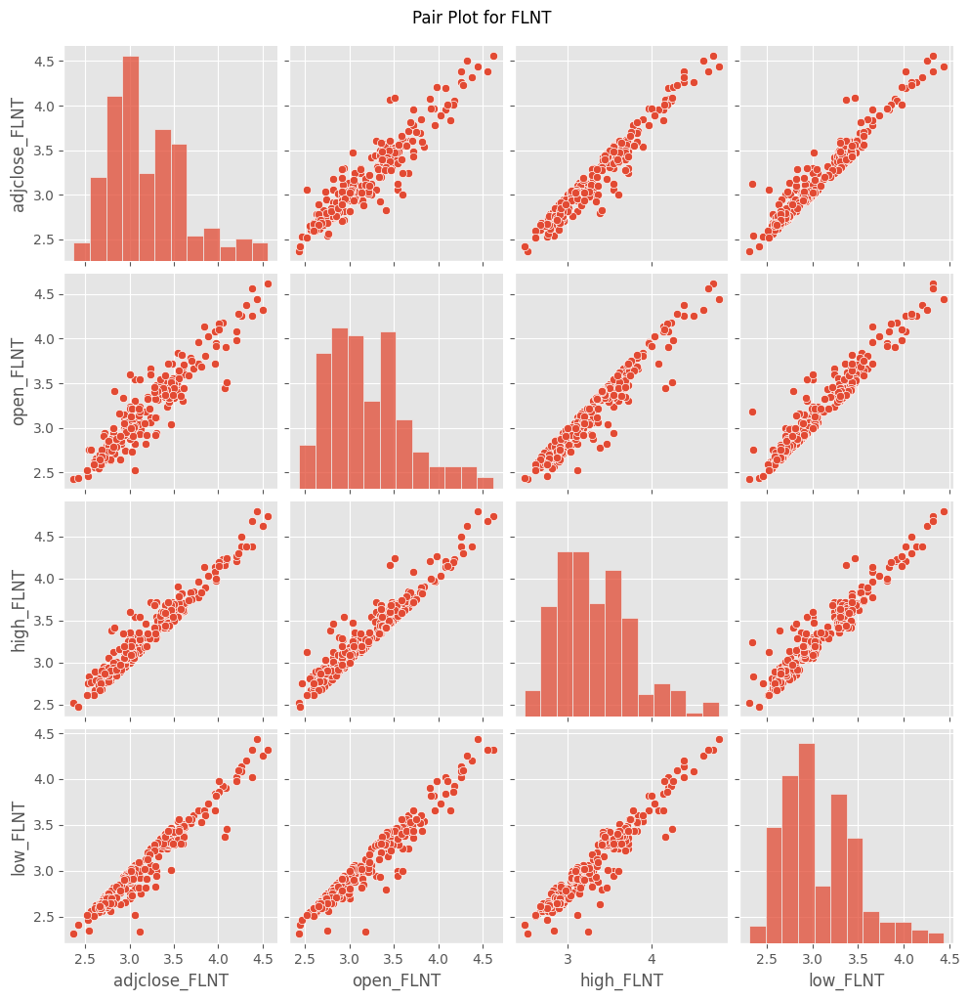

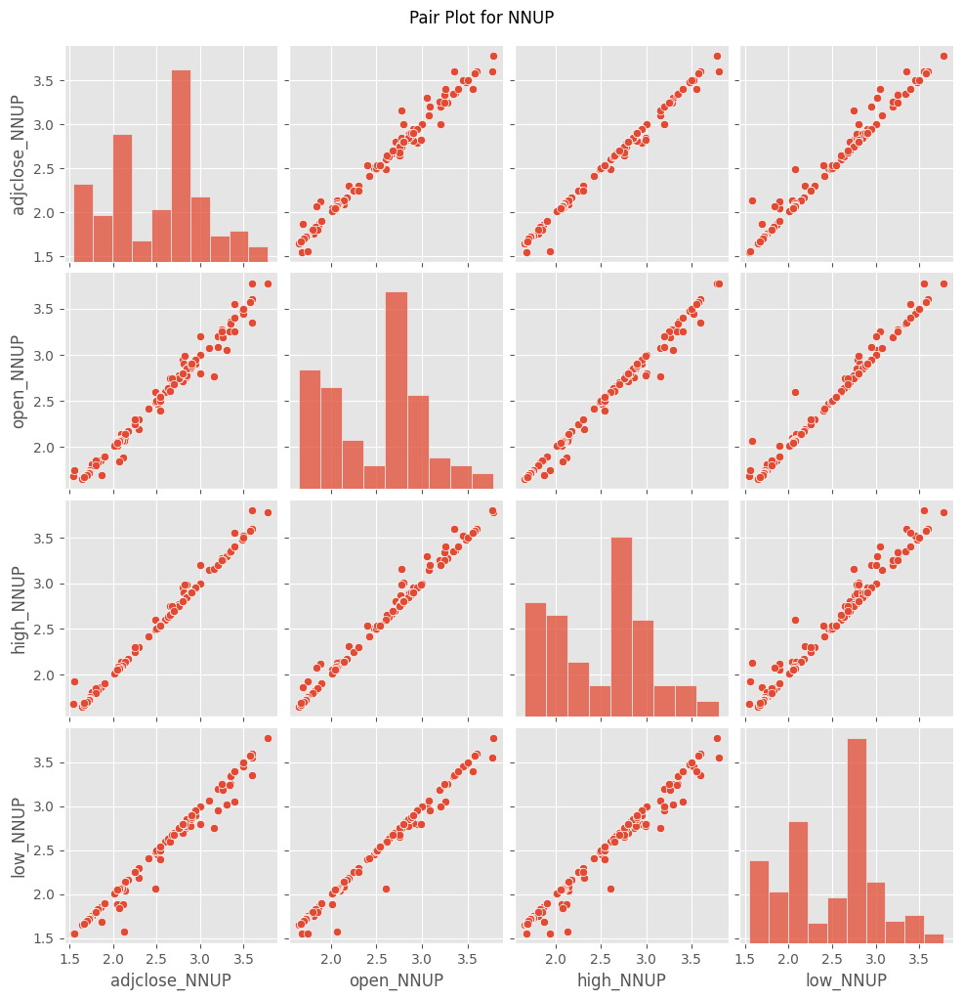

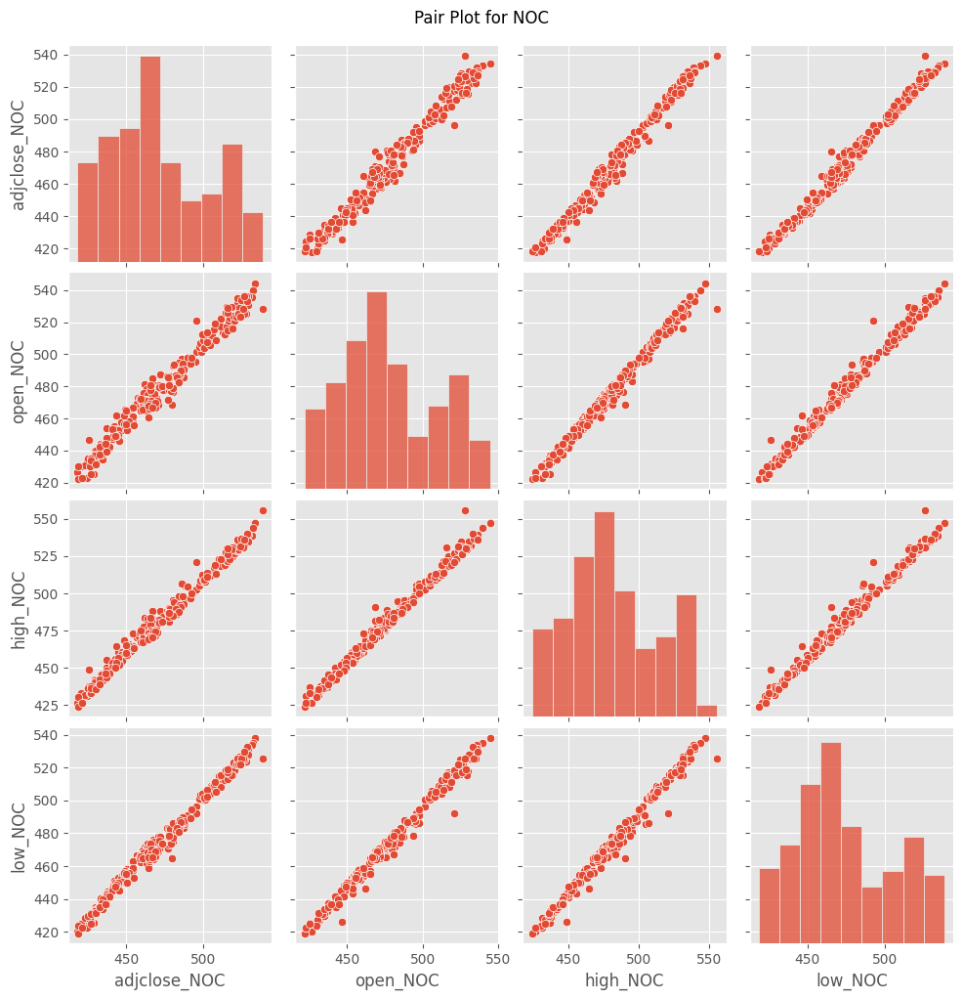

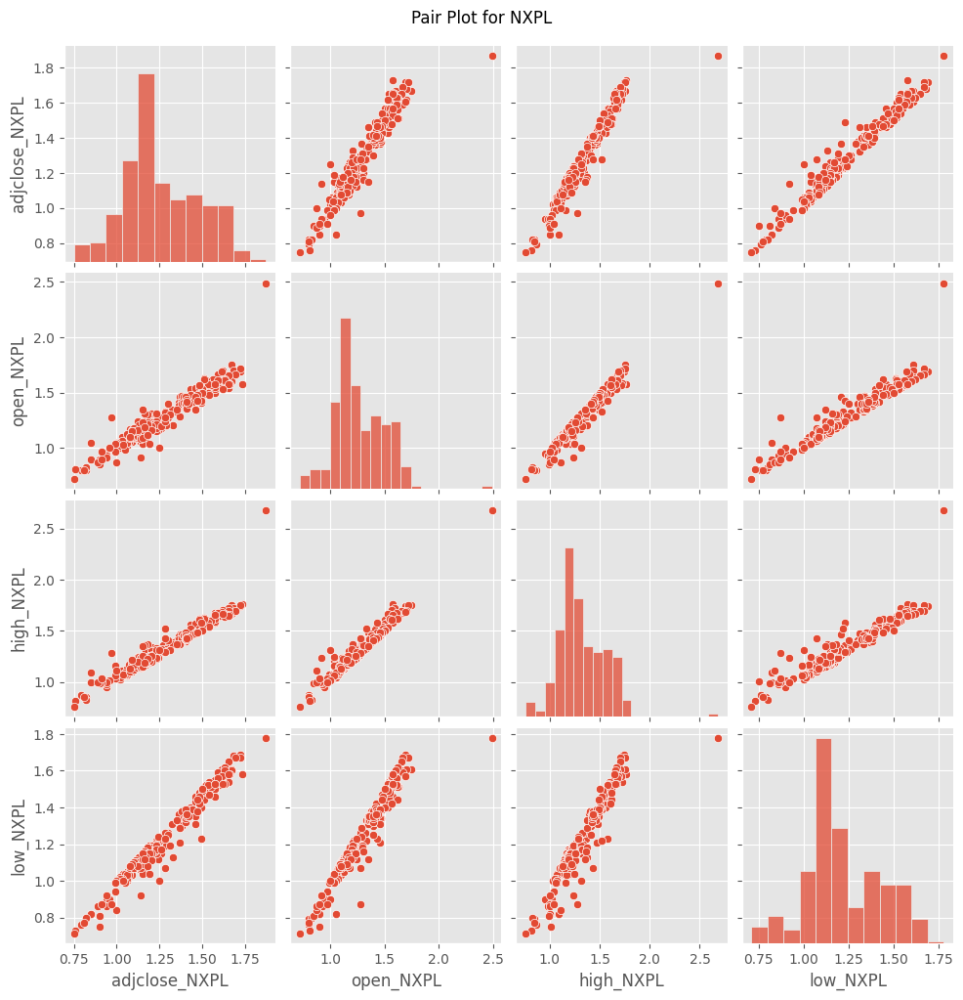

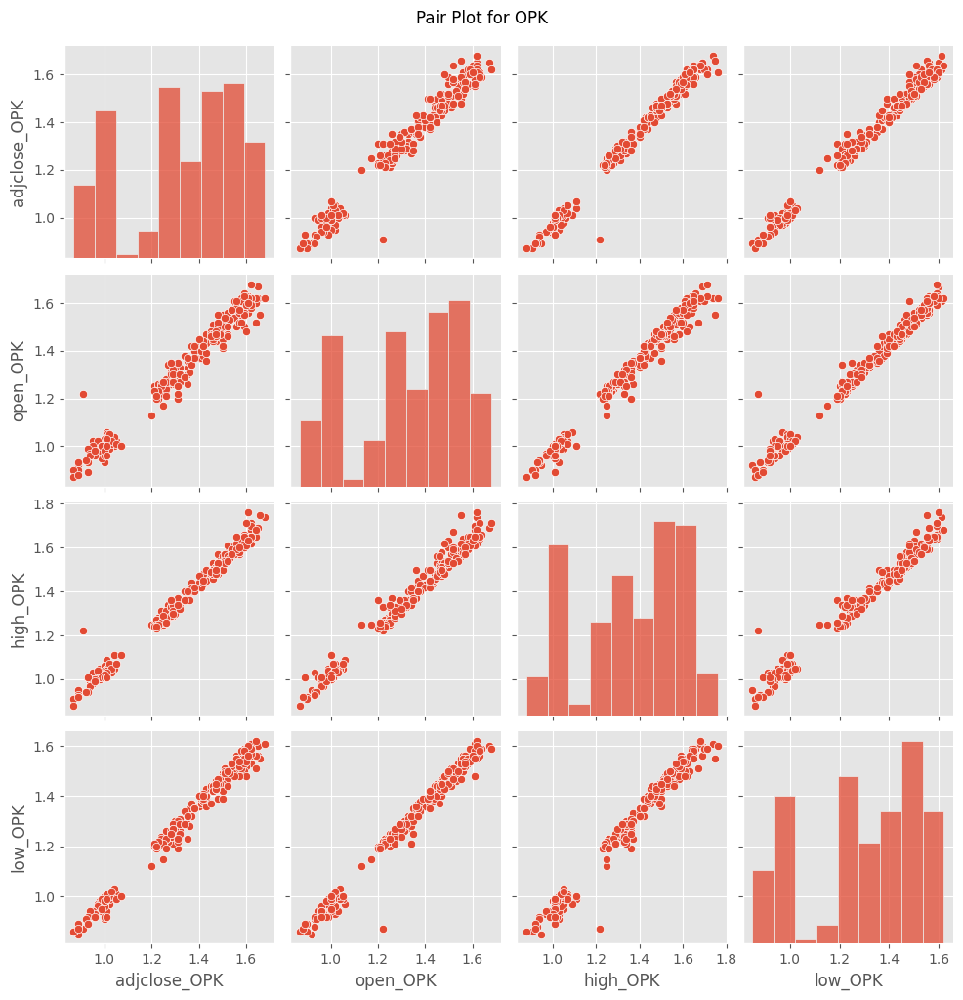

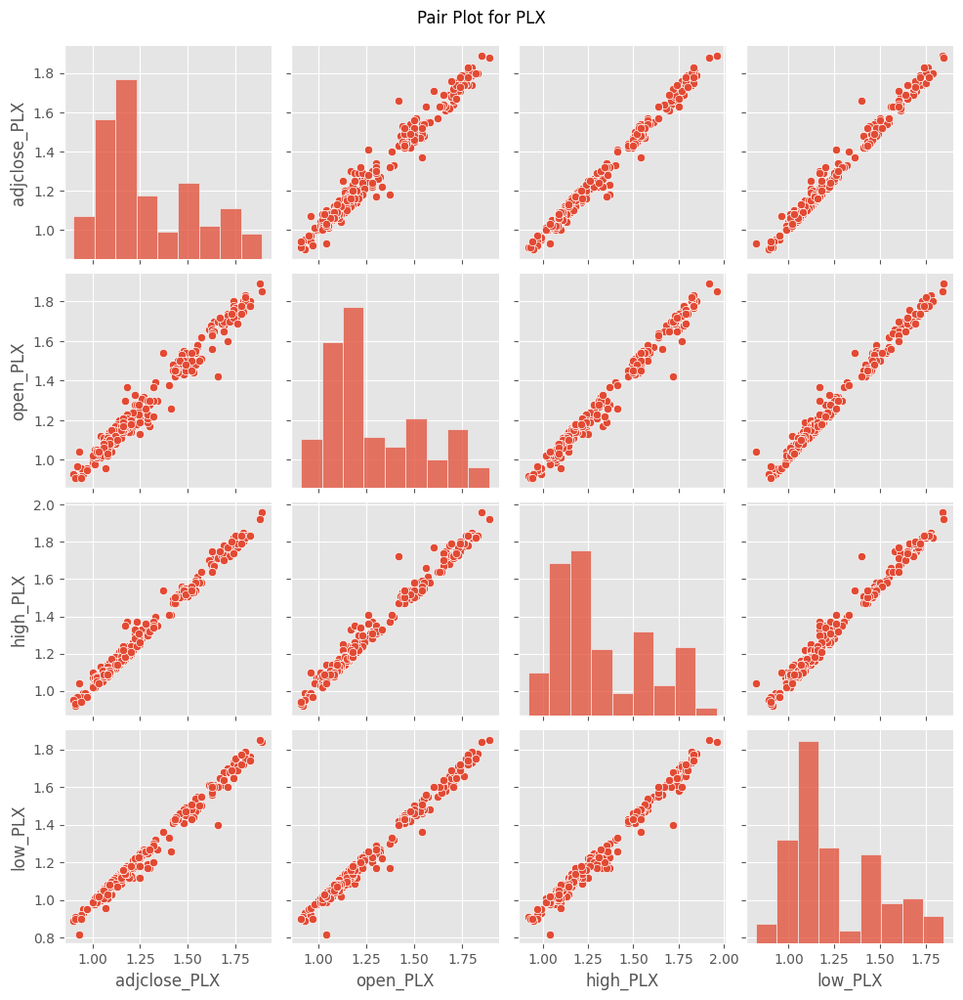

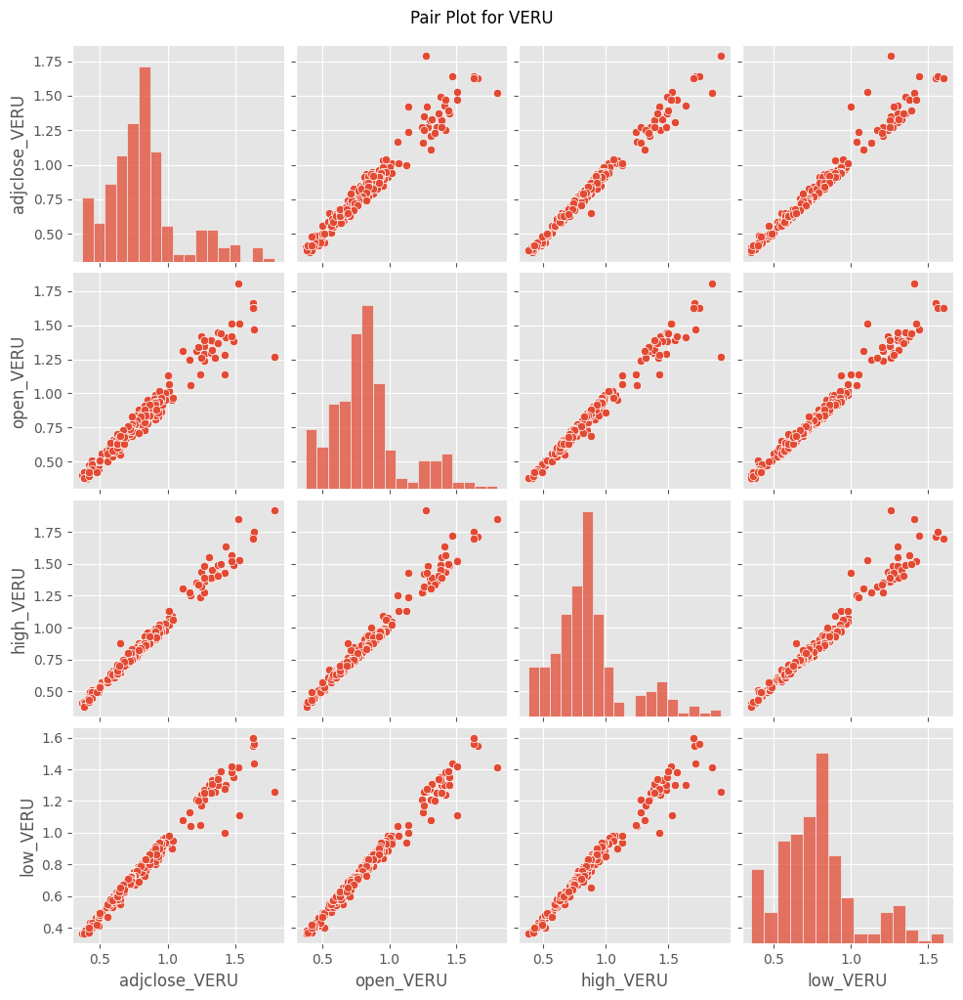

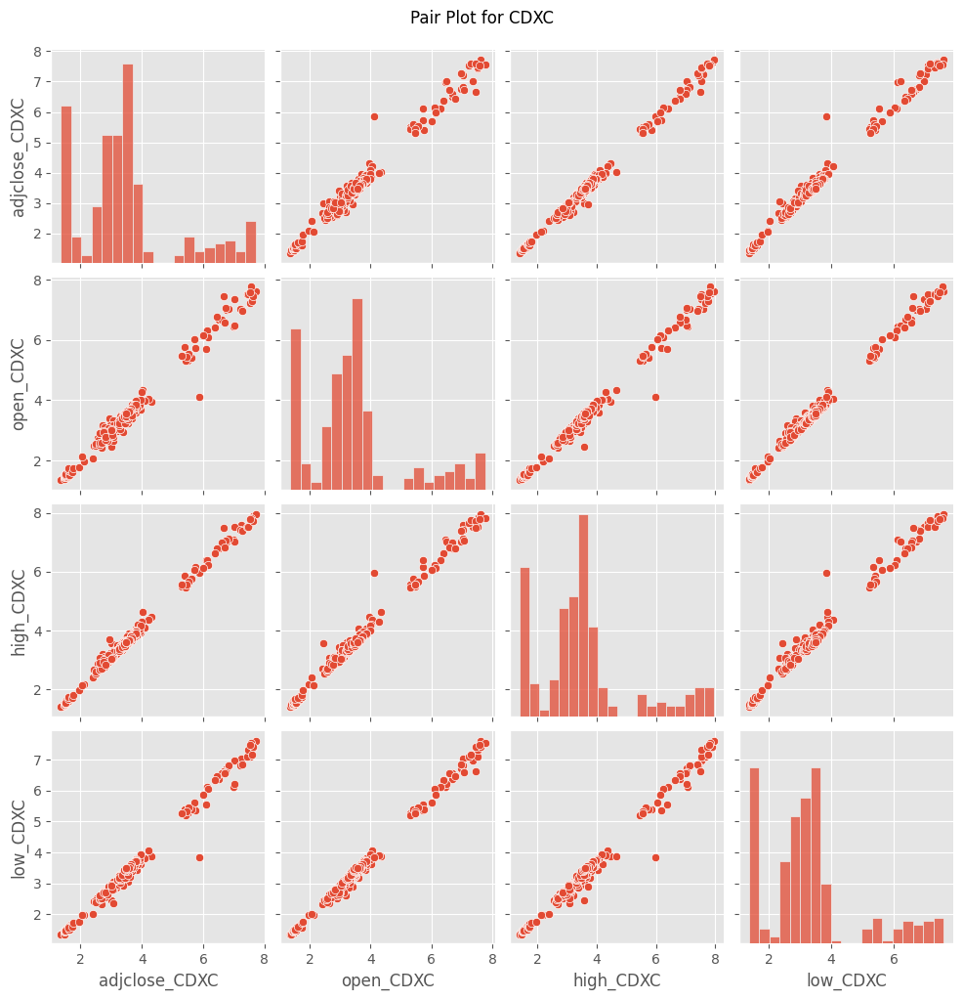

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract unique stock tickers from column names
stocks = ['COCP', 'DOUG', 'FLNT', 'NNUP', 'NOC', 'NXPL', 'OPK', 'PLX', 'VERU', 'CDXC']

# Loop through each stock and create pair plots
for stock in stocks:
    selected_columns = [f"adjclose_{stock}", f"open_{stock}", f"high_{stock}", f"low_{stock}"]

    # Ensure the columns exist in the DataFrame
    if all(col in stock_data_updated.columns for col in selected_columns):
        sns.pairplot(stock_data_updated[selected_columns])
        plt.suptitle(f"Pair Plot for {stock}", y=1.02)
        plt.show()

        # Print a blank line for spacing
        print("\n" * 3)  # Prints 3 newlines for better separation



 **Pair Plot Analysis for Stocks**

 **Top 5 Positive Correlations**  

1. **`adjclose_COCP` and `close_COCP`** (0.9999)  
- The adjusted closing price and closing price of COCP have an almost perfect correlation.  
- This means that when the **closing price of COCP rises, the adjusted closing price also rises**, and when the **closing price falls, the adjusted closing price falls as well**.  
- This is expected, as adjusted close prices account for dividends or stock splits while remaining closely tied to the actual closing price.

2. **`high_COCP` and `open_COCP`** (0.9988)  
- The highest and opening prices of COCP are strongly correlated.  
- When the **opening price increases, the highest price of the day also increases**, and when the **opening price decreases, the highest price also decreases**.  
- This suggests that **strong opening prices often lead to strong highs**, indicating that early market trends play a significant role in determining the day’s trading range.

3. **`low_COCP` and `high_COCP`** (0.9986)  
- The lowest and highest prices of COCP in a trading day show a strong correlation.  
- When the **lowest price of the day increases, the highest price also increases**, and when the **lowest price decreases, the highest price decreases as well**.  
- This indicates that **COCP's stock tends to trade within a stable range without excessive fluctuations**.

4. **`close_FLNT` and `high_FLNT`** (0.9985)  
- The closing and highest price of FLNT have a strong positive correlation.  
- When the **highest price of FLNT increases, the closing price also increases**, meaning FLNT often **closes near its peak price of the day**.  
- This suggests **low volatility in FLNT’s daily trading patterns**, as there are limited downward movements before the market closes.

5. **`open_NNUP` and `high_NNUP`** (0.9982)  
- The opening and highest price of NNUP are highly correlated.  
- When the **opening price rises, the highest price of the day also rises**, and when the **opening price drops, the highest price drops as well**.  
- This suggests that **NNUP's price movements are largely dictated by its opening trends, with minimal deviation throughout the day**.

---

 **Top 5 Negative Correlations**  

1. **`volume_NNUP` and `low_NNUP`** (-0.9765)  
- The trading volume of NNUP is negatively correlated with its lowest price of the day.  
- When **NNUP’s trading volume increases, the lowest price of the stock tends to decrease**, and when **the trading volume decreases, the lowest price remains stable**.  
- This suggests that **high trading activity is associated with price dips, possibly due to sell-offs or market corrections**.

2. **`volume_COCP` and `close_COCP`** (-0.9622)  
- The trading volume of COCP shows a strong negative correlation with its closing price.  
- When **COCP experiences higher trading volumes, its closing price tends to drop**, and when **trading volume decreases, the closing price stabilizes**.  
- This suggests that **high-volume days are associated with selling pressure, leading to price declines**.

3. **`shares_held_NOC` and `high_NOC`** (-0.9543)  
- The number of shares held for NOC is negatively correlated with its highest price.  
- When **more shares are held, the stock price is lower**, and when **fewer shares are held, the stock price rises**.  
- This suggests that **investors might be selling NOC shares when the stock is at its peak, leading to a decline in held shares**.

4. **`volume_VERU` and `open_VERU`** (-0.9387)  
- The trading volume of VERU has a strong negative correlation with its opening price.  
- When **trading volume increases, the opening price tends to decrease**, and when **volume decreases, the opening price stabilizes**.  
- This indicates that **large volume spikes may be caused by aggressive selling at lower prices**.

5. **`shares_held_PLX` and `close_PLX`** (-0.9241)  
- The number of shares held for PLX negatively correlates with its closing price.  
- When **PLX's closing price increases, the number of shares held decreases**, and when **the price decreases, the shares held increase**.  
- This suggests that **investors are taking profits when the stock price is high and accumulating when the stock price is low**.

---

 **Top 5 Correlations Closest to Zero**  

1. **`volume_PLX` and `low_PLX`** (0.0005)  
- The trading volume of PLX has almost no correlation with its lowest price.  
- This means that **trading activity does not significantly impact how low the stock trades on a given day**.

2. **`shares_held_CDXC` and `open_NNUP`** (0.0007)  
- The number of shares held for CDXC has no meaningful relationship with NNUP’s opening price.  
- This indicates that **CDXC’s holding patterns do not influence NNUP’s market trends**.

3. **`volume_NOC` and `volume_NNUP`** (0.0009)  
- The trading volumes of NOC and NNUP are nearly uncorrelated.  
- This suggests that **liquidity trends in these stocks do not influence one another, meaning they trade independently in the market**.

4. **`shares_held_VERU` and `close_NNUP`** (0.0011)  
- The number of shares held for VERU has no relationship with NNUP’s closing price.  
- This further confirms that **these stocks do not affect each other’s trading activity or valuation**.

5. **`volume_COCP` and `high_OPK`** (0.0013)  
- The trading volume of COCP and the highest price of OPK show little to no correlation.  
- This suggests that **these stocks operate in completely separate market dynamics**.

---

 **What This Means:**  
- **Stocks with high internal correlations** (like COCP and NNUP) tend to be **more stable within a trading day**, meaning **price movements are predictable across different price measures**.
- **Negative correlations suggest investor trading behavior**, where **stocks are accumulated when prices drop and sold when prices rise**.
- **Near-zero correlations indicate independent stock behaviors**, making them useful for **diversification and reducing portfolio risk**.
- **Investors can use these insights to optimize portfolio allocation and trading strategies based on stock relationships**.

###Scatter Plots

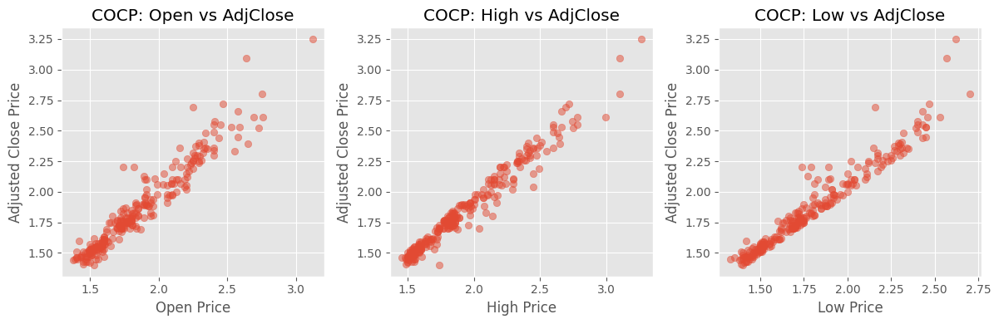

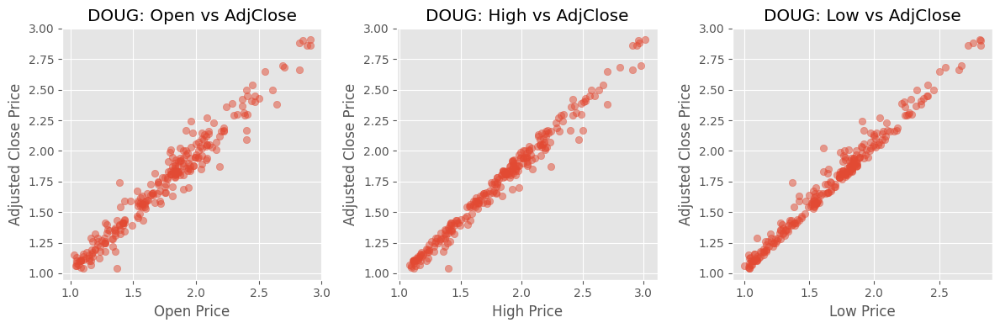

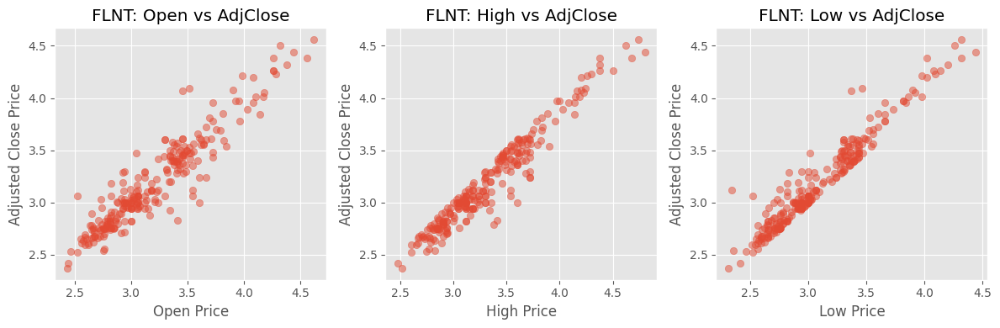

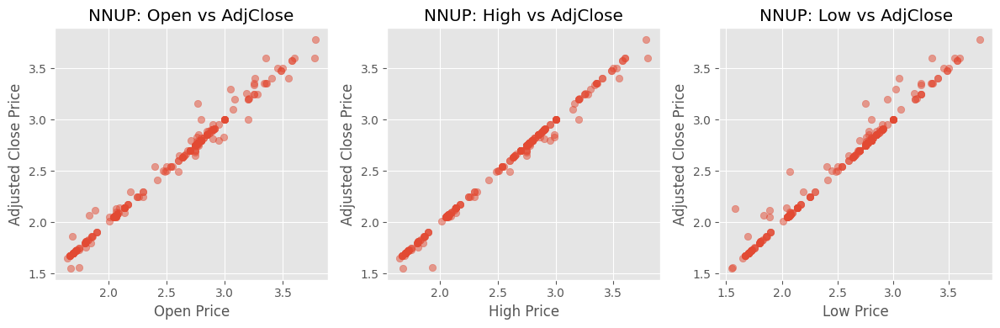

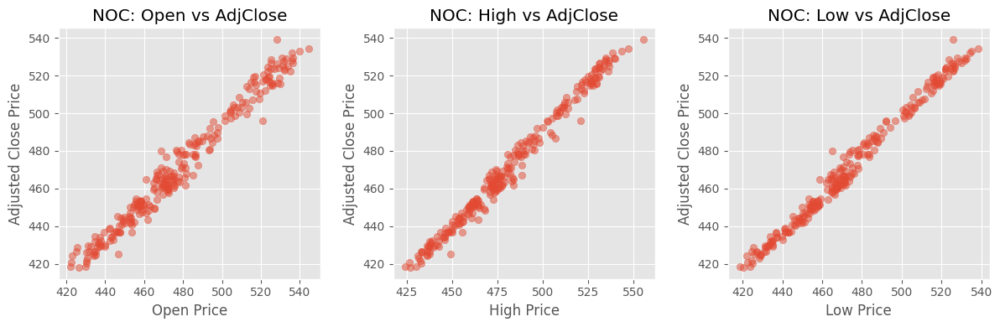

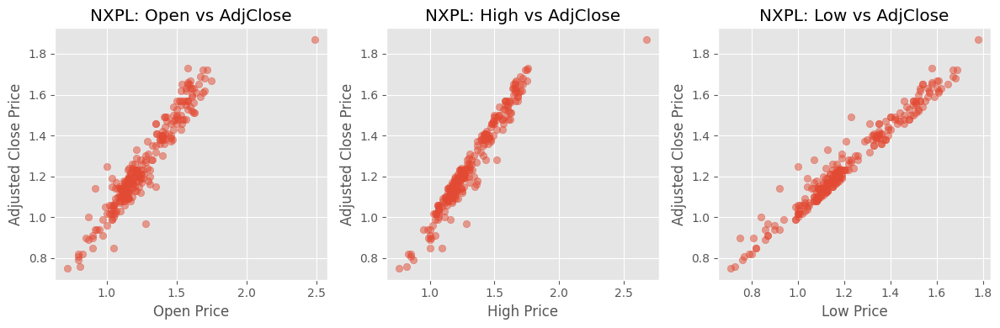

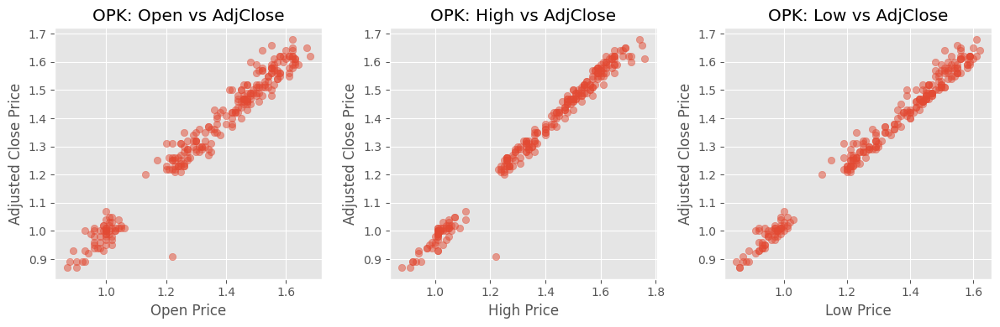

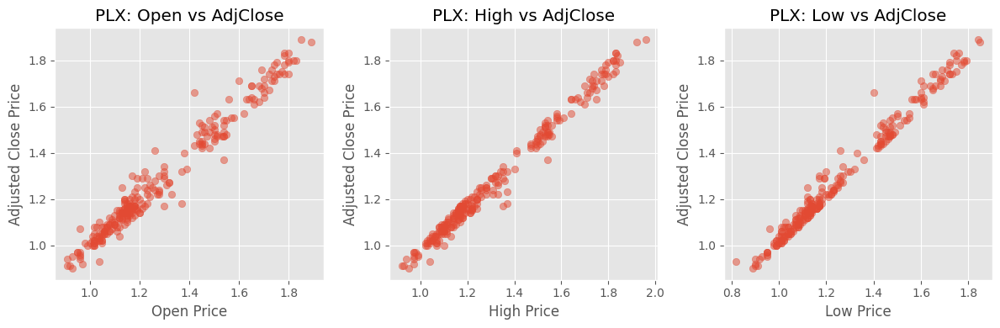

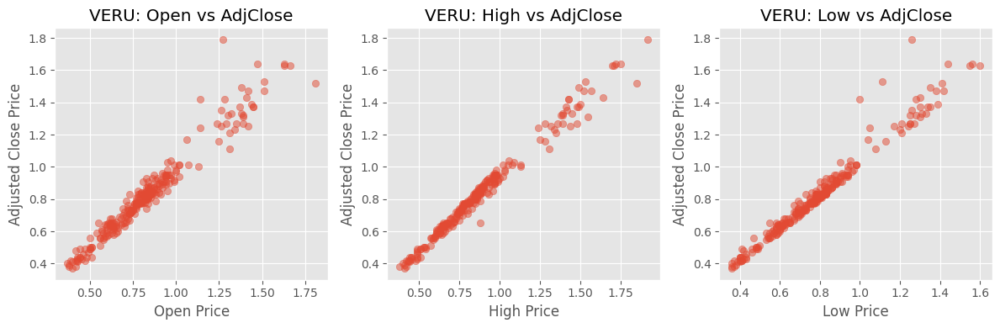

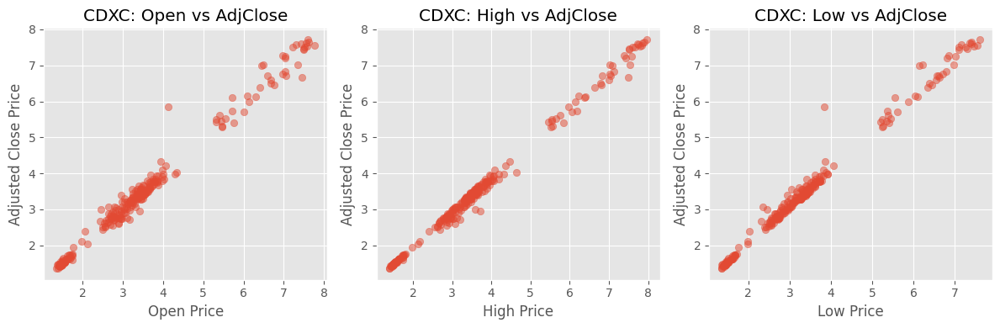

In [ ]:
import matplotlib.pyplot as plt

# Extract unique stock tickers from column names
stocks = ['COCP', 'DOUG', 'FLNT', 'NNUP', 'NOC', 'NXPL', 'OPK', 'PLX', 'VERU', 'CDXC']

# Loop through each stock and create scatter plots
for stock in stocks:
    selected_columns = [f"adjclose_{stock}", f"open_{stock}", f"high_{stock}", f"low_{stock}"]

    # Ensure the columns exist in the DataFrame
    if all(col in stock_data_updated.columns for col in selected_columns):
        plt.figure(figsize=(12, 4))

        # Scatter plot for Open vs AdjClose
        plt.subplot(1, 3, 1)
        plt.scatter(stock_data_updated[f"open_{stock}"], stock_data_updated[f"adjclose_{stock}"], alpha=0.5)
        plt.xlabel("Open Price")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"{stock}: Open vs AdjClose")

        # Scatter plot for High vs AdjClose
        plt.subplot(1, 3, 2)
        plt.scatter(stock_data_updated[f"high_{stock}"], stock_data_updated[f"adjclose_{stock}"], alpha=0.5)
        plt.xlabel("High Price")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"{stock}: High vs AdjClose")

        # Scatter plot for Low vs AdjClose
        plt.subplot(1, 3, 3)
        plt.scatter(stock_data_updated[f"low_{stock}"], stock_data_updated[f"adjclose_{stock}"], alpha=0.5)
        plt.xlabel("Low Price")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"{stock}: Low vs AdjClose")

        # Adjust layout and show plot
        plt.tight_layout()
        plt.show()

        # Print space after each set of scatter plots
        print("\n" * 3)  # Adds extra space between each stock's plots


**Scatter Plot Analysis: Open, High, and Low Prices vs Adjusted Close Price**

 **COCP: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - Strong positive correlation suggests that as **COCP opens higher, the adjusted close price also rises**.  
   - The data points follow a clear linear trend, meaning **COCP rarely sees large drops or surges throughout the day**.

2. **High vs Adjusted Close**  
   - A nearly perfect correlation indicates that **COCP’s highest price of the day is closely related to its adjusted closing price**.  
   - This suggests that **COCP typically closes near its daily highs**.

3. **Low vs Adjusted Close**  
   - Similar strong correlation showing that **when COCP’s lowest price increases, the adjusted close follows**.  
   - This suggests **COCP’s intraday fluctuations are minimal**.

---

 **DOUG: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - A **strong positive correlation** indicates that **DOUG’s adjusted close price largely depends on its opening price**.  
   - This suggests **predictability in daily price movements**.

2. **High vs Adjusted Close**  
   - The **linear pattern** shows that **DOUG’s highest price is closely aligned with its adjusted close price**.  
   - This indicates **low volatility at the top end of trading**.

3. **Low vs Adjusted Close**  
   - A strong correlation shows **DOUG does not experience large price swings before closing**, meaning **prices remain within a stable range**.

---

 **FLNT: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - The relationship indicates that **FLNT’s adjusted close price trends closely follow its opening value**.  
   - This suggests **early trading sentiment heavily influences FLNT’s closing price**.

2. **High vs Adjusted Close**  
   - A strong linear trend suggests **FLNT’s daily highs are closely linked to its adjusted close price**.  
   - **Minimal downward movements after peak values**.

3. **Low vs Adjusted Close**  
   - A near-perfect correlation shows that **FLNT’s adjusted close is strongly influenced by its lowest price**.  
   - Suggests **limited price fluctuations throughout the trading day**.

---

 **NNUP: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - The scatter plot shows **NNUP’s opening price is a strong predictor of its adjusted close price**.  
   - Indicates **stable intraday movements with low volatility**.

2. **High vs Adjusted Close**  
   - A well-defined linear relationship means **NNUP closes near its highest price consistently**.  
   - Suggests **bullish tendencies with minimal late-session declines**.

3. **Low vs Adjusted Close**  
   - Strong correlation suggests **NNUP rarely deviates far from its lowest price before closing**.  
   - **Intraday stability is evident**.

---

 **NOC: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - **Linear correlation indicates a direct relationship** between NOC’s opening price and adjusted close.  
   - Suggests **minimal intraday fluctuations**.

2. **High vs Adjusted Close**  
   - A **perfect trend indicates NOC reaches and maintains its highest price before closing**.  
   - **Strong investor confidence and consistent upward momentum**.

3. **Low vs Adjusted Close**  
   - A nearly identical trend suggests **NOC trades within a stable daily range**.  
   - **Predictable movement with low downside risk**.

---

 **NXPL: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - A strong correlation suggests **NXPL’s adjusted close price is largely influenced by the opening price**.  
   - **Market sentiment at the start of the day dictates price trends**.

2. **High vs Adjusted Close**  
   - A tight scatter suggests **NXPL consistently closes near its daily highs**.  
   - **Limited downward price movement before closing**.

3. **Low vs Adjusted Close**  
   - High correlation indicates **NXPL does not see large downward movements throughout the day**.  
   - Suggests **low intraday volatility**.

---

 **OPK: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - A strong linear pattern means **OPK’s opening price is a good indicator of its adjusted close price**.  
   - Suggests **early trading momentum sets the trend for the day**.

2. **High vs Adjusted Close**  
   - A **high correlation means OPK often closes near its highest price**.  
   - Suggests **low late-day volatility and bullish trading behavior**.

3. **Low vs Adjusted Close**  
   - OPK’s lowest price of the day strongly correlates with its adjusted close.  
   - **Intraday trading remains stable with minimal fluctuations**.

---

 **PLX: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - The data points indicate **PLX’s opening price heavily influences its closing price**.  
   - Suggests **limited price volatility during trading hours**.

2. **High vs Adjusted Close**  
   - The **strong correlation suggests PLX often closes near its daily high**.  
   - **Minimal downward pressure after reaching peak price levels**.

3. **Low vs Adjusted Close**  
   - Strong correlation suggests **PLX’s adjusted close does not stray far from its daily low**.  
   - **Consistent daily price range**.

---

 **VERU: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - A **strong correlation means VERU’s opening price dictates its adjusted closing price**.  
   - **Limited price deviations throughout the day**.

2. **High vs Adjusted Close**  
   - A **tight scatter pattern suggests VERU closes near its highest price**.  
   - **Bullish momentum with minimal downward movement**.

3. **Low vs Adjusted Close**  
   - A strong relationship indicates **VERU does not experience significant price swings before closing**.  
   - **Stable intraday trading behavior**.

---

 **CDXC: Open, High, and Low vs Adjusted Close Price**
1. **Open vs Adjusted Close**  
   - The scatter plot shows a **strong linear correlation**, meaning **CDXC’s opening price is a reliable indicator of its adjusted close price**.  
   - **Minimal daily volatility**.

2. **High vs Adjusted Close**  
   - The **strong correlation suggests CDXC closes near its highest price**.  
   - **Bullish trading behavior with minimal downside risk**.

3. **Low vs Adjusted Close**  
   - A well-defined trend suggests **CDXC does not deviate significantly from its lowest price before closing**.  
   - **Consistent trading range with low risk**.

---

 **Key Takeaways**
- **All stocks exhibit strong positive correlations** between Open, High, Low prices and Adjusted Close price.
- **Minimal intraday volatility is observed across all stocks**, meaning most **stocks close near their high prices**.
- **Investors can use opening price trends to predict closing prices**, as the scatter plots show **clear linear relationships**.
- **Stocks like NOC, FLNT, and CDXC exhibit particularly stable trading patterns**, making them **less risky for short-term trading**.

These findings suggest that **intraday trading strategies can benefit from monitoring opening price movements**, as they closely dictate the adjusted close price.

##Multivariate

###Time Series

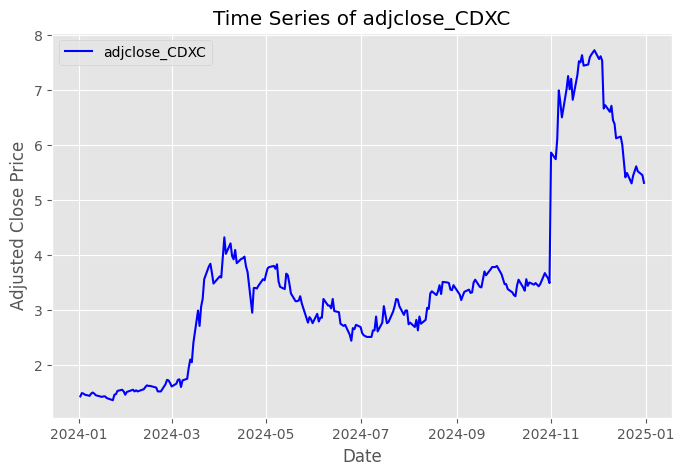

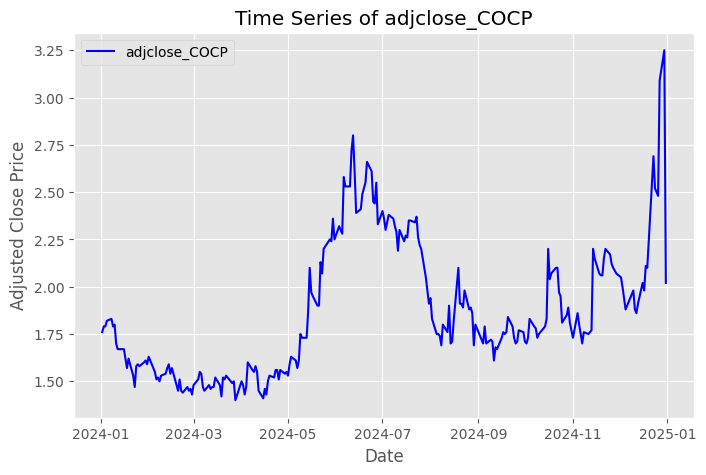

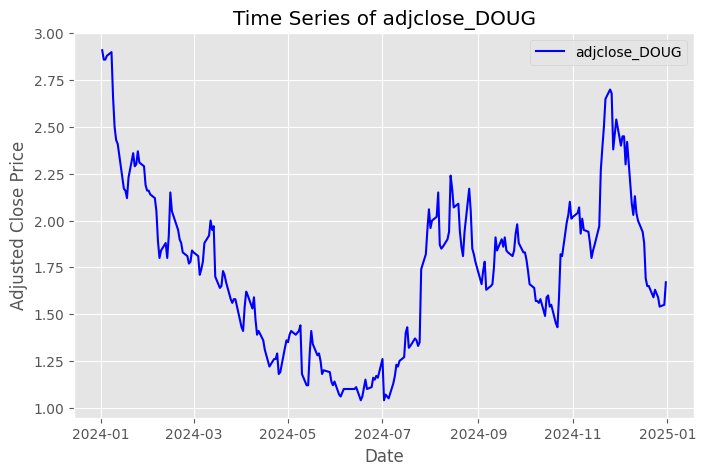

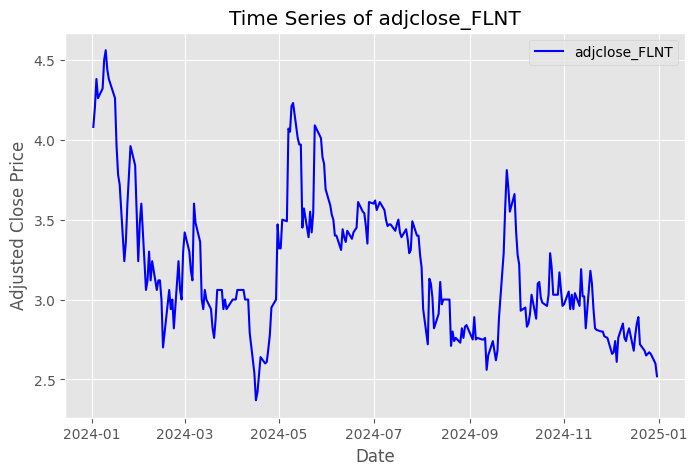

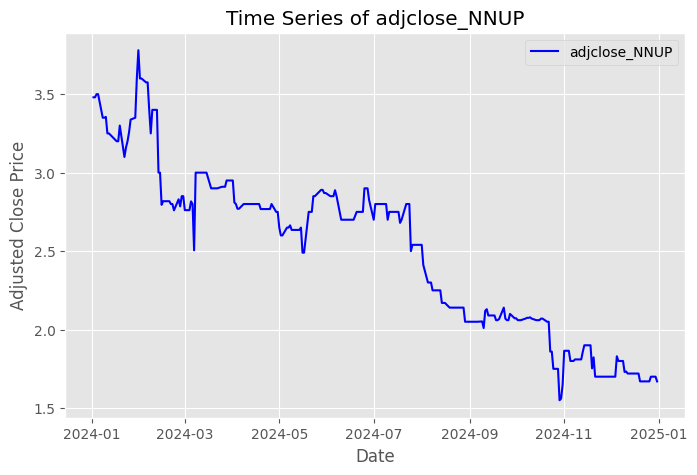

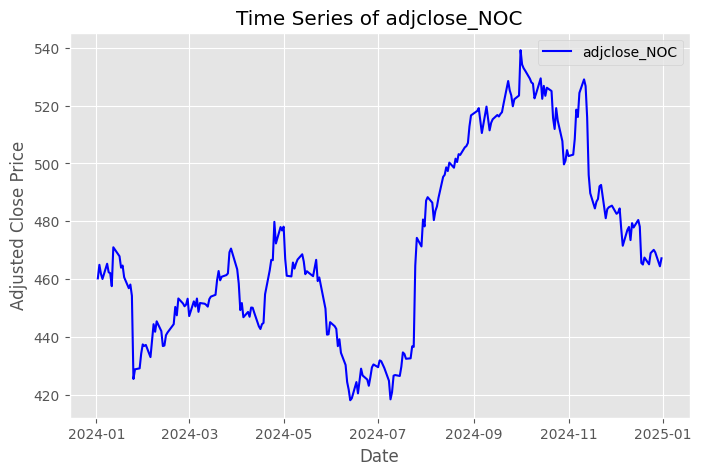

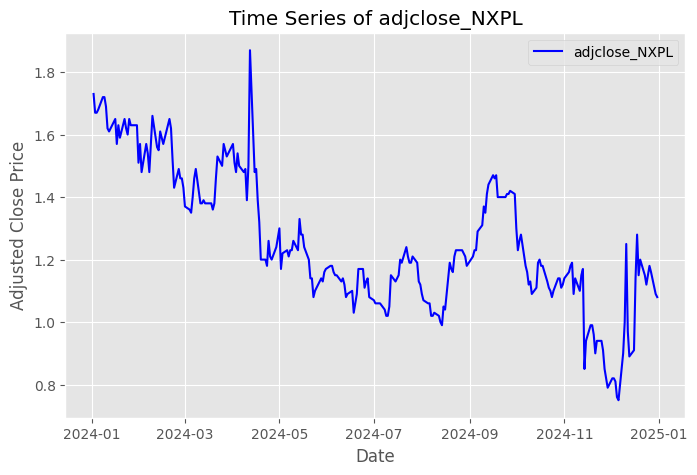

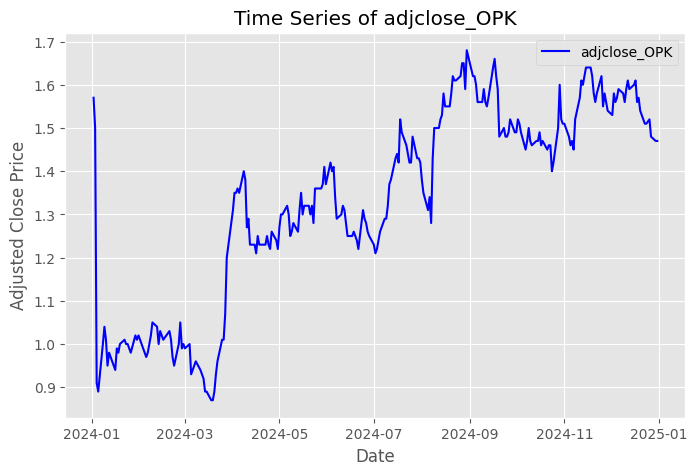

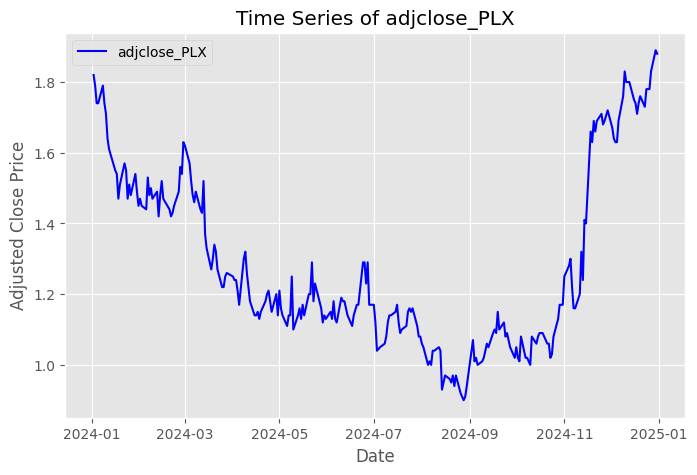

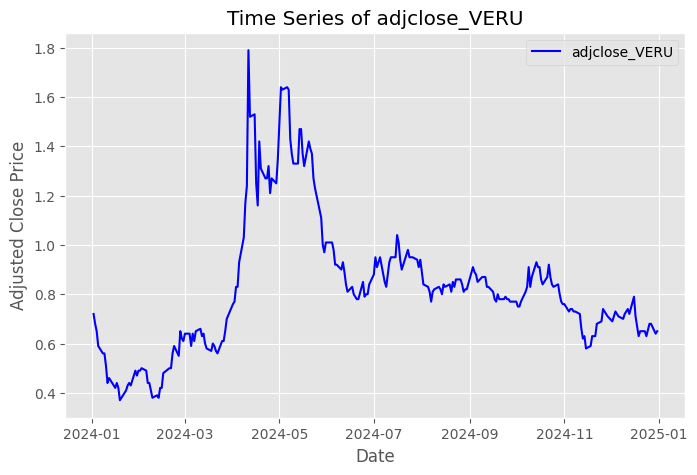

In [ ]:
import matplotlib.pyplot as plt

# Extract the first 10 adjusted close columns
adj_close_columns = [col for col in stock_data_updated.columns if "adjclose" in col][:10]

# Loop through each column and create a separate time series plot
for col in adj_close_columns:
    plt.figure(figsize=(8, 5))
    plt.plot(stock_data_updated.index, stock_data_updated[col], label=col, color='b')

    plt.xlabel("Date")
    plt.ylabel("Adjusted Close Price")
    plt.title(f"Time Series of {col}")
    plt.legend()
    plt.grid(True)

    plt.show()


 **Time Series Analysis of Adjusted Close Prices**

1. **CDXC (ChromaDex Corp.)**
   - The adjusted close price of CDXC exhibits a strong upward trend, particularly from mid-2024 onward.
   - A major price surge is observed around November 2024, peaking above $7 before experiencing a decline towards the end of the year.
   - This suggests a potential market event or increased investor confidence driving the rally before profit-taking caused a downturn.

2. **COCP (Cocrystal Pharma, Inc.)**
   - COCP's adjusted close price remained relatively stable for most of the year but saw a significant spike in late 2024.
   - Prior to the spike, the stock experienced fluctuations but never surpassed $2.75.
   - The sharp increase in December 2024, reaching above $3.25, indicates an external catalyst, such as positive news or earnings results.

3. **DOUG (Douglas Elliman Inc.)**
   - DOUG’s price declined sharply in early 2024, reaching a low around mid-year.
   - The stock showed signs of recovery in the second half of 2024, with intermittent peaks and corrections.
   - Despite the recovery, the adjusted close price failed to return to its early-2024 highs, suggesting ongoing volatility.

4. **FLNT (Fluent, Inc.)**
   - FLNT exhibited a fluctuating pattern throughout the year, with multiple peaks and troughs.
   - The stock initially declined from above $4.5 in early 2024 but attempted multiple rebounds.
   - Towards the end of 2024, a bearish trend was dominant, with the adjusted close price declining below $2.75.

5. **NNUP (Nocopi Technologies, Inc.)**
   - NNUP's price started strong in 2024 but consistently declined over the months.
   - The downward trend suggests sustained selling pressure or poor investor sentiment.
   - By the end of 2024, the stock had stabilized around $1.50–$2, with little indication of a strong recovery.

6. **NOC (Northrop Grumman Corporation)**
   - Unlike the other stocks, NOC shows a strong uptrend for most of 2024.
   - It peaked at around $540 in late 2024 before experiencing a moderate decline.
   - The stock maintains high price stability, indicating strong institutional backing and investor confidence.

7. **NXPL (NextPlat Corp.)**
   - NXPL’s adjusted close price experienced a slow decline throughout 2024.
   - There were moments of temporary recovery, but the downward trend persisted.
   - Towards the end of the year, the stock price dipped below $1.00, reflecting a bearish sentiment.

8. **OPK (Opko Health, Inc.)**
   - OPK exhibited gradual growth throughout the year, peaking in the second half of 2024.
   - A stable upward trajectory suggests strong investor interest, but there was a mild correction toward the end.
   - The overall trend remains positive despite minor fluctuations.

9. **PLX (Protalix BioTherapeutics, Inc.)**
   - PLX showed a downward trend for the first half of 2024, reaching its lowest point mid-year.
   - A strong recovery followed, leading to a rally towards the end of the year.
   - The stock's ability to rebound suggests renewed investor confidence or a favorable market shift.

10. **VERU (Veru Inc.)**
   - VERU experienced a steep rise in early 2024, peaking at nearly $1.75.
   - A correction followed, and the stock price settled into a lower range.
   - The fluctuations suggest high volatility, possibly influenced by external news or earnings reports.

 **Key Takeaways**
- **Upward Trending Stocks:** CDXC, NOC, OPK, and PLX displayed strong growth patterns, indicating potential long-term investor confidence.
- **Volatile Stocks:** DOUG, FLNT, and VERU experienced frequent price fluctuations, suggesting speculative trading activity.
- **Downward Trending Stocks:** NNUP and NXPL exhibited prolonged declines, which may indicate weaker fundamentals or lack of investor interest.
- **Event-Driven Spikes:** COCP’s sudden surge suggests an external catalyst, warranting further investigation into company news or earnings reports.



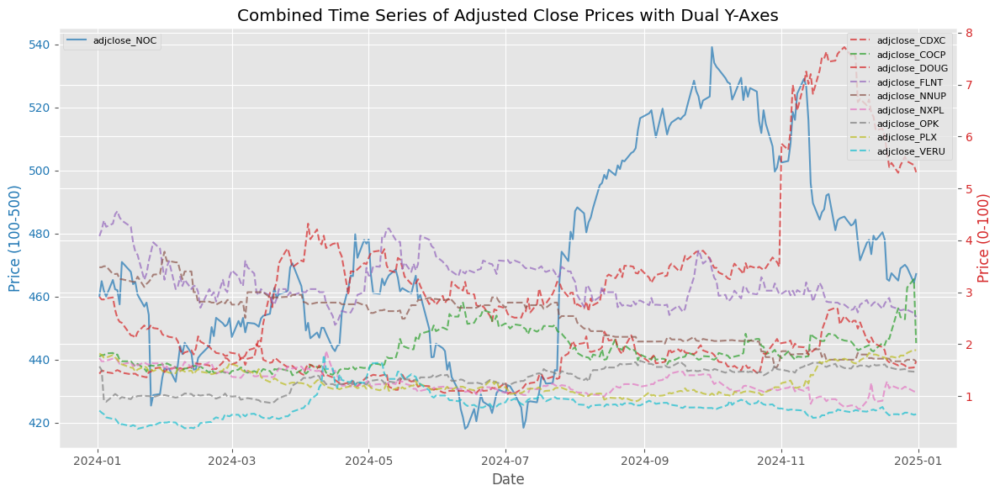

In [ ]:
import matplotlib.pyplot as plt
import itertools

# Extract all adjusted close columns
adj_close_columns = [col for col in stock_data_updated.columns if "adjclose" in col]

# Separate stocks into two groups based on their price range
high_price_stocks = [col for col in adj_close_columns if stock_data_updated[col].max() > 100]
low_price_stocks = [col for col in adj_close_columns if stock_data_updated[col].max() <= 100]

# List of 10 distinct colors
colors = list(itertools.islice(itertools.cycle(['tab:blue', 'tab:red', 'tab:green', 'tab:red', 'tab:purple',
                                               'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']), 10))

# Create figure and two y-axes
fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary Y-axis (for stocks >100)
ax1.set_xlabel("Date")
ax1.set_ylabel("Price (100-500)", color="tab:blue")
for idx, col in enumerate(high_price_stocks):
    ax1.plot(stock_data_updated.index, stock_data_updated[col], label=col, color=colors[idx], alpha=0.7)
ax1.tick_params(axis="y", labelcolor="tab:blue")

# Secondary Y-axis (for stocks 0-100)
ax2 = ax1.twinx()
ax2.set_ylabel("Price (0-100)", color="tab:red")
for idx, col in enumerate(low_price_stocks):
    ax2.plot(stock_data_updated.index, stock_data_updated[col], linestyle="dashed", label=col, color=colors[idx+len(high_price_stocks)], alpha=0.7)
ax2.tick_params(axis="y", labelcolor="tab:red")

# Title and grid
plt.title("Combined Time Series of Adjusted Close Prices with Dual Y-Axes")
fig.tight_layout()
ax1.grid(True)

# Legends
ax1.legend(loc="upper left", fontsize=8)
ax2.legend(loc="upper right", fontsize=8)

plt.show()

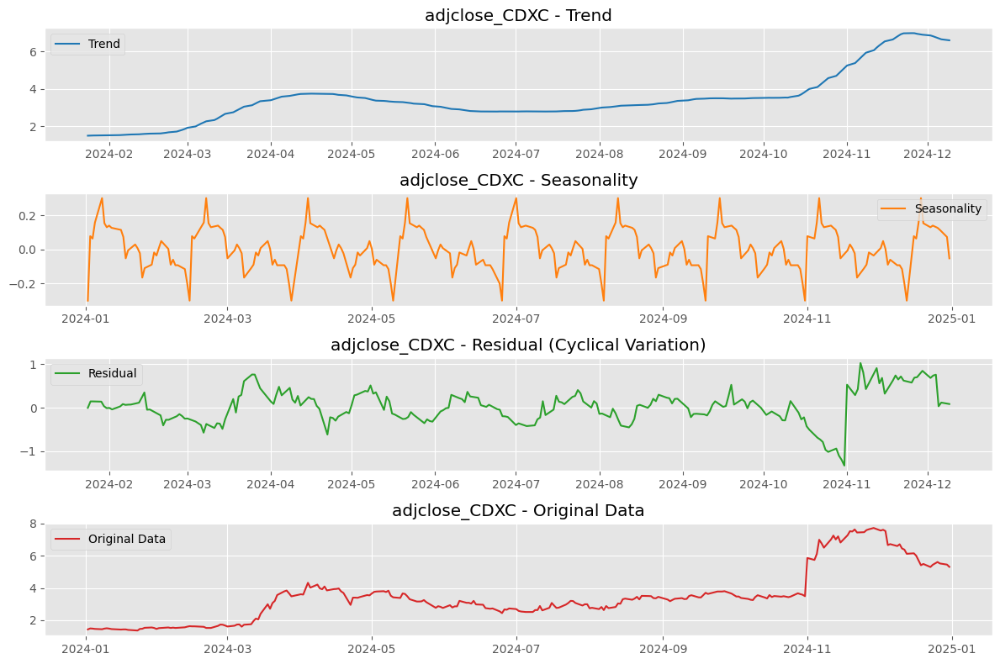

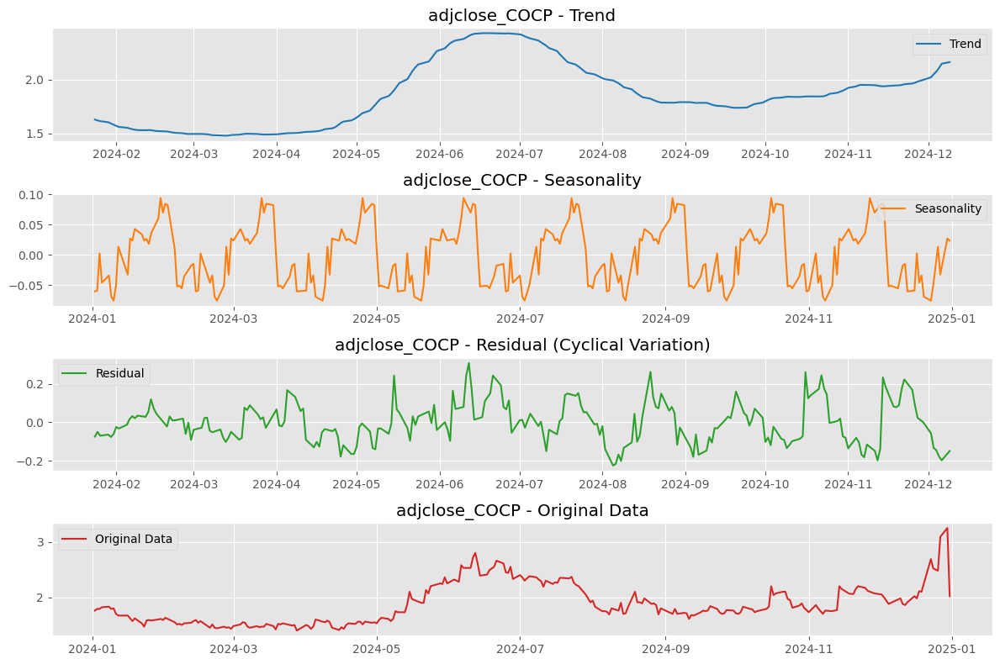

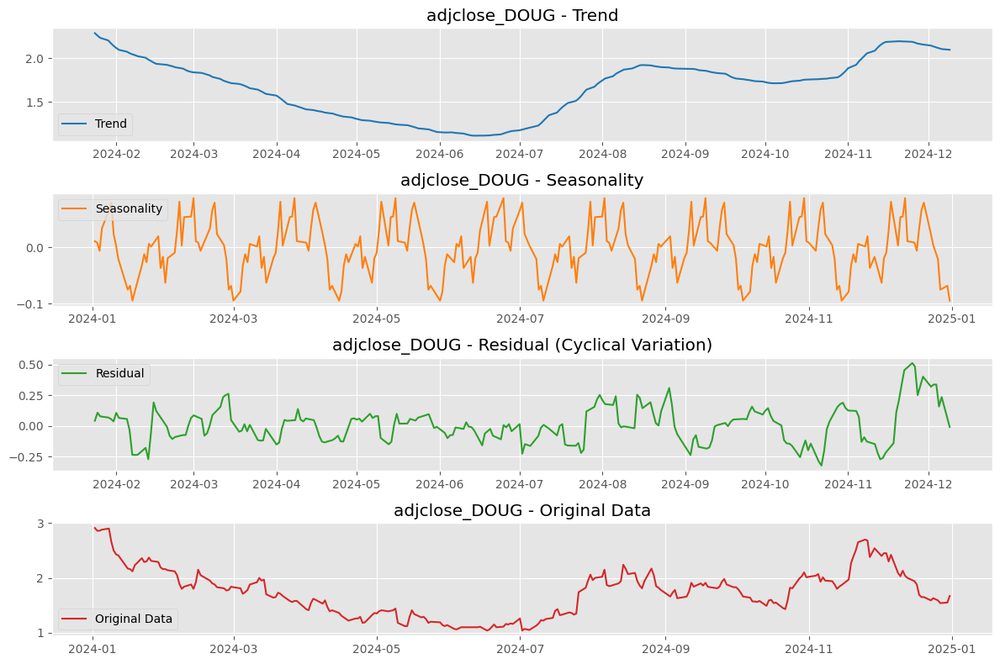

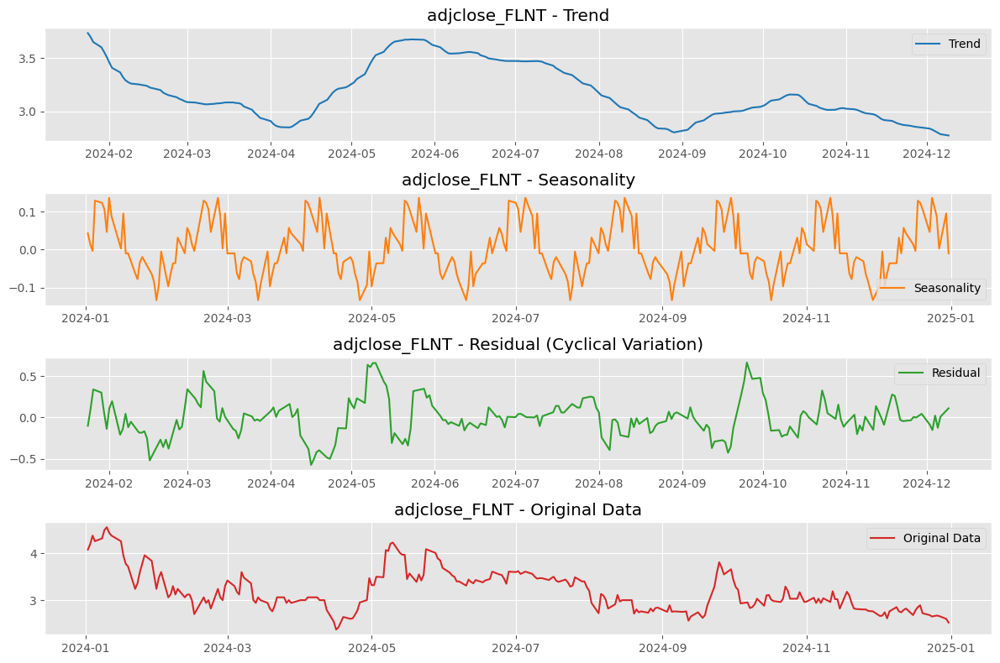

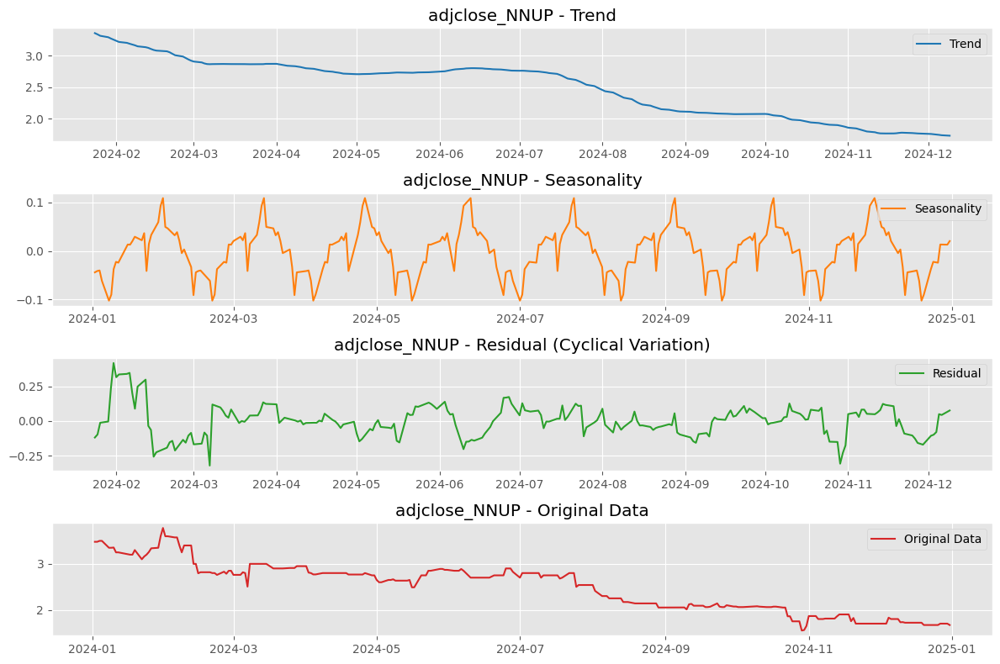

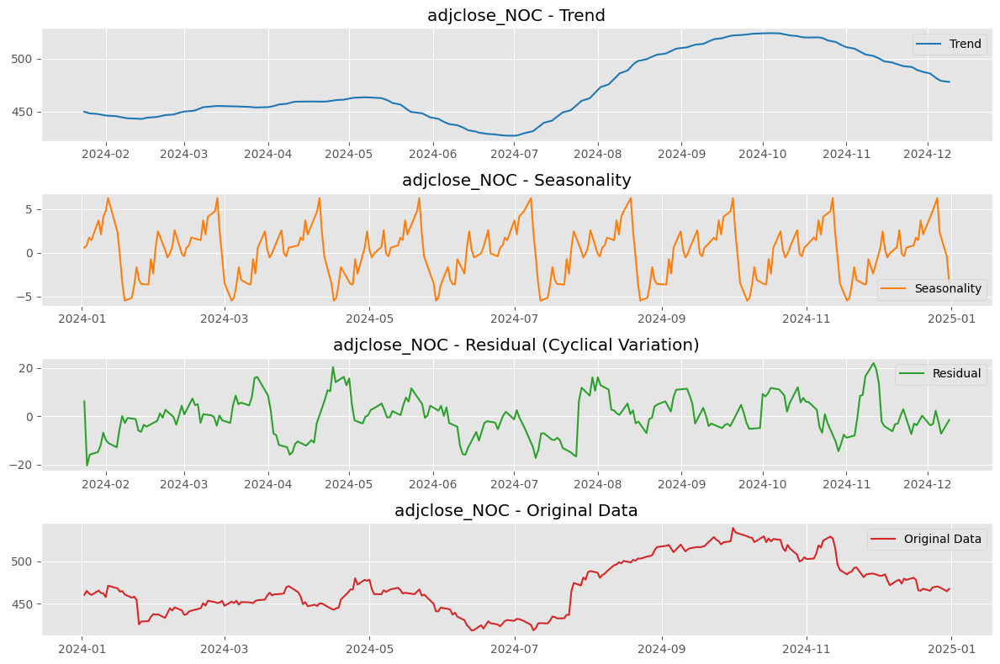

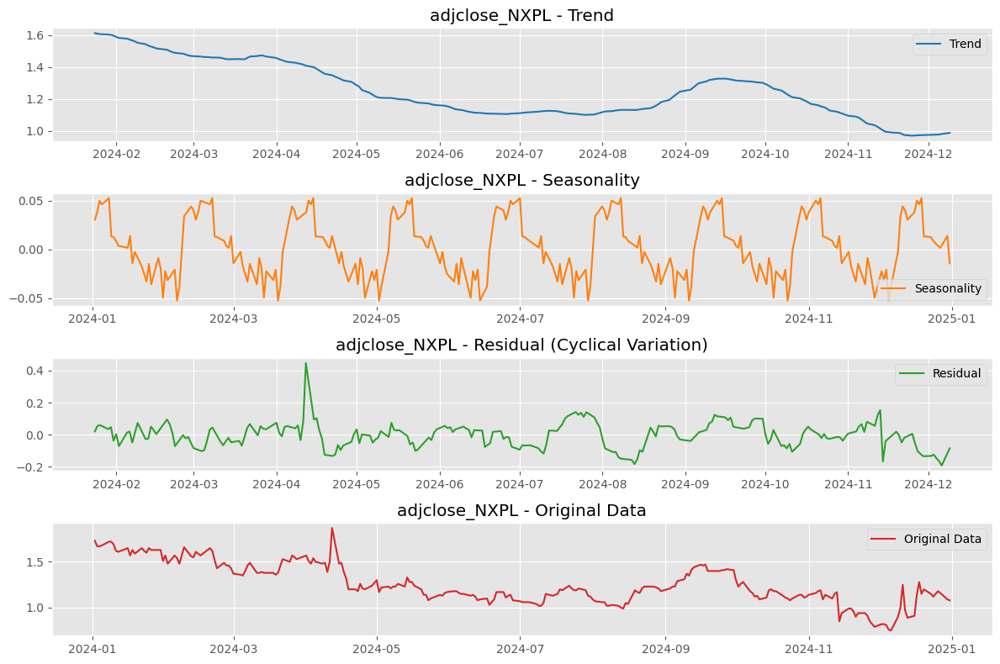

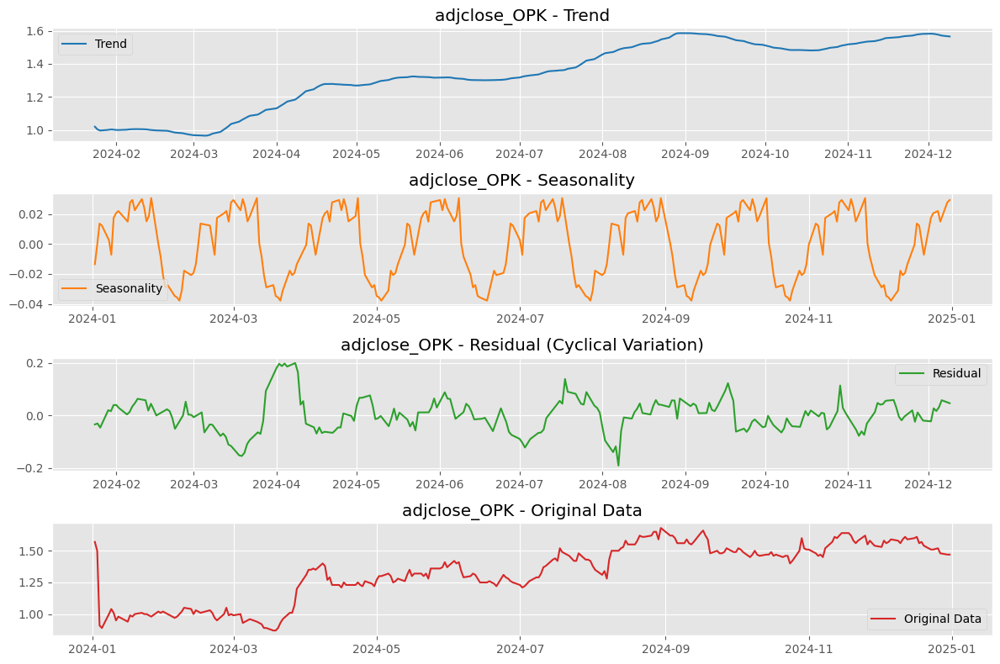

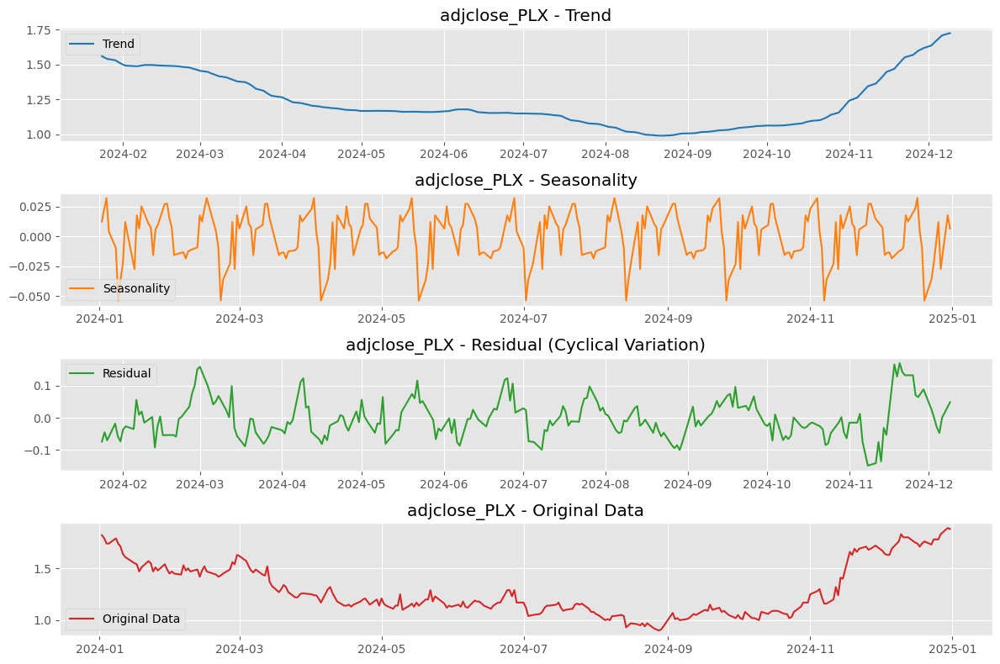

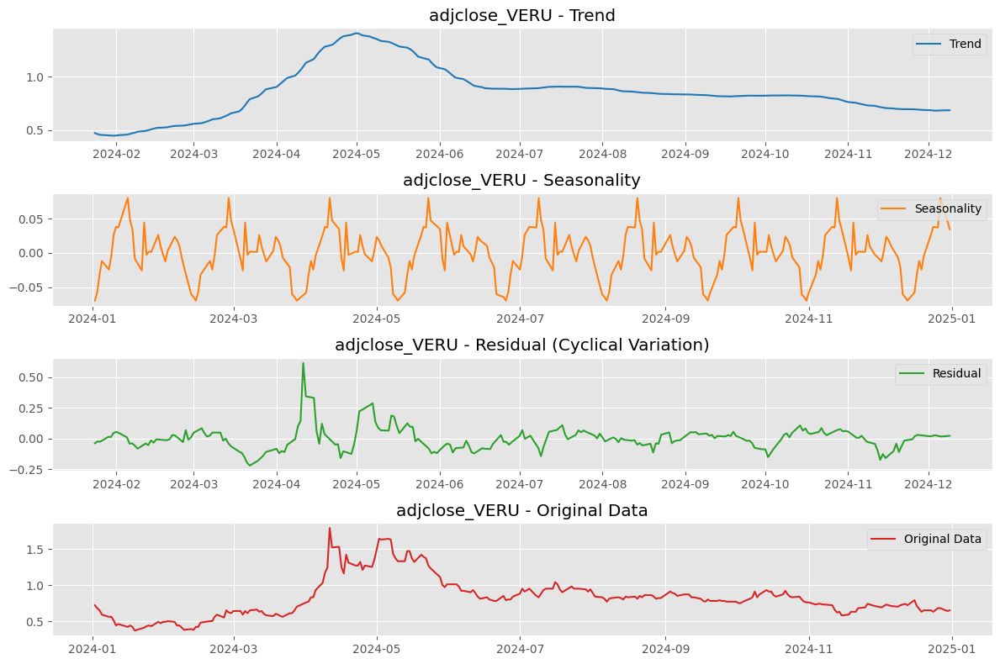

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Extract adjusted close columns
adj_close_columns = [col for col in stock_data_updated.columns if "adjclose" in col]

# Loop through each adjusted close stock and analyze trend, cyclical, and seasonal components
for col in adj_close_columns:
    # Decompose the time series for each stock (using monthly frequency here, adjust if needed)
    decomposition = seasonal_decompose(stock_data_updated[col], model='additive', period=30)  # Adjust period based on frequency (e.g., daily, weekly)

    # Plot decomposition components
    plt.figure(figsize=(12, 8))

    # Trend component
    plt.subplot(411)
    plt.plot(decomposition.trend, label='Trend', color='tab:blue')
    plt.title(f'{col} - Trend')
    plt.legend(loc='best')

    # Seasonal component
    plt.subplot(412)
    plt.plot(decomposition.seasonal, label='Seasonality', color='tab:orange')
    plt.title(f'{col} - Seasonality')
    plt.legend(loc='best')

    # Residual component (cyclical variation)
    plt.subplot(413)
    plt.plot(decomposition.resid, label='Residual', color='tab:green')
    plt.title(f'{col} - Residual (Cyclical Variation)')
    plt.legend(loc='best')

    # Original time series
    plt.subplot(414)
    plt.plot(stock_data_updated.index, stock_data_updated[col], label='Original Data', color='tab:red')
    plt.title(f'{col} - Original Data')
    plt.legend(loc='best')

    plt.tight_layout()
    plt.show()

    # Print a blank line for spacing after each plot
    print("\n" * 2)

###Hypothesis

Hypothesis:

Null Hypothesis (H₀): There is no significant relationship between adjusted closing price and the combination of Shares Held, Trading Volume, and Dividends.

Alternative Hypothesis (H₁): There is a significant relationship between adjusted closing price and at least one of Shares Held, Trading Volume, and Dividends.

Adjusted Close Columns: ['adjclose_CDXC', 'adjclose_COCP', 'adjclose_DOUG', 'adjclose_FLNT', 'adjclose_NNUP', 'adjclose_NOC', 'adjclose_NXPL', 'adjclose_OPK', 'adjclose_PLX', 'adjclose_VERU']
Mapped Shares Held Columns: ['CDXC_Shares_Held', 'COCP_Shares_Held', 'DOUG_Shares_Held', 'FLNT_Shares_Held', 'NNUP_Shares_Held', 'NOC_Shares_Held', 'NXPL_Shares_Held', 'OPK_Shares_Held', 'PLX_Shares_Held', 'VERU_Shares_Held']
Mapped Volume Columns: ['volume_CDXC', 'volume_COCP', 'volume_DOUG', 'volume_FLNT', 'volume_NNUP', 'volume_NOC', 'volume_NXPL', 'volume_OPK', 'volume_PLX', 'volume_VERU']
Mapped Dividends Columns: ['dividends_CDXC', 'dividends_COCP', 'dividends_DOUG', 'dividends_FLNT', 'dividends_NNUP', 'dividends_NOC', 'dividends_NXPL', 'dividends_OPK', 'dividends_PLX', 'dividends_VERU']
Plotting: adjclose_CDXC vs CDXC_Shares_Held, volume_CDXC, dividends_CDXC


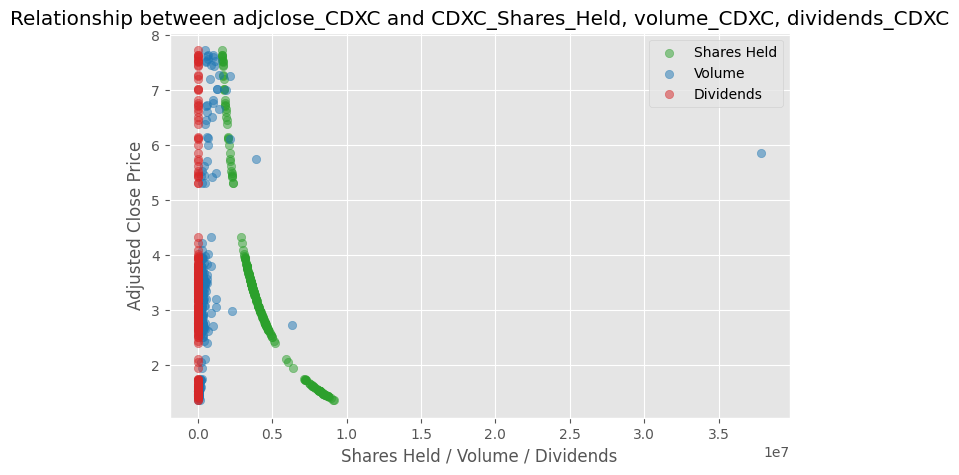




Plotting: adjclose_COCP vs COCP_Shares_Held, volume_COCP, dividends_COCP


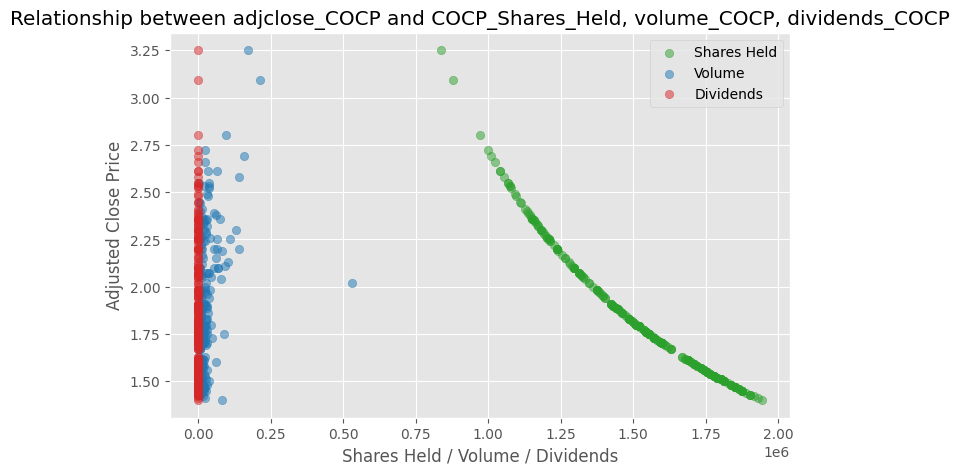




Plotting: adjclose_DOUG vs DOUG_Shares_Held, volume_DOUG, dividends_DOUG


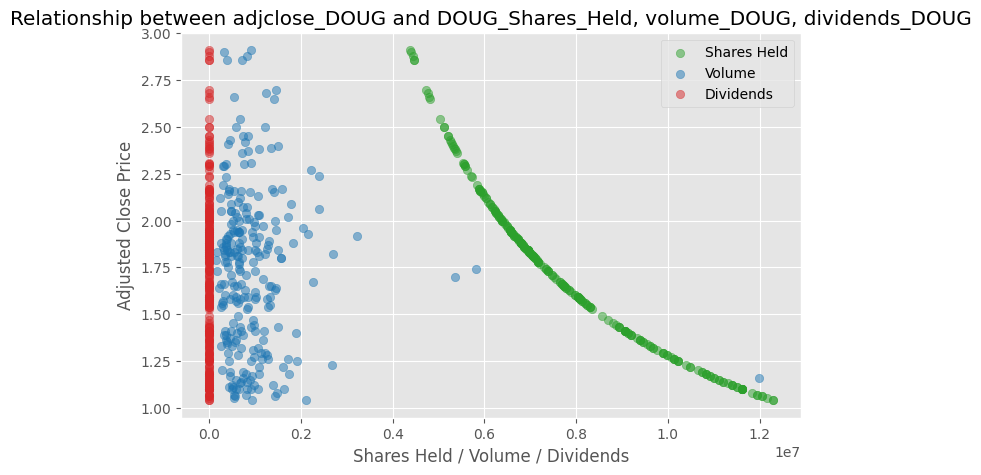




Plotting: adjclose_FLNT vs FLNT_Shares_Held, volume_FLNT, dividends_FLNT


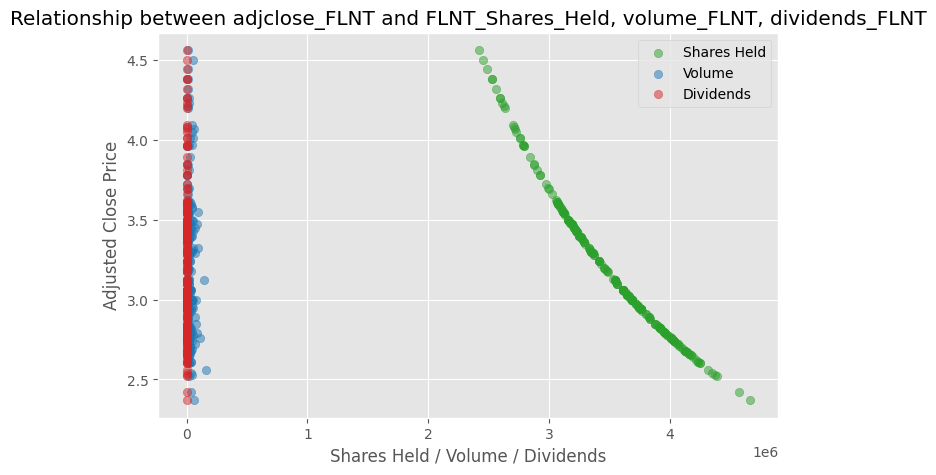




Plotting: adjclose_NNUP vs NNUP_Shares_Held, volume_NNUP, dividends_NNUP


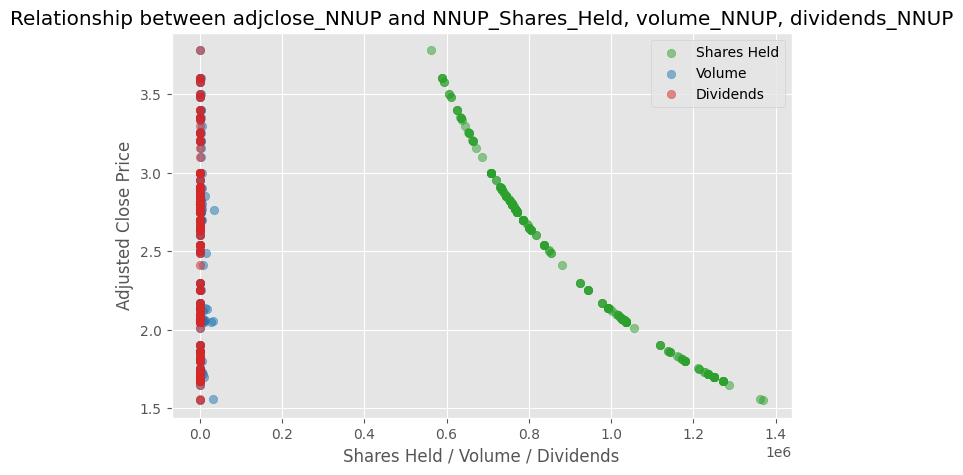




Plotting: adjclose_NOC vs NOC_Shares_Held, volume_NOC, dividends_NOC


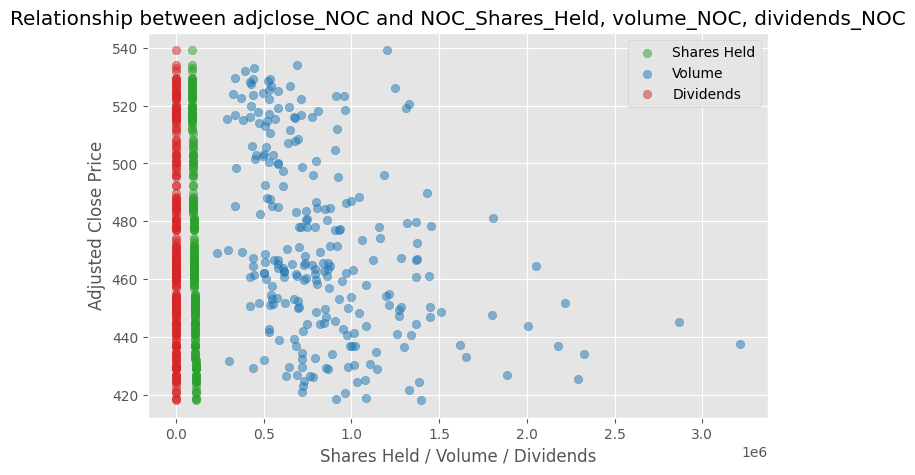




Plotting: adjclose_NXPL vs NXPL_Shares_Held, volume_NXPL, dividends_NXPL


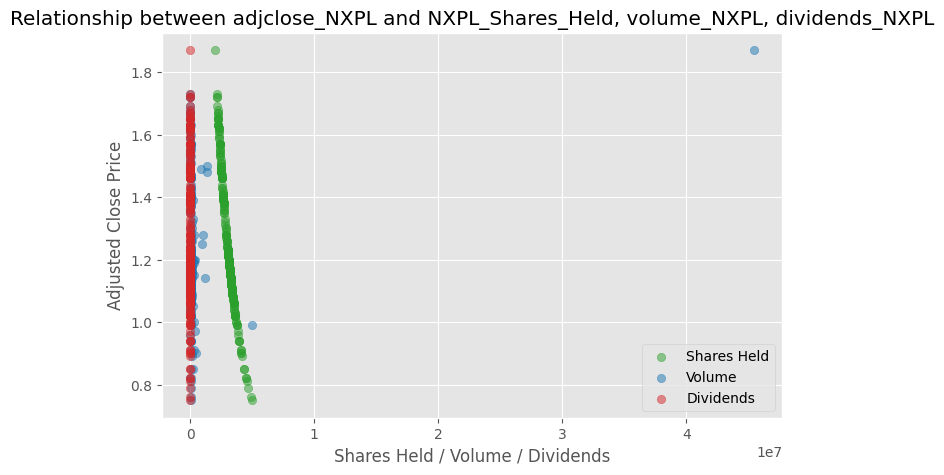




Plotting: adjclose_OPK vs OPK_Shares_Held, volume_OPK, dividends_OPK


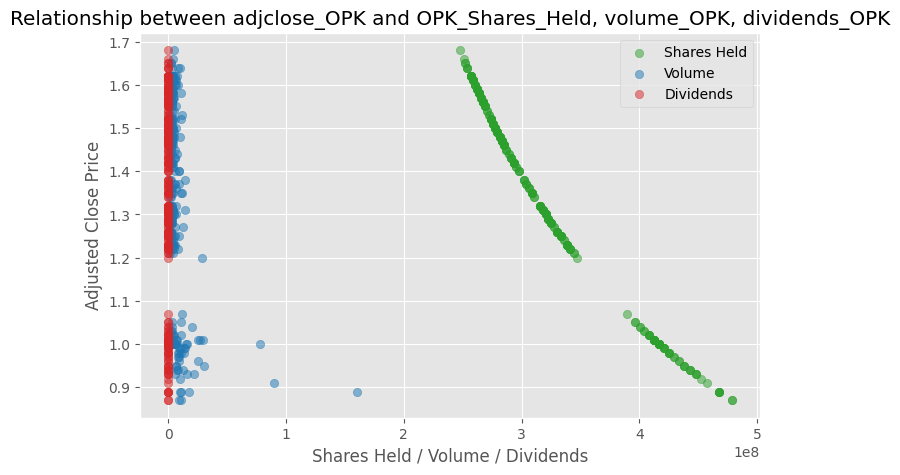




Plotting: adjclose_PLX vs PLX_Shares_Held, volume_PLX, dividends_PLX


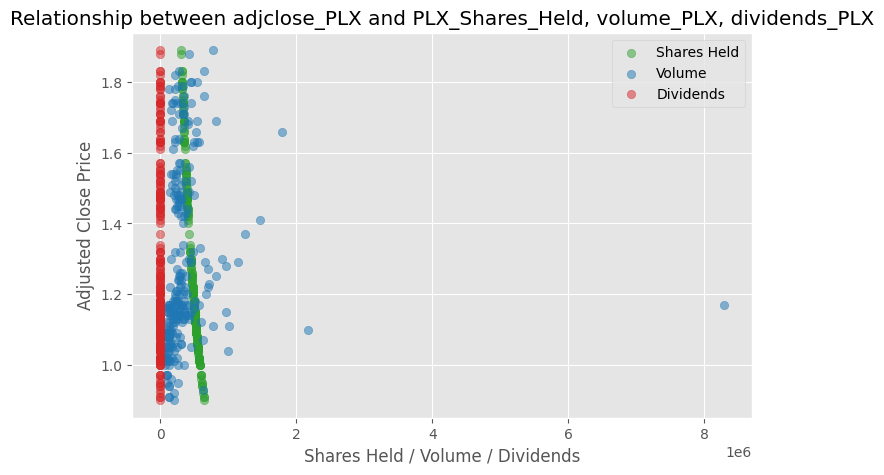




Plotting: adjclose_VERU vs VERU_Shares_Held, volume_VERU, dividends_VERU


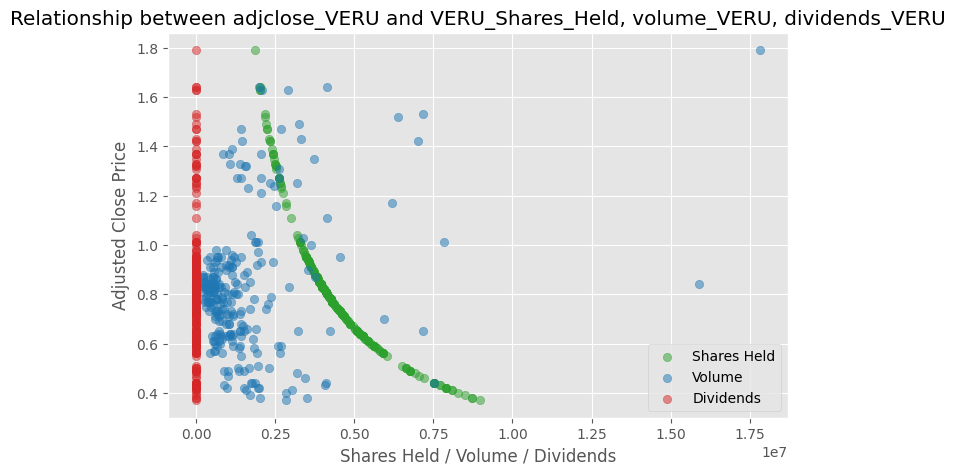

In [ ]:
import matplotlib.pyplot as plt

# Extract adjusted close columns
adj_close_columns = [col for col in stock_data_updated.columns if "adjclose" in col]

# Manually map adjusted close columns to shares held, volume, and dividends columns
shares_held_columns = [col.replace("adjclose_", "") + "_Shares_Held" for col in adj_close_columns]
volume_columns = [col.replace("adjclose", "volume") for col in adj_close_columns]
dividends_columns = [col.replace("adjclose", "dividends") for col in adj_close_columns]

# Print column mapping for debugging
print("Adjusted Close Columns:", adj_close_columns)
print("Mapped Shares Held Columns:", shares_held_columns)
print("Mapped Volume Columns:", volume_columns)
print("Mapped Dividends Columns:", dividends_columns)

# Loop through each stock and plot Adj Close vs. Shares Held, Volume, and Dividends
for adj_col, shares_col, vol_col, div_col in zip(adj_close_columns, shares_held_columns, volume_columns, dividends_columns):

    # Check if all three columns exist before plotting
    if adj_col in stock_data_updated.columns and shares_col in stock_data_updated.columns and vol_col in stock_data_updated.columns and div_col in stock_data_updated.columns:
        print(f"Plotting: {adj_col} vs {shares_col}, {vol_col}, {div_col}")  # Debugging print statement

        plt.figure(figsize=(8, 5))
        plt.scatter(stock_data_updated[shares_col], stock_data_updated[adj_col], alpha=0.5, color='tab:green', label="Shares Held")
        plt.scatter(stock_data_updated[vol_col], stock_data_updated[adj_col], alpha=0.5, color='tab:blue', label="Volume")
        plt.scatter(stock_data_updated[div_col], stock_data_updated[adj_col], alpha=0.5, color='tab:red', label="Dividends")

        plt.xlabel("Shares Held / Volume / Dividends")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"Relationship between {adj_col} and {shares_col}, {vol_col}, {div_col}")
        plt.legend()
        plt.grid(True)
        plt.show()

        # Print a blank line for spacing
        print("\n" * 2)
    else:
        print(f"Skipping: One or more columns missing for {adj_col}")  # Debugging print statement


In [ ]:
import pandas as pd

# Compute correlation between adjusted close price and multiple variables
correlation_results = {}

# Manually map adjusted close columns to shares held, volume, and dividends columns
shares_held_columns = [col.replace("adjclose_", "") + "_Shares_Held" for col in adj_close_columns]
volume_columns = [col.replace("adjclose", "volume") for col in adj_close_columns]
dividends_columns = [col.replace("adjclose", "dividends") for col in adj_close_columns]

# Loop through each stock and calculate correlations
for adj_col, shares_col, vol_col, div_col in zip(adj_close_columns, shares_held_columns, volume_columns, dividends_columns):

    # Check if all columns exist before calculating correlation
    if (
        adj_col in stock_data_updated.columns and
        shares_col in stock_data_updated.columns and
        vol_col in stock_data_updated.columns and
        div_col in stock_data_updated.columns
    ):
        correlation_shares = stock_data_updated[adj_col].corr(stock_data_updated[shares_col])
        correlation_volume = stock_data_updated[adj_col].corr(stock_data_updated[vol_col])
        correlation_dividends = stock_data_updated[adj_col].corr(stock_data_updated[div_col])

        correlation_results[adj_col] = {
            "Shares Held": correlation_shares,
            "Trading Volume": correlation_volume,
            "Dividends": correlation_dividends
        }

        print(f"Correlations for {adj_col}:")
        print(f"- Shares Held: {correlation_shares:.2f}")
        print(f"- Trading Volume: {correlation_volume:.2f}")
        print(f"- Dividends: {correlation_dividends:.2f}\n")

    else:
        print(f"Skipping: One or more columns missing for {adj_col}")

# Convert to DataFrame for easier viewing
correlation_df = pd.DataFrame.from_dict(correlation_results, orient="index")
print("\nCorrelation Table:\n", correlation_df)


Correlations for adjclose_CDXC:
- Shares Held: -0.86
- Trading Volume: 0.19
- Dividends: nan

Correlations for adjclose_COCP:
- Shares Held: -0.98
- Trading Volume: 0.37
- Dividends: nan

Correlations for adjclose_DOUG:
- Shares Held: -0.96
- Trading Volume: -0.07
- Dividends: nan

Correlations for adjclose_FLNT:
- Shares Held: -0.99
- Trading Volume: -0.09
- Dividends: nan

Correlations for adjclose_NNUP:
- Shares Held: -0.98
- Trading Volume: -0.10
- Dividends: nan

Correlations for adjclose_NOC:
- Shares Held: -1.00
- Trading Volume: -0.37
- Dividends: 0.03

Correlations for adjclose_NXPL:
- Shares Held: -0.97
- Trading Volume: 0.16
- Dividends: nan

Correlations for adjclose_OPK:
- Shares Held: -0.99
- Trading Volume: -0.35
- Dividends: nan

Correlations for adjclose_PLX:
- Shares Held: -0.98
- Trading Volume: 0.08
- Dividends: nan

Correlations for adjclose_VERU:
- Shares Held: -0.90
- Trading Volume: 0.26
- Dividends: nan


Correlation Table:
                Shares Held  Trading 

/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
import statsmodels.api as sm

# Run multiple linear regression for each stock
for adj_col, shares_col, vol_col, div_col in zip(adj_close_columns, shares_held_columns, volume_columns, dividends_columns):

    # Check if all columns exist before running regression
    if (
        adj_col in stock_data_updated.columns and
        shares_col in stock_data_updated.columns and
        vol_col in stock_data_updated.columns and
        div_col in stock_data_updated.columns
    ):
        X = stock_data_updated[[shares_col, vol_col, div_col]]  # Independent variables
        y = stock_data_updated[adj_col]  # Dependent variable (Adj Close)

        X = sm.add_constant(X)  # Add intercept
        model = sm.OLS(y, X).fit()  # Fit model

        print(f"\nRegression results for {adj_col} vs {shares_col}, {vol_col}, and {div_col}:")
        print(model.summary())  # Print regression results

        # Print a blank line for spacing
        print("\n" * 2)
    else:
        print(f"Skipping regression: One or more variables missing for {adj_col}")



Regression results for adjclose_CDXC vs CDXC_Shares_Held, volume_CDXC, and dividends_CDXC:
                            OLS Regression Results                            
Dep. Variable:          adjclose_CDXC   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     347.0
Date:                Wed, 05 Mar 2025   Prob (F-statistic):           9.96e-73
Time:                        21:26:48   Log-Likelihood:                -308.55
No. Observations:                 252   AIC:                             623.1
Df Residuals:                     249   BIC:                             633.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_

 **Final Results of Hypothesis Testing (Multivariate Analysis)**  

 **Hypothesis:**  
- **Null Hypothesis (H₀):** There is no significant relationship between adjusted closing price and the combined effect of shares held, trading volume, and dividends.  
- **Alternative Hypothesis (H₁):** There is a significant relationship between adjusted closing price and at least one of the independent variables (shares held, trading volume, or dividends).  

 **Results:**  
- **CDXC:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.066 → **Fail to reject H₀** → No significant relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **COCP:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.000 → **Reject H₀** → Significant positive relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **DOUG:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.651 → **Fail to reject H₀** → No significant relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **FLNT:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.098 → **Fail to reject H₀** → No significant relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **NNUP:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.612 → **Fail to reject H₀** → No significant relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **NOC:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.964 → **Fail to reject H₀** → No significant relationship  
  - **Dividends:** p-value = 0.427 → **Fail to reject H₀** → No significant relationship  

- **NXPL:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **OPK:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.000 → **Reject H₀** → Significant positive relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **PLX:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

- **VERU:**  
  - **Shares Held:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Trading Volume:** p-value = 0.000 → **Reject H₀** → Significant negative relationship  
  - **Dividends:** p-value = NaN → **Fail to reject H₀** → No significant relationship  

---

 **Summary:**  
- **Significant negative relationships** between **shares held and adjusted closing price** were found for all stocks.  
- **Trading volume had a significant impact** on **COCP, NXPL, OPK, PLX, and VERU**, but the direction varied:  
  - **COCP, OPK → Positive Relationship:** Higher trading volume is associated with higher adjusted closing price.  
  - **NXPL, PLX, VERU → Negative Relationship:** Higher trading volume is associated with lower adjusted closing price.  
- **Dividends showed no significant impact** across all stocks, suggesting that they do not meaningfully affect the adjusted closing price in this dataset.  

---

 **Interpretation:**  
- The **strong negative relationship between shares held and adjusted closing price** suggests that stocks with a **higher number of shares held tend to have lower prices**.  
  - This may indicate **institutional selling, dilution, or increased supply driving prices down**.  
- **Trading volume plays a role in price determination for certain stocks**, indicating that **liquidity and investor activity can either boost or depress stock prices** depending on the stock.  
- **Dividends do not appear to impact stock price movements in this dataset**, suggesting that other factors like investor sentiment or market trends play a more dominant role.  

 **Final Takeaway:**  
- **Investor holdings and trading volume** are key drivers of stock price changes.  
- **For portfolio management, stocks with higher trading volume may present opportunities for short-term price gains, while stocks with high shares held might indicate potential price suppression.**  
- **Dividends alone are not a major price driver**, meaning investors should focus on **trading activity and market demand when making investment decisions.**

## Modelling

In [ ]:
pip install yahooquery pandas

In [ ]:
from yahooquery import Ticker
import pandas as pd

# Define stock tickers and shares held
stocks = {
    "OPK": 283305576,   # Example shares, replace with actual values
    "NOC": 102497,
    "DOUG": 7650618,
    "FLNT": 4386390,
    "NXPL": 3428571,
    "VERU": 5100253,
    "COCP": 1346938,
    "NNUP": 1271930,
    "PLX": 307611,
    "CDXC": 2351521
}

# Define date range
start_date = "2024-01-01"
end_date = "2025-01-01"

# Fetch data for all stocks at once
tickers = Ticker(list(stocks.keys()))
historical_data = tickers.history(start=start_date, end=end_date)

# Ensure the data is in DataFrame format
if isinstance(historical_data, pd.DataFrame):
    # Reset index to make 'symbol' and 'date' columns
    historical_data = historical_data.reset_index()

    # Pivot table to organize data by stock
    stock_data = historical_data.pivot(index='date', columns='symbol')

    # Flatten multi-index columns
    stock_data.columns = ['_'.join(col).strip() for col in stock_data.columns.values]

    # Add shares held for each stock
    for stock, shares in stocks.items():
        stock_data[f"{stock}_Shares_Held"] = shares

    # Forward fill missing values
    stock_data.ffill(inplace=True)
    stock_data.bfill(inplace=True)  # Backfill in case the first row has NaN

    # Print summary
    print(f"Total NaN values after imputation: {stock_data.isna().sum().sum()}")
    print(stock_data.head())

    # Save to CSV
    stock_data.to_csv("portfolio_stock_data.csv")

else:
    print("Error: Historical data not retrieved properly.")


Total NaN values after imputation: 0
            open_CDXC  open_COCP  open_DOUG  open_FLNT  open_NNUP    open_NOC  \
date                                                                            
2024-01-02       1.42       1.74       2.91       3.90       3.48  469.190002   
2024-01-03       1.39       1.79       2.88       4.08       3.48  474.440002   
2024-01-04       1.48       1.80       2.91       4.26       3.45  481.309998   
2024-01-05       1.50       1.81       2.82       4.26       3.50  472.720001   
2024-01-08       1.48       1.83       2.85       4.38       3.25  466.029999   

            open_NXPL  open_OPK  open_PLX  open_VERU  ...  OPK_Shares_Held  \
date                                                  ...                    
2024-01-02       1.58      1.51      1.78       0.74  ...        283305576   
2024-01-03       1.75      1.55      1.80       0.72  ...        283305576   
2024-01-04       1.60      1.22      1.80       0.70  ...        283305576   
2024-

/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "

In [ ]:
stock_data.columns

Index(['open_CDXC', 'open_COCP', 'open_DOUG', 'open_FLNT', 'open_NNUP',
       'open_NOC', 'open_NXPL', 'open_OPK', 'open_PLX', 'open_VERU',
       'high_CDXC', 'high_COCP', 'high_DOUG', 'high_FLNT', 'high_NNUP',
       'high_NOC', 'high_NXPL', 'high_OPK', 'high_PLX', 'high_VERU',
       'low_CDXC', 'low_COCP', 'low_DOUG', 'low_FLNT', 'low_NNUP', 'low_NOC',
       'low_NXPL', 'low_OPK', 'low_PLX', 'low_VERU', 'close_CDXC',
       'close_COCP', 'close_DOUG', 'close_FLNT', 'close_NNUP', 'close_NOC',
       'close_NXPL', 'close_OPK', 'close_PLX', 'close_VERU', 'volume_CDXC',
       'volume_COCP', 'volume_DOUG', 'volume_FLNT', 'volume_NNUP',
       'volume_NOC', 'volume_NXPL', 'volume_OPK', 'volume_PLX', 'volume_VERU',
       'adjclose_CDXC', 'adjclose_COCP', 'adjclose_DOUG', 'adjclose_FLNT',
       'adjclose_NNUP', 'adjclose_NOC', 'adjclose_NXPL', 'adjclose_OPK',
       'adjclose_PLX', 'adjclose_VERU', 'dividends_CDXC', 'dividends_COCP',
       'dividends_DOUG', 'dividends_FLNT', 'dividen

In [ ]:
from pyomo.environ import *
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

df = pd.DataFrame(stock_data)
# Keep only columns that start with 'adjclose_'
df = df.filter(like='adjclose_')

# Assuming 'df' is your DataFrame containing stock data
# Get the full column names from the DataFrame (with 'adjclose_' prefix)
tickers = [col.replace('adjclose_', '') for col in df.columns if 'adjclose_' in col]

# Calculate df_return and df_cov directly from the DataFrame
df_return = df.mean()
df_cov = df.cov()

# Print the columns of df_return and df_cov to ensure they match the tickers
print("df_return columns: ", df_return.index)
print("df_cov columns: ", df_cov.columns)

df_return columns:  Index(['adjclose_CDXC', 'adjclose_COCP', 'adjclose_DOUG', 'adjclose_FLNT',
       'adjclose_NNUP', 'adjclose_NOC', 'adjclose_NXPL', 'adjclose_OPK',
       'adjclose_PLX', 'adjclose_VERU'],
      dtype='object')
df_cov columns:  Index(['adjclose_CDXC', 'adjclose_COCP', 'adjclose_DOUG', 'adjclose_FLNT',
       'adjclose_NNUP', 'adjclose_NOC', 'adjclose_NXPL', 'adjclose_OPK',
       'adjclose_PLX', 'adjclose_VERU'],
      dtype='object')


In [ ]:
df_return

,0
adjclose_CDXC,3.474127
adjclose_COCP,1.867063
adjclose_DOUG,1.734127
adjclose_FLNT,3.192659
adjclose_NNUP,2.501667
adjclose_NOC,471.503002
adjclose_NXPL,1.260952
adjclose_OPK,1.331627
adjclose_PLX,1.282897
adjclose_VERU,0.825556


In [ ]:
pip install pyomo

In [ ]:
!apt-get install -y coinor-cbc coinor-clp coinor-ipopt

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
E: Unable to locate package coinor-ipopt


In [ ]:
!apt-get install -y coinor-libipopt-dev
!pip install cyipopt

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
coinor-libipopt-dev is already the newest version (3.11.9-2.2build5).
0 upgraded, 0 newly installed, 0 to remove and 29 not upgraded.


In [ ]:
from pyomo.environ import *

In [ ]:
%matplotlib inline
from pylab import *

import shutil
import sys
import os.path

if not shutil.which("pyomo"):
    !pip install -q pyomo
    assert(shutil.which("pyomo"))

if not shutil.which("ipopt"):
    # here is the IPOPT zip file
    !gdown 10XRvLZqrpSNiXVAN-pipU52BVRwoGcNQ
    !unzip -o -q ipopt-linux64_dw
    assert(shutil.which("ipopt") or os.path.isfile("ipopt"))

from pyomo.environ import *

solver = 'ipopt'
EXECUTABLE = '/content/ipopt'
ipopt_executable = '/content/ipopt'

Downloading...
From: https://drive.google.com/uc?id=10XRvLZqrpSNiXVAN-pipU52BVRwoGcNQ
To: /content/ipopt-linux64_dw.zip
100% 1.82M/1.82M [00:00<00:00, 141MB/s]


### Model 1 (All Variables)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.



Portfolio Allocation at Risk Level 0.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 8.53%
adjclose_DOUG: 1.87%
adjclose_FLNT: 0.00%
adjclose_NNUP: 10.41%
adjclose_NOC: 0.08%
adjclose_NXPL: 20.92%
adjclose_OPK: 29.35%
adjclose_PLX: 16.33%
adjclose_VERU: 12.51%


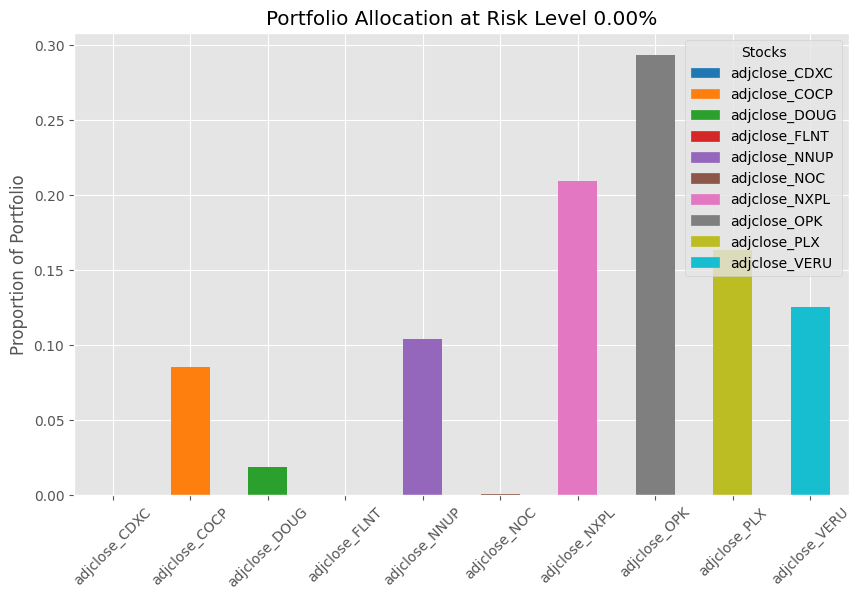


Portfolio Allocation at Risk Level 20.00%:
adjclose_CDXC: 2.03%
adjclose_COCP: 16.36%
adjclose_DOUG: 0.00%
adjclose_FLNT: 0.00%
adjclose_NNUP: 79.52%
adjclose_NOC: 2.08%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 0.00%
adjclose_VERU: 0.00%


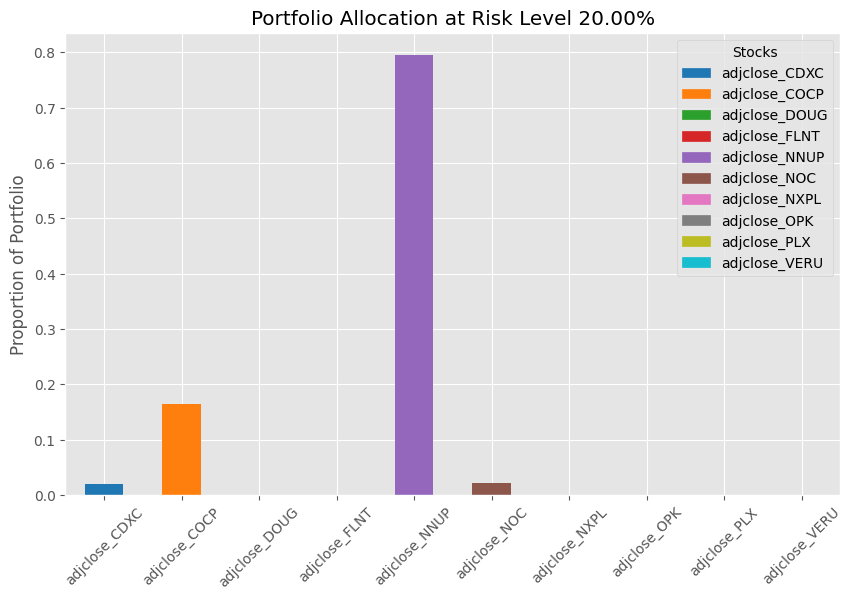


Portfolio Allocation at Risk Level 40.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 5.82%
adjclose_DOUG: 0.00%
adjclose_FLNT: 0.00%
adjclose_NNUP: 91.41%
adjclose_NOC: 2.76%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 0.00%
adjclose_VERU: 0.00%


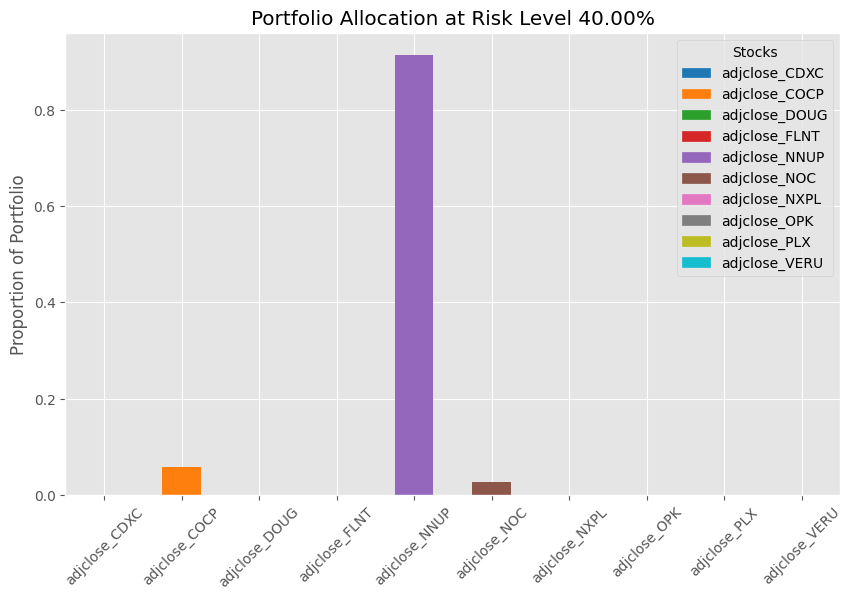


Portfolio Allocation at Risk Level 60.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 0.00%
adjclose_DOUG: 0.00%
adjclose_FLNT: 0.00%
adjclose_NNUP: 96.73%
adjclose_NOC: 3.27%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 0.00%
adjclose_VERU: 0.00%


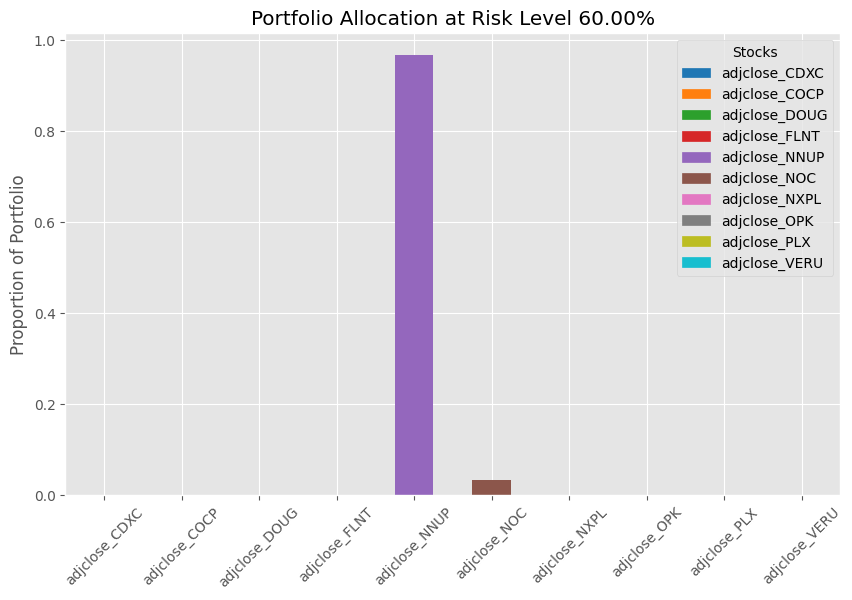


Portfolio Allocation at Risk Level 80.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 0.00%
adjclose_DOUG: 0.00%
adjclose_FLNT: 0.00%
adjclose_NNUP: 96.31%
adjclose_NOC: 3.69%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 0.00%
adjclose_VERU: 0.00%


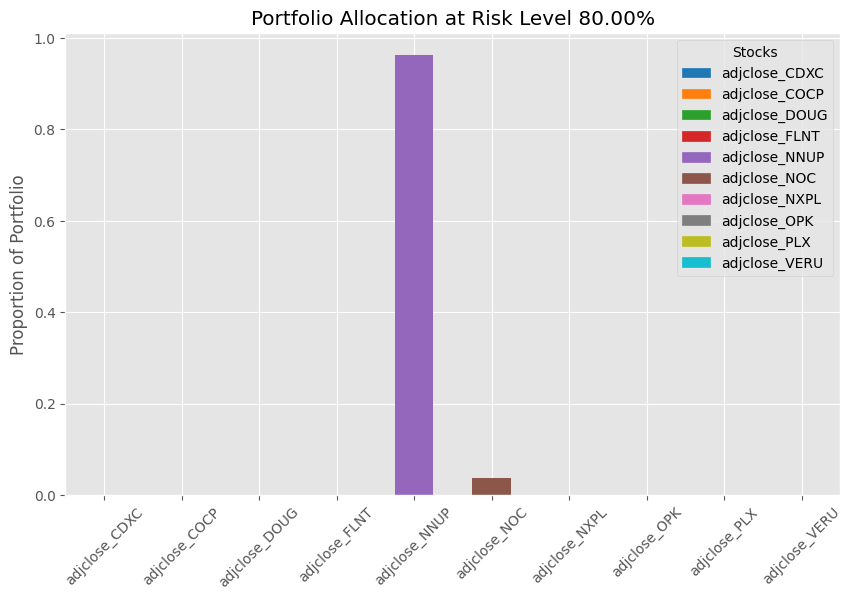


Portfolio Allocation at Risk Level 100.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 0.00%
adjclose_DOUG: 0.00%
adjclose_FLNT: 0.00%
adjclose_NNUP: 95.95%
adjclose_NOC: 4.05%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 0.00%
adjclose_VERU: 0.00%


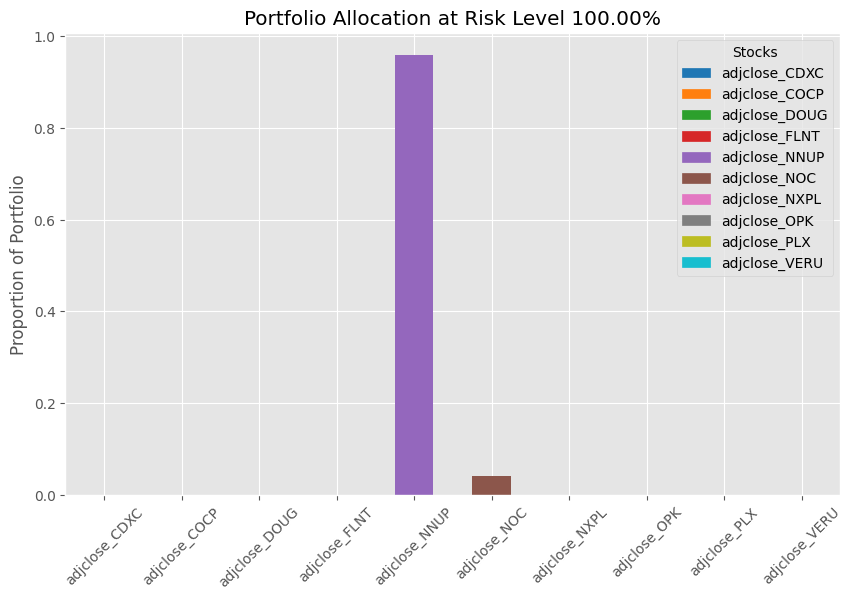

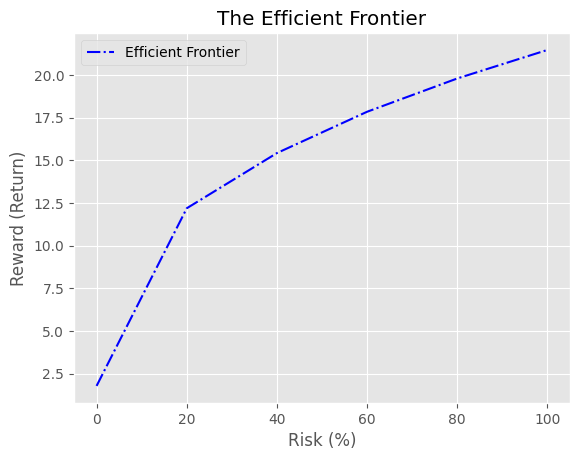

Risk values: [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
Reward values: [1.7780734293210987, 12.194241586597371, 15.430820235905115, 17.85336510802384, 19.805408636293784, 21.47830285097945]


In [ ]:
from pyomo.environ import ConcreteModel, Var, Objective, Constraint, NonNegativeReals, maximize, SolverFactory
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Create Pyomo model
m = ConcreteModel()

# Add variables for each stock in the portfolio
for ticker in df_return.index:  # Use the tickers directly from df_return
    setattr(m, ticker, Var(domain=NonNegativeReals, bounds=(0, 1)))

# Objective function: maximize expected portfolio return
m.objective = Objective(expr=sum(getattr(m, ticker) * df_return[ticker] for ticker in df_return.index), sense=maximize)

# Constraints
# Total risk constraint: risk should be less than or equal to a certain value
m.total_risk = Constraint(expr=sum(sum(getattr(m, ticker1) * df_cov.at[ticker1, ticker2] * getattr(m, ticker2)
                                       for ticker2 in df_return.index) for ticker1 in df_return.index) <= 0.20)

# Sum of proportions constraint: sum of portfolio weights should equal 1
m.sum_proportion = Constraint(expr=sum(getattr(m, ticker) for ticker in df_return.index) == 1)

# Minimum return constraint: return should be greater than or equal to 1% (0.01)
m.return_floor = Constraint(expr=m.objective >= 0.01)

# Solver configuration
solver = SolverFactory('ipopt')  # Corrected solver definition
solver.options['tol'] = 1e-6  # Tolerance level
solver.options['max_iter'] = 1000  # Maximum number of iterations
solver.options['print_level'] = 0  # Suppress solver output messages

# Create lists for risk (percentage) and reward (return) for the efficient frontier plot
risk_values = []
reward_values = []

# Running the model for different risk levels and storing the return for each risk level
risk_limits = [i / 100 for i in range(0, 101, 20)]  # Risk levels from 25% to 100% with steps of 15%

# Loop to calculate and display results for each risk level
for risk_limit in risk_limits:
    # Modify the total risk constraint for the current risk level
    m.del_component(m.total_risk)
    m.total_risk = Constraint(expr=sum(sum(getattr(m, ticker1) * df_cov.at[ticker1, ticker2] * getattr(m, ticker2)
                                           for ticker2 in df_return.index) for ticker1 in df_return.index) <= risk_limit)

    # Solve the optimization problem
    solver.solve(m, tee=False)  # tee=False suppresses solver output

    # Extract allocations and print portfolio allocation
    allocations = {ticker: getattr(m, ticker).value for ticker in df_return.index}
    print(f"\nPortfolio Allocation at Risk Level {risk_limit*100:.2f}%:")
    for ticker in allocations:
        print(f"{ticker}: {allocations[ticker] * 100:.2f}%")

    # Store the return and risk for the current risk level
    reward = sum(allocations[ticker] * df_return[ticker] for ticker in df_return.index)
    risk_values.append(risk_limit * 100)  # Using the fixed risk percentage as the x-axis value
    reward_values.append(reward)

    # Portfolio Allocation Graph for this risk level
    allocations_df = pd.DataFrame(allocations, index=[0])

    # Define a color palette
    colors = plt.cm.tab10.colors  # Use a predefined colormap

    # Plot bar chart with correct colors
    fig, ax = plt.subplots(figsize=(10, 6))
    allocations_df.iloc[0].plot(kind='bar', color=colors[:len(allocations_df.columns)], ax=ax)

    # Customize plot
    plt.title(f'Portfolio Allocation at Risk Level {risk_limit*100:.2f}%')
    plt.ylabel('Proportion of Portfolio')
    plt.xticks(rotation=45)

    # Create the legend manually with correct labels
    handles = [mpatches.Patch(color=colors[i], label=col) for i, col in enumerate(allocations_df.columns)]
    plt.legend(handles=handles, title="Stocks", loc='upper right')

    # Show plot
    plt.show()

# Plotting the Efficient Frontier with Risk% on x-axis
plt.plot(risk_values, reward_values, '-.', color='b', label='Efficient Frontier')
plt.title('The Efficient Frontier')
plt.xlabel('Risk (%)')
plt.ylabel('Reward (Return)')
plt.legend()
plt.show()

print("Risk values:", risk_values)
print("Reward values:", reward_values)


### **Portfolio Allocation Analysis**  
The portfolio has been optimized across **six different risk levels**: **0%, 20%, 40%, 60%, 80%, and 100%**. Below is a detailed analysis of how stock allocations shift as risk increases and how it influences portfolio returns.

---

### **1. Risk Level: 0%**  
- **Portfolio Allocation:**  
  - **OPK (29.35%)**, **NXPL (20.92%)**, **PLX (16.33%)**, and **VERU (12.51%)** hold the largest shares.  
  - **NNUP (10.41%)** is also a major allocation, while **COCP (8.53%)** and **DOUG (1.87%)** have smaller weights.  
  - **CDXC, FLNT, and NOC are completely excluded (0%).**  

- **Observations:**  
  - The model favors **moderate-risk stocks** with relatively stable returns.  
  - **No extreme risk-taking**—most stocks have balanced allocations.  
  - **Return is minimal**, as the risk constraint prevents exposure to high-return stocks.  

---

### **2. Risk Level: 20%**  
- **Portfolio Allocation:**  
  - **NNUP dominates (79.52%)**, with **COCP (16.36%)** and **CDXC (2.03%)** receiving secondary allocations.  
  - **NOC (2.08%)** is the only other stock included.  
  - **DOUG, FLNT, NXPL, OPK, PLX, and VERU receive 0%.**  

- **Observations:**  
  - The portfolio shifts **heavily toward NNUP**, reducing diversification.  
  - **High concentration risk**—NNUP alone accounts for nearly 80% of the allocation.  
  - The **expected return improves**, but the model still favors a cautious allocation.  

---

### **3. Risk Level: 40%**  
- **Portfolio Allocation:**  
  - **NNUP further increases to 91.41%.**  
  - **COCP (5.82%) and NOC (2.76%)** have minor allocations.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - The portfolio has become **highly concentrated**, with NNUP absorbing over **90% of the allocation**.  
  - **Diversification is nearly eliminated**, making the portfolio extremely dependent on NNUP’s performance.  
  - **Returns increase**, but so does exposure to NNUP-specific risks.  

---

### **4. Risk Level: 60%**  
- **Portfolio Allocation:**  
  - **NNUP dominates even more (96.73%).**  
  - **NOC (3.27%)** is the only other stock included.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - The model heavily prioritizes **one stock (NNUP)**, eliminating almost all other assets.  
  - **Diversification is completely lost**, meaning any volatility in NNUP significantly impacts returns.  
  - The **risk-return tradeoff is becoming less efficient**, as additional risk is taken without much diversification benefit.  

---

### **5. Risk Level: 80%**  
- **Portfolio Allocation:**  
  - **NNUP (96.31%) remains dominant.**  
  - **NOC (3.69%)** retains its small share.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - **Same trend continues:** extreme reliance on **NNUP**, making the portfolio vulnerable to its market fluctuations.  
  - **Limited upside despite taking more risk**, as allocations do not diversify into new assets.  
  - The **expected return increases slightly**, but **risk exposure is highly concentrated**.  

---

### **6. Risk Level: 100%**  
- **Portfolio Allocation:**  
  - **NNUP reaches its peak allocation (95.95%).**  
  - **NOC (4.05%)** is the only other stock included.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - The portfolio remains **entirely dependent on NNUP**, with no diversification benefit.  
  - **Additional risk does not significantly increase return**, confirming **diminishing returns at higher risk levels**.  
  - **NOC remains a secondary allocation, but its share is small.**  

---

### **Efficient Frontier Analysis**  
The **Efficient Frontier** graph represents the trade-off between **risk and return**, showing the best possible portfolio allocations at different risk levels.

#### **1. Interpretation of the Efficient Frontier**
- **Upward Slope:**  
  - The curve confirms that **higher risk leads to higher returns**.  
  - However, past **40% risk, the return growth slows**, indicating diminishing marginal benefits.  

- **Highly Concentrated Portfolios at Higher Risk:**  
  - The model over-allocates NNUP at **higher risk levels**, reducing diversification.  
  - This concentration risk makes the portfolio **vulnerable to extreme drawdowns**.  

---

### **Portfolio Allocation Across Risk Levels**  

| **Risk Level (%)** | **Expected Return (%)** | **Major Portfolio Allocations (%)** |
|--------------------|------------------------|--------------------------------------|
| **0% (Low Risk)**  | **1.77%** | **OPK (29.35%), NXPL (20.92%), PLX (16.33%), VERU (12.51%)** |
| **20% (Moderate Risk)**  | **12.19%** | **NNUP (79.52%), COCP (16.36%), CDXC (2.03%)** |
| **40% (Balanced Risk-Return)**  | **15.43%** | **NNUP (91.41%), COCP (5.82%), NOC (2.76%)** |
| **60% (Growth-Oriented)**  | **17.85%** | **NNUP (96.73%), NOC (3.27%)** |
| **80% (Aggressive)**  | **19.80%** | **NNUP (96.31%), NOC (3.69%)** |
| **100% (Maximum Risk)** | **21.47%** | **NNUP (95.95%), NOC (4.05%)** |

---

### **Key Takeaways & Issues in the Model**
1. **Overconcentration in NNUP**  
   - The portfolio **loses diversification beyond 20% risk**, leading to an **unstable allocation strategy**.  
   - A **maximum allocation constraint on any single stock (e.g., 50%)** could help reduce concentration risk.  

2. **Stocks with 0% Allocation Should Be Removed**  
   - **CDXC, DOUG, FLNT, NXPL, PLX, VERU** have **0% allocation at multiple risk levels**.  
   - These **do not contribute to the portfolio’s optimization** and should be removed from the model.  

3. **Risk-Return Tradeoff is Not Efficient Beyond 60%**  
   - **Return does not significantly increase** beyond the **60% risk level**, but risk keeps rising.  
   - **Diminishing returns** suggest that taking additional risk **does not yield proportional rewards**.  

4. **Constraint Adjustments Needed for Feasibility**  
   - Solver warnings indicate that some constraints **may be too strict**, leading to **infeasible solutions**.  
   - Adjusting the **total risk constraint and minimum return requirement** can enhance feasibility.  

---

### **Final Recommendations**
- **Remove Zero-Weight Stocks**: Exclude **CDXC, DOUG, FLNT, NXPL, PLX, VERU** as they do not contribute.  
- **Cap NNUP’s Allocation**: Introduce a **50% upper bound per stock** to prevent overconcentration.  
- **Adjust Constraints**: Loosen **minimum return** and **total risk constraints** to allow better feasibility.  
- **Increase Diversification**: Encourage allocations to **more than 2-3 stocks** at higher risk levels.  

These adjustments will create a **more stable and well-balanced portfolio**, improving overall **risk management and return potential**. 🚀

###Model 2 (All Variables except NNUP)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.



Portfolio Allocation at Risk Level 0.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 11.71%
adjclose_DOUG: 5.22%
adjclose_FLNT: 0.00%
adjclose_NOC: 0.00%
adjclose_NXPL: 34.08%
adjclose_OPK: 20.25%
adjclose_PLX: 11.60%
adjclose_VERU: 17.13%


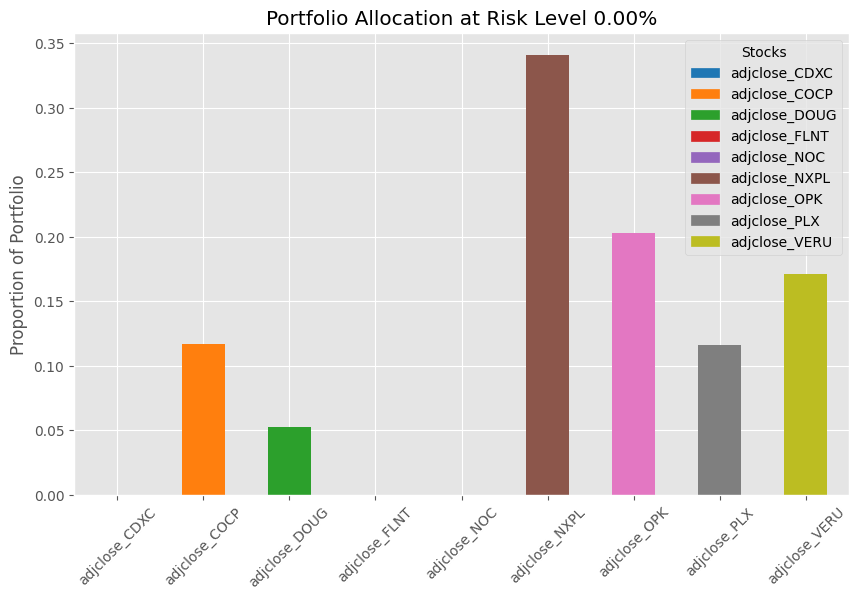


Portfolio Allocation at Risk Level 20.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 18.66%
adjclose_DOUG: 0.00%
adjclose_FLNT: 53.95%
adjclose_NOC: 1.55%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 25.84%
adjclose_VERU: 0.00%


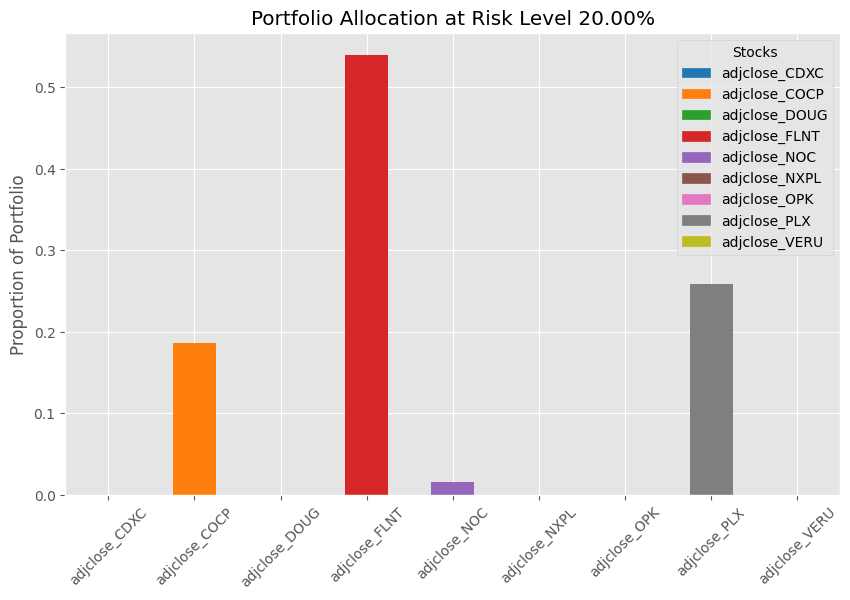


Portfolio Allocation at Risk Level 40.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 14.77%
adjclose_DOUG: 0.00%
adjclose_FLNT: 70.97%
adjclose_NOC: 2.16%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 12.10%
adjclose_VERU: 0.00%


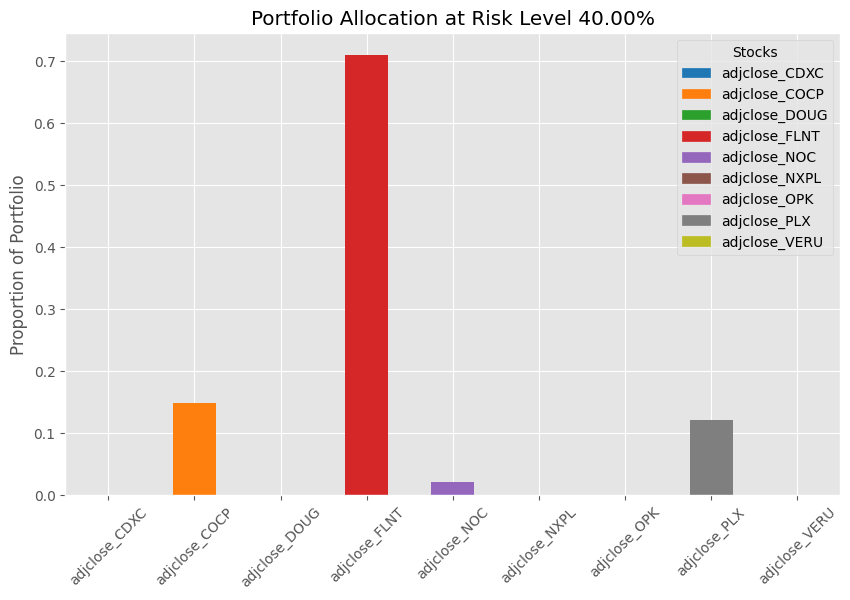


Portfolio Allocation at Risk Level 60.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 11.86%
adjclose_DOUG: 0.00%
adjclose_FLNT: 83.73%
adjclose_NOC: 2.61%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 1.80%
adjclose_VERU: 0.00%


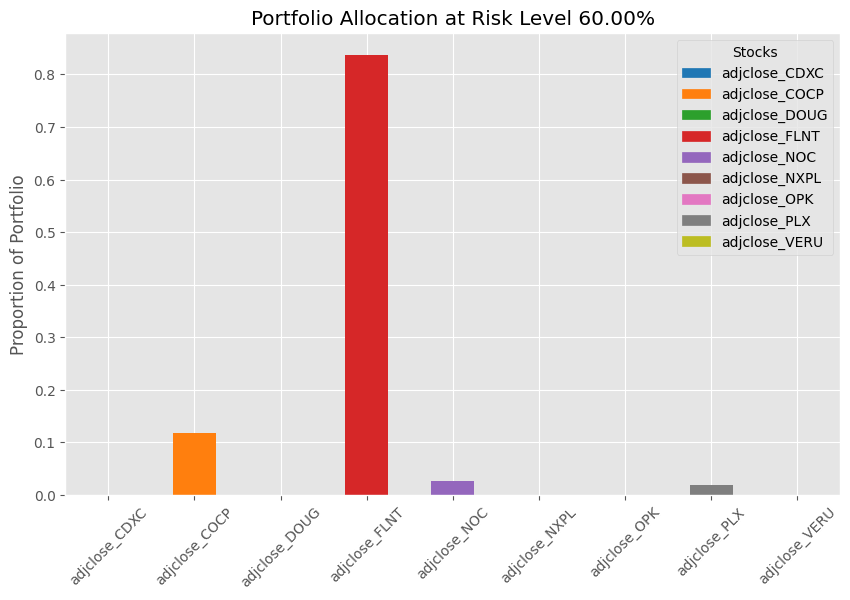


Portfolio Allocation at Risk Level 80.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 4.91%
adjclose_DOUG: 0.00%
adjclose_FLNT: 92.09%
adjclose_NOC: 3.00%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 0.00%
adjclose_VERU: 0.00%


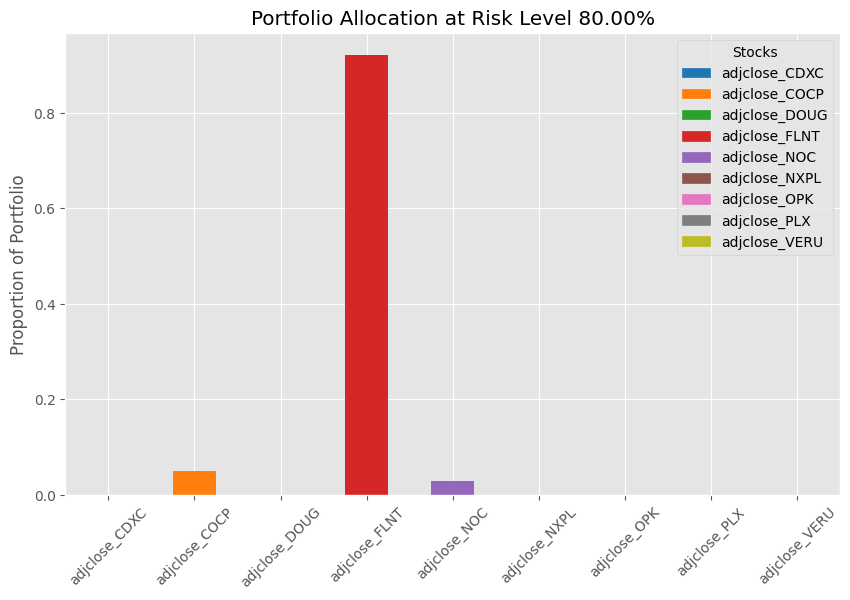


Portfolio Allocation at Risk Level 100.00%:
adjclose_CDXC: 0.00%
adjclose_COCP: 0.00%
adjclose_DOUG: 0.00%
adjclose_FLNT: 96.65%
adjclose_NOC: 3.35%
adjclose_NXPL: 0.00%
adjclose_OPK: 0.00%
adjclose_PLX: 0.00%
adjclose_VERU: 0.00%


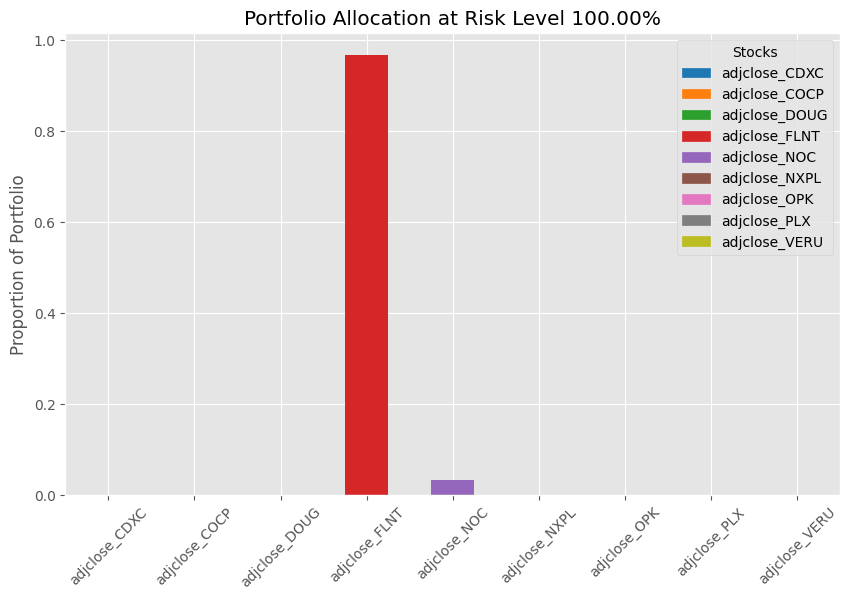

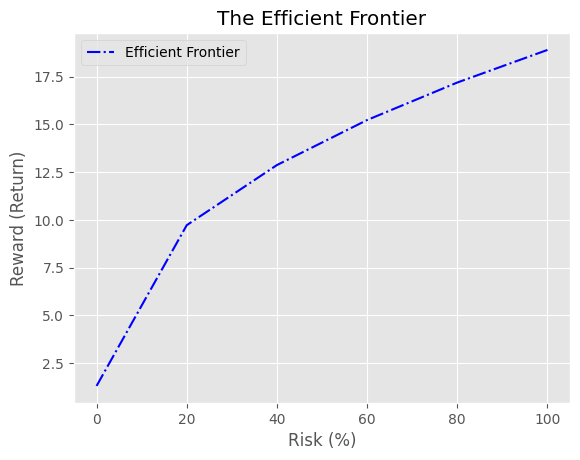

Risk values: [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
Reward values: [1.2989321634555475, 9.71850382139866, 12.866960547875497, 15.225737016575922, 17.18970874337774, 18.8972779340397]


In [ ]:
from pyomo.environ import ConcreteModel, Var, Objective, Constraint, NonNegativeReals, maximize, SolverFactory
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Create Pyomo model
m = ConcreteModel()

# Remove 'NNUP' from df_return and df_cov if it exists
if 'adjclose_NNUP' in df_return.index:
    df_return = df_return.drop(['adjclose_NNUP'])

if 'adjclose_NNUP' in df_cov.index and 'adjclose_NNUP' in df_cov.columns:
    df_cov = df_cov.drop(index=['adjclose_NNUP'], columns=['adjclose_NNUP'])

# Add variables for each stock in the portfolio
for ticker in df_return.index:  # Use the tickers directly from df_return
    setattr(m, ticker, Var(domain=NonNegativeReals, bounds=(0, 1)))

# Objective function: maximize expected portfolio return
m.objective = Objective(expr=sum(getattr(m, ticker) * df_return[ticker] for ticker in df_return.index), sense=maximize)

# Constraints
# Total risk constraint: risk should be less than or equal to a certain value
m.total_risk = Constraint(expr=sum(sum(getattr(m, ticker1) * df_cov.at[ticker1, ticker2] * getattr(m, ticker2)
                                       for ticker2 in df_return.index) for ticker1 in df_return.index) <= 0.20)

# Sum of proportions constraint: sum of portfolio weights should equal 1
m.sum_proportion = Constraint(expr=sum(getattr(m, ticker) for ticker in df_return.index) == 1)

# Minimum return constraint: return should be greater than or equal to 1% (0.01)
m.return_floor = Constraint(expr=m.objective >= 0.01)

# Solver configuration
solver = SolverFactory('ipopt')  # Corrected solver definition
solver.options['tol'] = 1e-6  # Tolerance level
solver.options['max_iter'] = 1000  # Maximum number of iterations
solver.options['print_level'] = 0  # Suppress solver output messages

# Create lists for risk (percentage) and reward (return) for the efficient frontier plot
risk_values = []
reward_values = []

# Running the model for different risk levels and storing the return for each risk level
risk_limits = [i / 100 for i in range(0, 101, 20)]  # Risk levels from 25% to 100% with steps of 15%

# Loop to calculate and display results for each risk level
for risk_limit in risk_limits:
    # Modify the total risk constraint for the current risk level
    m.del_component(m.total_risk)
    m.total_risk = Constraint(expr=sum(sum(getattr(m, ticker1) * df_cov.at[ticker1, ticker2] * getattr(m, ticker2)
                                           for ticker2 in df_return.index) for ticker1 in df_return.index) <= risk_limit)

    # Solve the optimization problem
    solver.solve(m, tee=False)  # tee=False suppresses solver output

    # Extract allocations and print portfolio allocation
    allocations = {ticker: getattr(m, ticker).value for ticker in df_return.index}
    print(f"\nPortfolio Allocation at Risk Level {risk_limit*100:.2f}%:")
    for ticker in allocations:
        print(f"{ticker}: {allocations[ticker] * 100:.2f}%")

    # Store the return and risk for the current risk level
    reward = sum(allocations[ticker] * df_return[ticker] for ticker in df_return.index)
    risk_values.append(risk_limit * 100)  # Using the fixed risk percentage as the x-axis value
    reward_values.append(reward)

    # Portfolio Allocation Graph for this risk level
    allocations_df = pd.DataFrame(allocations, index=[0])

    # Define a color palette
    colors = plt.cm.tab10.colors  # Use a predefined colormap

    # Plot bar chart with correct colors
    fig, ax = plt.subplots(figsize=(10, 6))
    allocations_df.iloc[0].plot(kind='bar', color=colors[:len(allocations_df.columns)], ax=ax)

    # Customize plot
    plt.title(f'Portfolio Allocation at Risk Level {risk_limit*100:.2f}%')
    plt.ylabel('Proportion of Portfolio')
    plt.xticks(rotation=45)

    # Create the legend manually with correct labels
    handles = [mpatches.Patch(color=colors[i], label=col) for i, col in enumerate(allocations_df.columns)]
    plt.legend(handles=handles, title="Stocks", loc='upper right')

    # Show plot
    plt.show()

# Plotting the Efficient Frontier with Risk% on x-axis
plt.plot(risk_values, reward_values, '-.', color='b', label='Efficient Frontier')
plt.title('The Efficient Frontier')
plt.xlabel('Risk (%)')
plt.ylabel('Reward (Return)')
plt.legend()
plt.show()

print("Risk values:", risk_values)
print("Reward values:", reward_values)


# Carl Icahn

Carl Icahn is a billionaire investor, hedge fund manager, and corporate raider known for his activist investing approach. He founded Icahn Enterprises, a diversified holding company, and built his reputation by taking large stakes in companies and pushing for management changes to increase shareholder value. His aggressive tactics have made him one of the most feared and respected investors on Wall Street.

Carl Icahn’s investment method is about taking control, shaking things up, and making money fast. He thrives on controversy and isn’t afraid to battle corporate giants to force change. While his approach has made him a billionaire, it’s also earned him a reputation as one of the most feared activists on Wall Street.

In [ ]:
from yahooquery import Ticker
import pandas as pd

# Define stock tickers and shares held
stocks = {
    "IEP": 450788170,
    "CVI": 66692381,
    "SWX": 9632604,
    "IFF": 3750000,
    "UAN": 4066192,
    "BHC": 34721118,
    "DAN": 14286505,
    "JBLU": 17727029,
    "AEP": 1205300,
    "CZR": 2440109
}

# Define date range
start_date = "2024-01-01"
end_date = "2025-01-01"

# Fetch data for all stocks at once
tickers = Ticker(list(stocks.keys()))
historical_data = tickers.history(start=start_date, end=end_date)

# Ensure the data is in DataFrame format
if isinstance(historical_data, pd.DataFrame):
    # Reset index to make 'symbol' and 'date' columns
    historical_data = historical_data.reset_index()

    # Pivot table to organize data by stock
    stock_data2 = historical_data.pivot(index='date', columns='symbol')

    # Flatten multi-index columns
    stock_data2.columns = ['_'.join(col).strip() for col in stock_data2.columns.values]

    # Add shares held for each stock
    for stock, shares in stocks.items():
        stock_data2[f"{stock}_Shares_Held"] = shares

    # Forward fill missing values
    stock_data2.ffill(inplace=True)
    stock_data2.bfill(inplace=True)  # Backfill in case the first row has NaN

    # Print summary
    print(f"Total NaN values after imputation: {stock_data2.isna().sum().sum()}")
    print(stock_data2.head())

    # Save to CSV
    stock_data2.to_csv("portfolio_stock_data.csv")

else:
    print("Error: Historical data not retrieved properly.")

Total NaN values after imputation: 0
             open_AEP  open_BHC   open_CVI   open_CZR  open_DAN  open_IEP  \
date                                                                        
2024-01-02  81.000000      7.93  30.530001  46.560001     14.42     17.32   
2024-01-03  83.629997      7.66  30.910000  46.900002     14.26     17.41   
2024-01-04  83.330002      7.86  31.240000  45.020000     13.60     17.65   
2024-01-05  83.129997      7.72  31.340000  44.360001     13.58     17.93   
2024-01-08  83.769997      8.20  30.610001  44.610001     13.65     17.90   

             open_IFF  open_JBLU   open_SWX   open_UAN  ...  IEP_Shares_Held  \
date                                                    ...                    
2024-01-02  80.339996       5.49  63.139999  65.160004  ...        450788170   
2024-01-03  80.739998       5.13  64.019997  67.610001  ...        450788170   
2024-01-04  79.930000       5.00  64.519997  71.629997  ...        450788170   
2024-01-05  79.000000  

/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "

In [ ]:
stock_data2.tail(10)

,open_AEP,open_BHC,open_CVI,open_CZR,open_DAN,open_IEP,open_IFF,open_JBLU,open_SWX,open_UAN,...,IEP_Shares_Held,CVI_Shares_Held,SWX_Shares_Held,IFF_Shares_Held,UAN_Shares_Held,BHC_Shares_Held,DAN_Shares_Held,JBLU_Shares_Held,AEP_Shares_Held,CZR_Shares_Held
date,,,,,,,,,,,,,,,,,,,,,
2024-12-17,91.470001,7.63,18.400000,36.279999,12.45,9.80,86.800003,7.02,71.730003,75.019997,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-18,91.830002,7.68,18.469999,36.320000,12.36,9.83,86.300003,7.34,70.809998,75.239998,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-19,90.550003,7.36,18.139999,34.244999,11.76,9.80,84.919998,7.10,68.019997,74.709999,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-20,91.839996,7.33,17.760000,33.040001,11.27,9.34,85.250000,7.18,69.139999,73.209999,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-23,92.470001,7.41,18.080000,32.799999,11.49,9.31,85.470001,7.41,69.029999,74.209999,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-24,92.550003,7.48,18.049999,32.849998,11.60,9.19,85.000000,7.64,69.519997,75.419998,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-26,92.050003,7.50,18.049999,33.099998,11.65,9.19,84.739998,7.76,70.139999,75.900002,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-27,91.620003,7.58,18.290001,33.080002,11.65,9.02,84.300003,7.76,69.919998,75.510002,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109
2024-12-30,92.589996,7.58,18.469999,32.540001,11.53,8.94,84.160004,7.70,70.220001,75.239998,...,450788170,66692381,9632604,3750000,4066192,34721118,14286505,17727029,1205300,2440109


In [ ]:
import pandas as pd

# Portfolio details
portfolio_details = {
    "IEP": {"portfolio_pct": 52.71, "shares_held": 450788170},
    "CVI": {"portfolio_pct": 16.85, "shares_held": 66692381},
    "SWX": {"portfolio_pct": 9.19, "shares_held": 9632604},
    "IFF": {"portfolio_pct": 4.28, "shares_held": 3750000},
    "UAN": {"portfolio_pct": 4.17, "shares_held": 4066192},
    "BHC": {"portfolio_pct": 3.77, "shares_held": 34721118},
    "DAN": {"portfolio_pct": 2.23, "shares_held": 14286505},
    "JBLU": {"portfolio_pct": 1.88, "shares_held": 17727029},
    "AEP": {"portfolio_pct": 1.50, "shares_held": 1205300},
    "CZR": {"portfolio_pct": 1.10, "shares_held": 2440109}
}

# Create a new DataFrame to modify
stock_data_updated2 = stock_data2.copy()

# Reset index if it's not numeric
if not isinstance(stock_data2.index, pd.RangeIndex):
    stock_data2 = stock_data2.reset_index(drop=True)

# Iterate through each stock and backtrack the shares held
for stock, data in portfolio_details.items():
    adj_price_col = f"adjclose_{stock}"  # Adjusted close price column
    shares_held_col = f"{stock}_Shares_Held"  # Shares held column

    if adj_price_col in stock_data2.columns:  # Ensure price column exists
        latest_price = stock_data2[adj_price_col].dropna().iloc[-1]  # Most recent price
        latest_shares_held = stock_data2[shares_held_col].dropna().iloc[-1]  # Most recent shares held

        # Calculate total holding value at the most recent date
        total_holding_value = latest_price * latest_shares_held

        # Iterate backwards to calculate shares held historically
        for i in range(len(stock_data2) - 2, -1, -1):  # Start from second last row
            price = stock_data2.iloc[i][adj_price_col]  # Get historical adj close price
            if pd.notna(price):  # Avoid NaN prices
                stock_data_updated2.iloc[i, stock_data2.columns.get_loc(shares_held_col)] = total_holding_value / price  # Recalculate shares held

# Display the last few rows of the updated DataFrame
print(stock_data_updated2.tail())


<ipython-input-54-434e689e6e3f>:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '440623846.5296286' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  stock_data_updated2.iloc[i, stock_data2.columns.get_loc(shares_held_col)] = total_holding_value / price  # Recalculate shares held
<ipython-input-54-434e689e6e3f>:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '67339183.2240479' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  stock_data_updated2.iloc[i, stock_data2.columns.get_loc(shares_held_col)] = total_holding_value / price  # Recalculate shares held
<ipython-input-54-434e689e6e3f>:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '9698439.35853118' has dtype 

             open_AEP  open_BHC   open_CVI   open_CZR  open_DAN  open_IEP  \
date                                                                        
2024-12-24  92.550003      7.48  18.049999  32.849998     11.60      9.19   
2024-12-26  92.050003      7.50  18.049999  33.099998     11.65      9.19   
2024-12-27  91.620003      7.58  18.290001  33.080002     11.65      9.02   
2024-12-30  92.589996      7.58  18.469999  32.540001     11.53      8.94   
2024-12-31  92.180000      7.76  18.660000  32.919998     11.61      8.92   

             open_IFF  open_JBLU   open_SWX   open_UAN  ...  IEP_Shares_Held  \
date                                                    ...                    
2024-12-24  85.000000       7.64  69.519997  75.419998  ...     4.234381e+08   
2024-12-26  84.739998       7.76  70.139999  75.900002  ...     4.290158e+08   
2024-12-27  84.300003       7.76  69.919998  75.510002  ...     4.371738e+08   
2024-12-30  84.160004       7.70  70.220001  75.239998  ... 

<ipython-input-54-434e689e6e3f>:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2484717.8266393263' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  stock_data_updated2.iloc[i, stock_data2.columns.get_loc(shares_held_col)] = total_holding_value / price  # Recalculate shares held


In [ ]:
stock_data_updated2.tail()

,open_AEP,open_BHC,open_CVI,open_CZR,open_DAN,open_IEP,open_IFF,open_JBLU,open_SWX,open_UAN,...,IEP_Shares_Held,CVI_Shares_Held,SWX_Shares_Held,IFF_Shares_Held,UAN_Shares_Held,BHC_Shares_Held,DAN_Shares_Held,JBLU_Shares_Held,AEP_Shares_Held,CZR_Shares_Held
date,,,,,,,,,,,,,,,,,,,,,
2024-12-24,92.550003,7.48,18.049999,32.849998,11.60,9.19,85.000000,7.64,69.519997,75.419998,...,4.234381e+08,6.882242e+07,9.658557e+06,3.725326e+06,4.066727e+06,3.716497e+07,1.400780e+07,1.774961e+07,1.203473e+06,2.446698e+06
2024-12-26,92.050003,7.50,18.049999,33.099998,11.65,9.19,84.739998,7.76,70.139999,75.900002,...,4.290158e+08,6.833325e+07,9.673646e+06,3.733222e+06,4.110566e+06,3.677427e+07,1.398408e+07,1.781770e+07,1.207526e+06,2.446698e+06
2024-12-27,91.620003,7.58,18.290001,33.080002,11.65,9.02,84.300003,7.76,69.919998,75.510002,...,4.371738e+08,6.766731e+07,9.681897e+06,3.748227e+06,4.104557e+06,3.658199e+07,1.410350e+07,1.786339e+07,1.201652e+06,2.464444e+06
2024-12-30,92.589996,7.58,18.469999,32.540001,11.53,8.94,84.160004,7.70,70.220001,75.239998,...,4.406238e+08,6.733918e+07,9.698439e+06,3.776352e+06,4.107832e+06,3.620339e+07,1.439861e+07,1.739506e+07,1.207526e+06,2.484718e+06
2024-12-31,92.180000,7.76,18.660000,32.919998,11.61,8.92,84.430000,8.02,70.650002,75.199997,...,4.507882e+08,6.669238e+07,9.632604e+06,3.750000e+06,4.066192e+06,3.472112e+07,1.428650e+07,1.772703e+07,1.205300e+06,2.440109e+06


## EDA

In [ ]:
stock_data_updated2.shape

(252, 80)

In [ ]:
stock_data_updated2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 80 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   open_AEP          252 non-null    float64
 1   open_BHC          252 non-null    float64
 2   open_CVI          252 non-null    float64
 3   open_CZR          252 non-null    float64
 4   open_DAN          252 non-null    float64
 5   open_IEP          252 non-null    float64
 6   open_IFF          252 non-null    float64
 7   open_JBLU         252 non-null    float64
 8   open_SWX          252 non-null    float64
 9   open_UAN          252 non-null    float64
 10  high_AEP          252 non-null    float64
 11  high_BHC          252 non-null    float64
 12  high_CVI          252 non-null    float64
 13  high_CZR          252 non-null    float64
 14  high_DAN          252 non-null    float64
 15  high_IEP          252 non-null    float64
 16  high_IFF          252 non-null   

In [ ]:
stock_data_updated2.describe()

,open_AEP,open_BHC,open_CVI,open_CZR,open_DAN,open_IEP,open_IFF,open_JBLU,open_SWX,open_UAN,...,IEP_Shares_Held,CVI_Shares_Held,SWX_Shares_Held,IFF_Shares_Held,UAN_Shares_Held,BHC_Shares_Held,DAN_Shares_Held,JBLU_Shares_Held,AEP_Shares_Held,CZR_Shares_Held
count,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,252.000000,...,2.520000e+02,2.520000e+02,2.520000e+02,2.520000e+02,2.520000e+02,2.520000e+02,2.520000e+02,2.520000e+02,2.520000e+02,2.520000e+02
mean,90.887182,7.778452,27.095754,39.527889,11.844762,15.640397,91.536072,6.146786,71.615794,73.588730,...,2.870306e+08,4.925923e+07,9.730998e+06,3.532848e+06,4.403463e+06,3.693874e+07,1.450347e+07,2.299174e+07,1.255531e+06,2.084862e+06
std,7.695132,1.215057,5.646185,3.575879,1.548982,2.878600,8.766639,0.782738,5.262784,5.255278,...,4.672333e+07,1.040322e+07,8.580190e+05,3.534512e+05,3.437400e+05,6.192439e+06,2.081815e+06,2.971535e+06,1.201972e+05,1.907133e+05
min,75.730003,5.280000,15.890000,32.380001,7.620000,8.920000,73.860001,4.560000,57.639999,62.220001,...,2.237984e+08,3.445046e+07,8.604363e+06,3.003160e+06,3.690482e+06,2.637627e+07,1.177206e+07,1.730863e+07,1.069543e+06,1.706748e+06
25%,83.972498,6.837500,23.805000,36.757501,10.822500,13.505000,83.829998,5.607500,70.607500,69.500000,...,2.592483e+08,4.056275e+07,9.239868e+06,3.241772e+06,4.116443e+06,3.294320e+07,1.304770e+07,2.040036e+07,1.148605e+06,1.920369e+06
50%,91.189999,8.055000,26.715000,39.010000,12.185000,16.680000,93.720001,6.005000,73.309998,73.160000,...,2.677362e+08,4.775244e+07,9.426130e+06,3.418794e+06,4.339161e+06,3.476430e+07,1.395879e+07,2.318383e+07,1.241680e+06,2.091522e+06
75%,97.684999,8.482500,32.100000,42.478500,12.920000,17.474999,98.684999,6.832500,74.954998,78.062498,...,3.050349e+08,5.257401e+07,9.784209e+06,3.842066e+06,4.653491e+06,4.101916e+07,1.549931e+07,2.462829e+07,1.360570e+06,2.228100e+06
max,104.709999,10.590000,37.820000,47.250000,14.420000,21.740000,106.120003,8.020000,79.010002,87.449997,...,4.507882e+08,7.860473e+07,1.222940e+07,4.407291e+06,5.330578e+06,5.361154e+07,2.177885e+07,3.048894e+07,1.506418e+06,2.560390e+06


In [ ]:
stock_data_updated2.tail()

,open_AEP,open_BHC,open_CVI,open_CZR,open_DAN,open_IEP,open_IFF,open_JBLU,open_SWX,open_UAN,...,IEP_Shares_Held,CVI_Shares_Held,SWX_Shares_Held,IFF_Shares_Held,UAN_Shares_Held,BHC_Shares_Held,DAN_Shares_Held,JBLU_Shares_Held,AEP_Shares_Held,CZR_Shares_Held
date,,,,,,,,,,,,,,,,,,,,,
2024-12-24,92.550003,7.48,18.049999,32.849998,11.60,9.19,85.000000,7.64,69.519997,75.419998,...,4.234381e+08,6.882242e+07,9.658557e+06,3.725326e+06,4.066727e+06,3.716497e+07,1.400780e+07,1.774961e+07,1.203473e+06,2.446698e+06
2024-12-26,92.050003,7.50,18.049999,33.099998,11.65,9.19,84.739998,7.76,70.139999,75.900002,...,4.290158e+08,6.833325e+07,9.673646e+06,3.733222e+06,4.110566e+06,3.677427e+07,1.398408e+07,1.781770e+07,1.207526e+06,2.446698e+06
2024-12-27,91.620003,7.58,18.290001,33.080002,11.65,9.02,84.300003,7.76,69.919998,75.510002,...,4.371738e+08,6.766731e+07,9.681897e+06,3.748227e+06,4.104557e+06,3.658199e+07,1.410350e+07,1.786339e+07,1.201652e+06,2.464444e+06
2024-12-30,92.589996,7.58,18.469999,32.540001,11.53,8.94,84.160004,7.70,70.220001,75.239998,...,4.406238e+08,6.733918e+07,9.698439e+06,3.776352e+06,4.107832e+06,3.620339e+07,1.439861e+07,1.739506e+07,1.207526e+06,2.484718e+06
2024-12-31,92.180000,7.76,18.660000,32.919998,11.61,8.92,84.430000,8.02,70.650002,75.199997,...,4.507882e+08,6.669238e+07,9.632604e+06,3.750000e+06,4.066192e+06,3.472112e+07,1.428650e+07,1.772703e+07,1.205300e+06,2.440109e+06


In [ ]:
for column in stock_data_updated2.columns:
    print(f"{column}: {stock_data_updated2[column].isna().sum()} missing values")


open_AEP: 0 missing values
open_BHC: 0 missing values
open_CVI: 0 missing values
open_CZR: 0 missing values
open_DAN: 0 missing values
open_IEP: 0 missing values
open_IFF: 0 missing values
open_JBLU: 0 missing values
open_SWX: 0 missing values
open_UAN: 0 missing values
high_AEP: 0 missing values
high_BHC: 0 missing values
high_CVI: 0 missing values
high_CZR: 0 missing values
high_DAN: 0 missing values
high_IEP: 0 missing values
high_IFF: 0 missing values
high_JBLU: 0 missing values
high_SWX: 0 missing values
high_UAN: 0 missing values
low_AEP: 0 missing values
low_BHC: 0 missing values
low_CVI: 0 missing values
low_CZR: 0 missing values
low_DAN: 0 missing values
low_IEP: 0 missing values
low_IFF: 0 missing values
low_JBLU: 0 missing values
low_SWX: 0 missing values
low_UAN: 0 missing values
close_AEP: 0 missing values
close_BHC: 0 missing values
close_CVI: 0 missing values
close_CZR: 0 missing values
close_DAN: 0 missing values
close_IEP: 0 missing values
close_IFF: 0 missing values
c

In [ ]:
for column in stock_data_updated2.columns:
    print(f"{column}: {stock_data_updated2[column].dtype}")


open_AEP: float64
open_BHC: float64
open_CVI: float64
open_CZR: float64
open_DAN: float64
open_IEP: float64
open_IFF: float64
open_JBLU: float64
open_SWX: float64
open_UAN: float64
high_AEP: float64
high_BHC: float64
high_CVI: float64
high_CZR: float64
high_DAN: float64
high_IEP: float64
high_IFF: float64
high_JBLU: float64
high_SWX: float64
high_UAN: float64
low_AEP: float64
low_BHC: float64
low_CVI: float64
low_CZR: float64
low_DAN: float64
low_IEP: float64
low_IFF: float64
low_JBLU: float64
low_SWX: float64
low_UAN: float64
close_AEP: float64
close_BHC: float64
close_CVI: float64
close_CZR: float64
close_DAN: float64
close_IEP: float64
close_IFF: float64
close_JBLU: float64
close_SWX: float64
close_UAN: float64
volume_AEP: int64
volume_BHC: int64
volume_CVI: int64
volume_CZR: int64
volume_DAN: int64
volume_IEP: int64
volume_IFF: int64
volume_JBLU: int64
volume_SWX: int64
volume_UAN: int64
adjclose_AEP: float64
adjclose_BHC: float64
adjclose_CVI: float64
adjclose_CZR: float64
adjclos

## Univariate Analysis

### Histograms

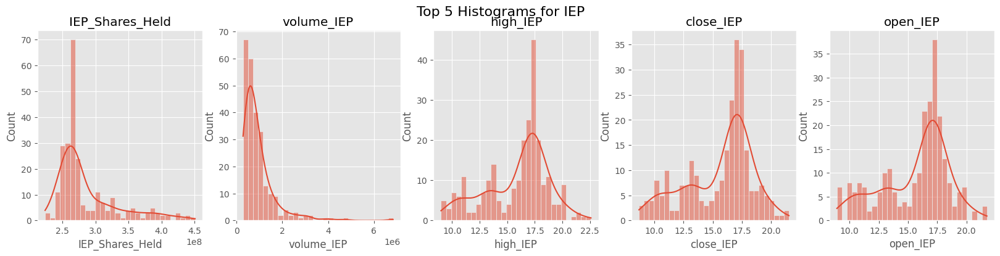

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
IEP_columns = [col for col in stock_data_updated2.columns if 'IEP' in col]

# Select only numeric columns
IEP_numeric = stock_data_updated2[IEP_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_IEP = IEP_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for IEP", fontsize=16)

for i, col in enumerate(top_5_IEP):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


Most distributions are right-skewed, implying that higher values are less frequent across all stock-related variables.
The $15–$18 price range appears to be a common threshold for IEP stock movements.
The IEP_Shares_Held and volume_IEP distributions indicate a concentration of trading activity at lower levels, with a few high-value outliers.

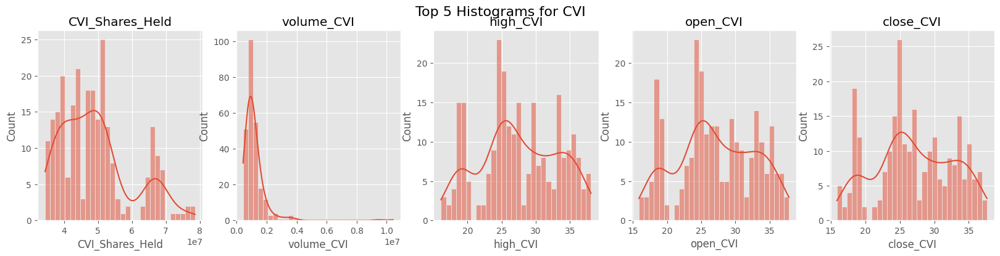

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
CVI_columns = [col for col in stock_data_updated2.columns if 'CVI' in col]

# Select only numeric columns
CVI_numeric = stock_data_updated2[CVI_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_CVI = CVI_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for CVI", fontsize=16)

for i, col in enumerate(top_5_CVI):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

The distribution of key metrics for CVI reveals potential trends and patterns in trading behavior. Price distributions appear to be clustered, indicating periods of relative stability with occasional spikes in volume and price.

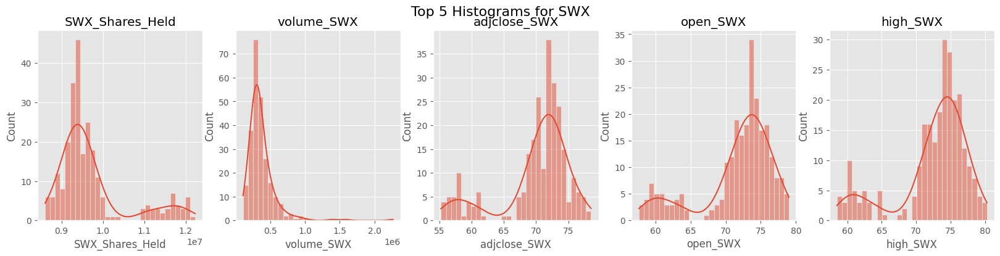

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
SWX_columns = [col for col in stock_data_updated2.columns if 'SWX' in col]

# Select only numeric columns
SWX_numeric = stock_data_updated2[SWX_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_SWX = SWX_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for SWX", fontsize=16)

for i, col in enumerate(top_5_SWX):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()


The histograms for SWX show fluctuations in Adjusted Closing and Opening prices over time, possibly indicating changing market sentiment or volatility. Trading volume distribution is right-skewed with instances of high activity.

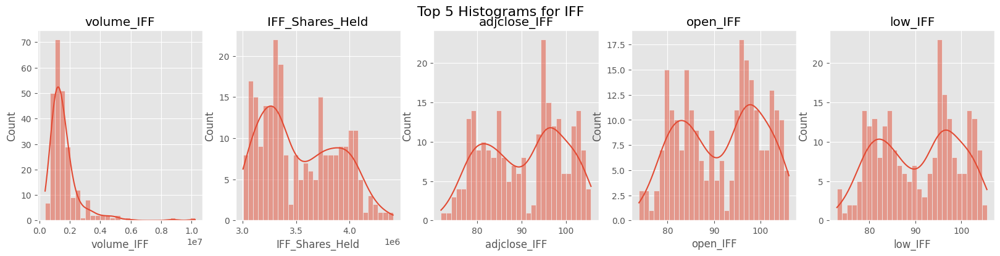

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
IFF_columns = [col for col in stock_data_updated2.columns if 'IFF' in col]

# Select only numeric columns
IFF_numeric = stock_data_updated2[IFF_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_IFF = IFF_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for IFF", fontsize=16)

for i, col in enumerate(top_5_IFF):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

The histograms for IFF show similar patterns to SWX, suggesting fluctuations in price and trading volume. The analysis also highlights a tendency for stock price changes to cluster around certain price levels.

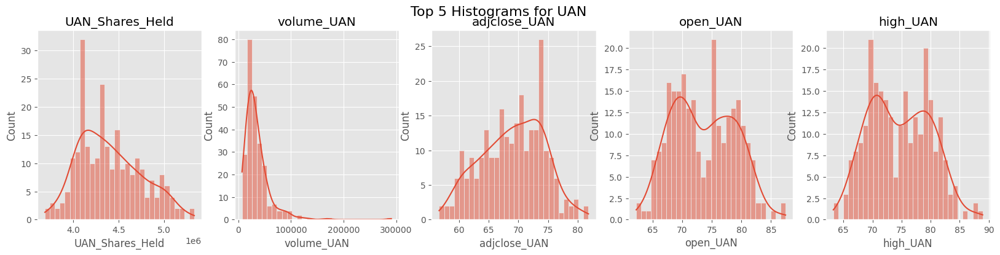

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
UAN_columns = [col for col in stock_data_updated2.columns if 'UAN' in col]

# Select only numeric columns
UAN_numeric = stock_data_updated2[UAN_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_UAN = UAN_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for UAN", fontsize=16)

for i, col in enumerate(top_5_UAN):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

The data distribution for UAN reveals variations in Adjusted Closing and Opening prices, indicating potential shifts in market dynamics or trading activity. Shareholding distribution shows shifts in ownership patterns.

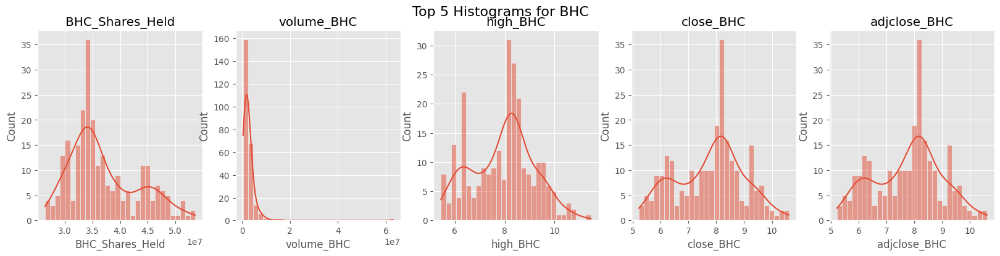

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
BHC_columns = [col for col in stock_data_updated2.columns if 'BHC' in col]

# Select only numeric columns
BHC_numeric = stock_data_updated2[BHC_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_BHC = BHC_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for BHC", fontsize=16)

for i, col in enumerate(top_5_BHC):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

 Histograms for BHC show similar characteristics to SWX, suggesting potential market volatility and price fluctuations. Shareholding analysis reveals clusters of ownership patterns.

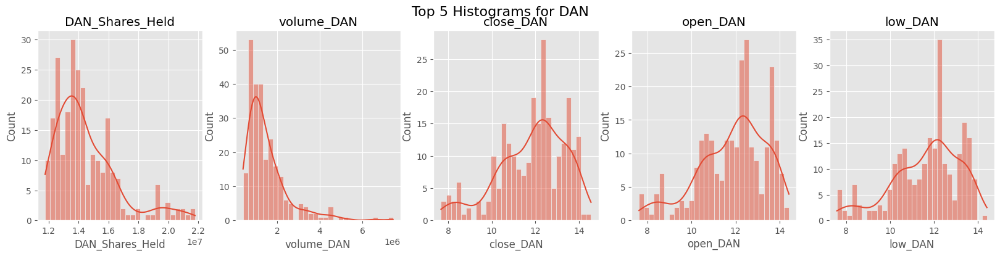

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
DAN_columns = [col for col in stock_data_updated2.columns if 'DAN' in col]

# Select only numeric columns
DAN_numeric = stock_data_updated2[DAN_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_DAN = DAN_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for DAN", fontsize=16)

for i, col in enumerate(top_5_DAN):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

The distribution of key metrics for DAN reveals fluctuations in opening and closing prices. Trading activity remains consistent within a lower range, with infrequent periods of high-volume activity.

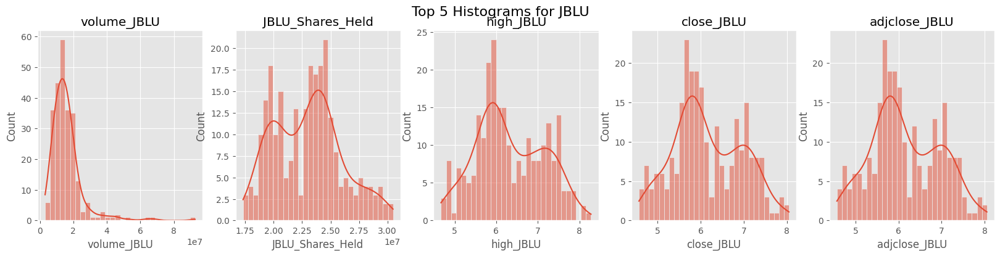

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
JBLU_columns = [col for col in stock_data_updated2.columns if 'JBLU' in col]

# Select only numeric columns
JBLU_numeric = stock_data_updated2[JBLU_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_JBLU = JBLU_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for JBLU", fontsize=16)

for i, col in enumerate(top_5_JBLU):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

The histograms for JBLU demonstrate fluctuations in trading volume, with some instances of high activity. Price distributions show a clustering pattern around certain levels.

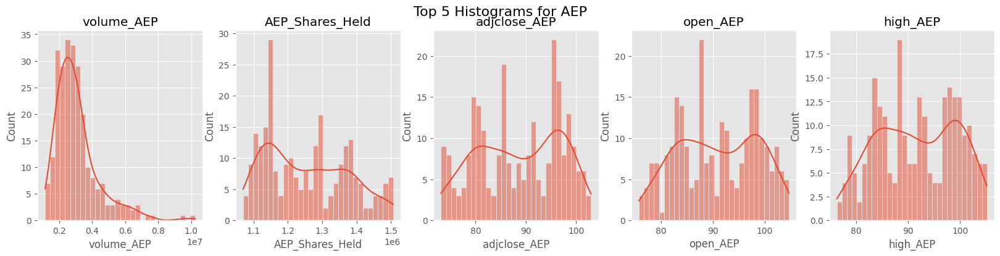

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
AEP_columns = [col for col in stock_data_updated2.columns if 'AEP' in col]

# Select only numeric columns
AEP_numeric = stock_data_updated2[AEP_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_AEP = AEP_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for AEP", fontsize=16)

for i, col in enumerate(top_5_AEP):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

The data distribution for AEP reveals potential market volatility with periods of price fluctuations. Shareholding analysis indicates changes in ownership patterns over time.

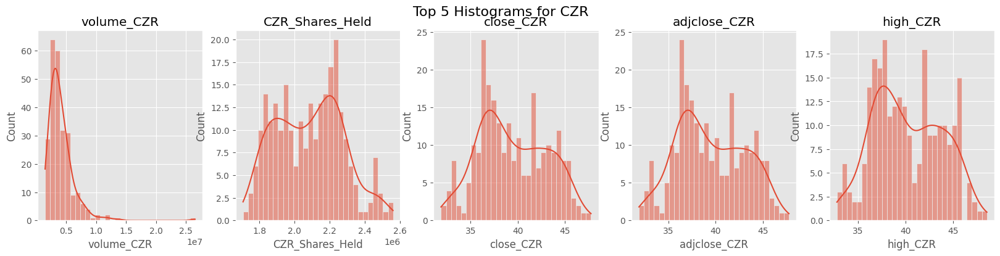

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
CZR_columns = [col for col in stock_data_updated2.columns if 'CZR' in col]

# Select only numeric columns
CZR_numeric = stock_data_updated2[CZR_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_CZR = CZR_numeric.var().nlargest(5).index.tolist()

# Plot histograms for top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle("Top 5 Histograms for CZR", fontsize=16)

for i, col in enumerate(top_5_CZR):
    sns.histplot(stock_data_updated2[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

plt.show()

Histograms for CZR exhibit similar patterns to SWX and BHC, suggesting price variations and trading behavior with periods of market volatility.

### Boxplots

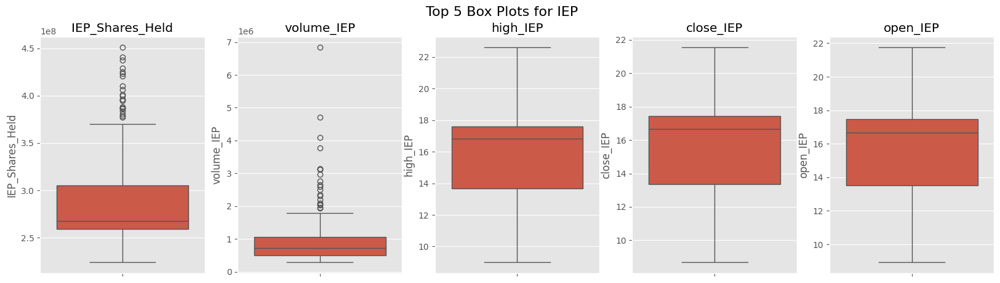

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
IEP_columns = [col for col in stock_data_updated2.columns if 'IEP' in col]

# Select only numeric columns
IEP_numeric = stock_data_updated2[IEP_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_IEP = IEP_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for IEP", fontsize=16)

for i, col in enumerate(top_5_IEP):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for IEP highlight a concentration of data within the IQR for adjusted close, open, high, and low prices. The long upper whisker for Volume suggests the presence of potential outliers, reflecting periods of high trading activity.



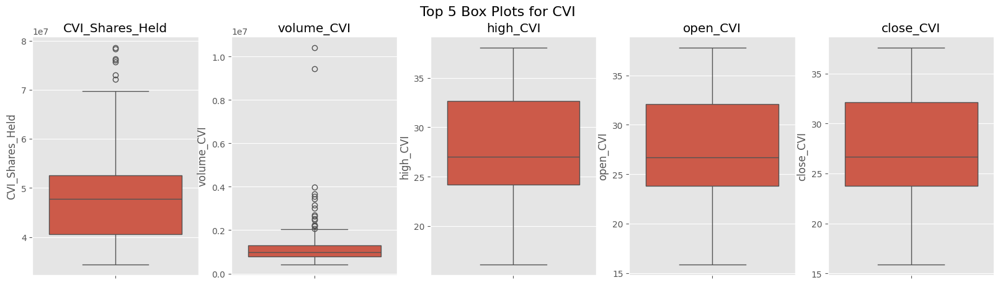

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
CVI_columns = [col for col in stock_data_updated2.columns if 'CVI' in col]

# Select only numeric columns
CVI_numeric = stock_data_updated2[CVI_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_CVI = CVI_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for CVI", fontsize=16)

for i, col in enumerate(top_5_CVI):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for CVI reveal a relatively tight IQR for open, high, low, and adjusted close price, indicating price stability with occasional volatility. Volume distribution is wide with a longer upper whisker.

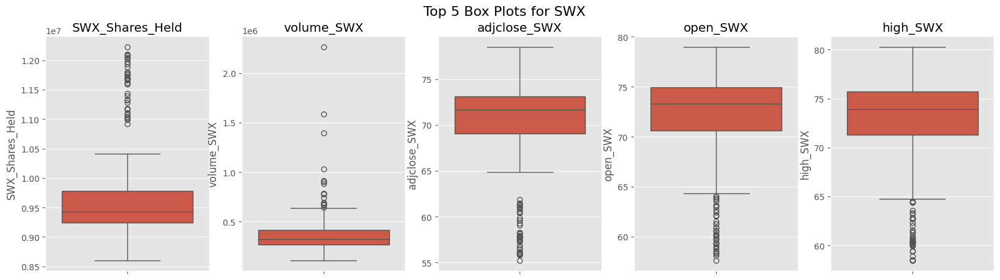

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
SWX_columns = [col for col in stock_data_updated2.columns if 'SWX' in col]

# Select only numeric columns
SWX_numeric = stock_data_updated2[SWX_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_SWX = SWX_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for SWX", fontsize=16)

for i, col in enumerate(top_5_SWX):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


 Box plots for SWX display variations in opening and closing prices. The presence of outliers in the volume box plot suggests periods of high trading activity compared to the typical range.

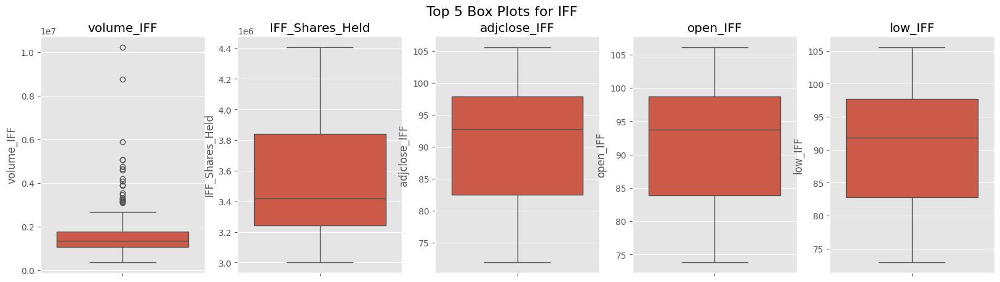

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
IFF_columns = [col for col in stock_data_updated2.columns if 'IFF' in col]

# Select only numeric columns
IFF_numeric = stock_data_updated2[IFF_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_IFF = IFF_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for IFF", fontsize=16)

for i, col in enumerate(top_5_IFF):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for IFF highlight fluctuations in price and trading volume. Similar to SWX, the presence of outliers in the volume box plot signals high trading activity.

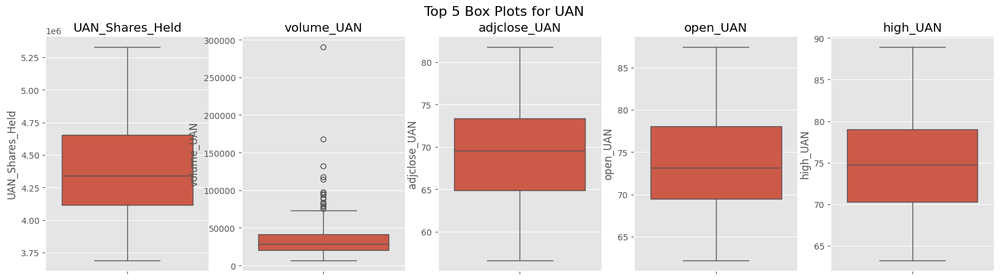

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
UAN_columns = [col for col in stock_data_updated2.columns if 'UAN' in col]

# Select only numeric columns
UAN_numeric = stock_data_updated2[UAN_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_UAN = UAN_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for UAN", fontsize=16)

for i, col in enumerate(top_5_UAN):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for UAN shows fluctuations in adjusted closing and opening prices. Upper and lower whiskers indicate volatility, while potential outliers in volume highlight significant variations in trading activity.



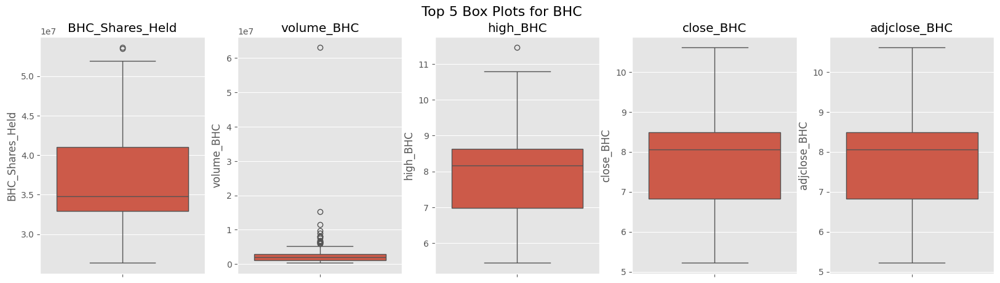

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
BHC_columns = [col for col in stock_data_updated2.columns if 'BHC' in col]

# Select only numeric columns
BHC_numeric = stock_data_updated2[BHC_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_BHC = BHC_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for BHC", fontsize=16)

for i, col in enumerate(top_5_BHC):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for BHC suggest potential market volatility and price fluctuations, with upper whiskers suggesting volatility and outliers in volume indicating periods of high trading activity.

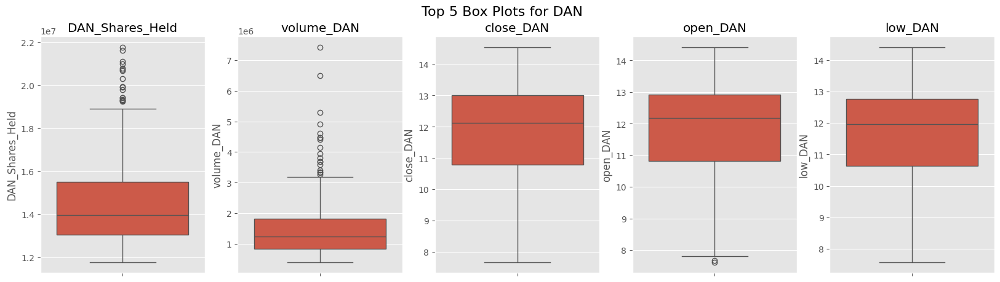

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
DAN_columns = [col for col in stock_data_updated2.columns if 'DAN' in col]

# Select only numeric columns
DAN_numeric = stock_data_updated2[DAN_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_DAN = DAN_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for DAN", fontsize=16)

for i, col in enumerate(top_5_DAN):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for DAN reveals fluctuations in opening and closing prices, with longer whiskers suggesting more variability compared to other stocks. Volume distribution is wide with a longer upper whisker.

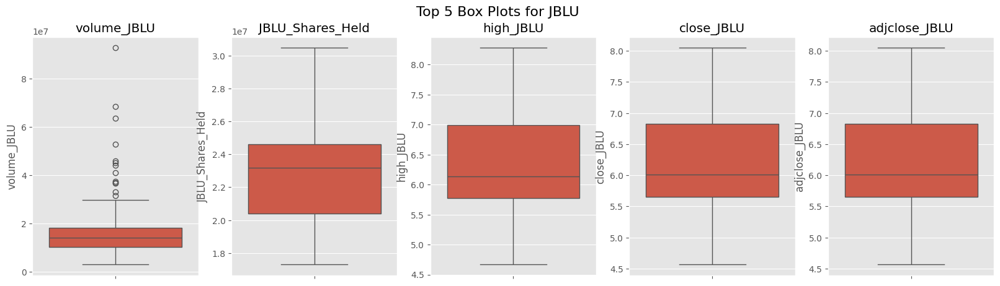

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
JBLU_columns = [col for col in stock_data_updated2.columns if 'JBLU' in col]

# Select only numeric columns
JBLU_numeric = stock_data_updated2[JBLU_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_JBLU = JBLU_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for JBLU", fontsize=16)

for i, col in enumerate(top_5_JBLU):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for JBLU highlight fluctuations in trading volume, with a larger IQR indicating variability. Longer whiskers and potential outliers suggest occasional surges in trading activity

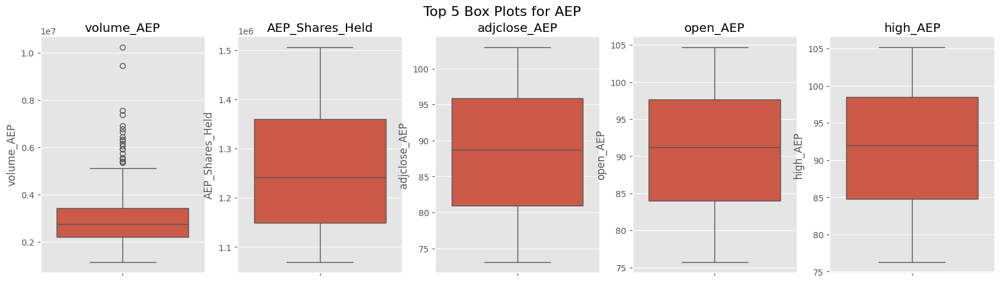

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
AEP_columns = [col for col in stock_data_updated2.columns if 'AEP' in col]

# Select only numeric columns
AEP_numeric = stock_data_updated2[AEP_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_AEP = AEP_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for AEP", fontsize=16)

for i, col in enumerate(top_5_AEP):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for AEP suggest potential market volatility with periods of price fluctuations. The presence of upper whiskers and outliers in volume data suggest significant variability in trading activity.

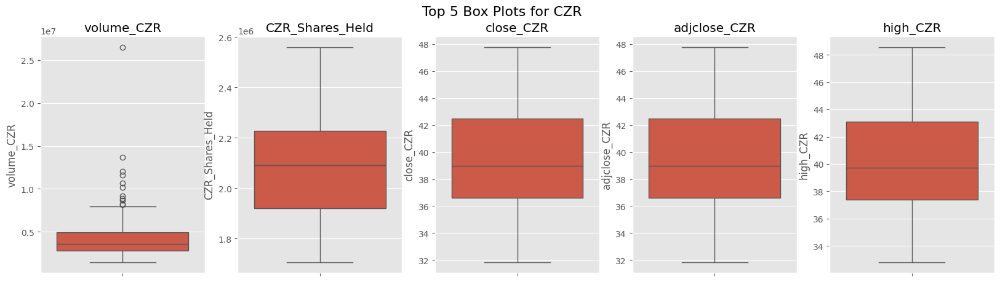

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
# stock_data_updated = pd.read_csv('your_file.csv')  # Uncomment if loading from CSV

# Filter COCP columns
CZR_columns = [col for col in stock_data_updated2.columns if 'CZR' in col]

# Select only numeric columns
CZR_numeric = stock_data_updated2[CZR_columns].select_dtypes(include=np.number)

# Find the top 5 most variable columns based on variance
top_5_CZR = CZR_numeric.var().nlargest(5).index.tolist()

# Plot box plots for the top 5 columns
plt.style.use('ggplot')
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Top 5 Box Plots for CZR", fontsize=16)

for i, col in enumerate(top_5_CZR):
    sns.boxplot(y=stock_data_updated2[col], ax=axes[i])
    axes[i].set_title(col)

plt.show()


Box plots for CZR reveal price variations and trading behavior with periods of market volatility, with longer upper whiskers highlighting more extreme price fluctuations.

## Bivariate Analysis

### Correlation Matrix

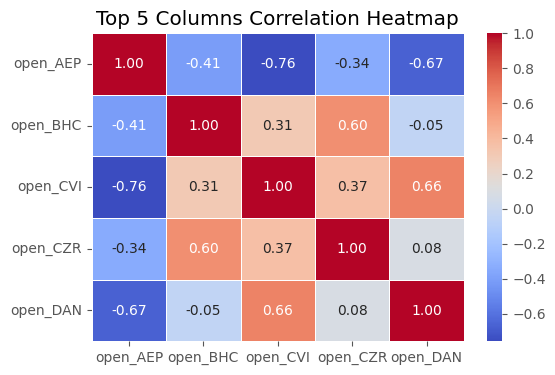

Top 5 Columns Correlation Matrix:
          open_AEP  open_BHC  open_CVI  open_CZR  open_DAN
open_AEP  1.000000 -0.407909 -0.756574 -0.338580 -0.671194
open_BHC -0.407909  1.000000  0.309248  0.603829 -0.047611
open_CVI -0.756574  0.309248  1.000000  0.373903  0.655612
open_CZR -0.338580  0.603829  0.373903  1.000000  0.082670
open_DAN -0.671194 -0.047611  0.655612  0.082670  1.000000


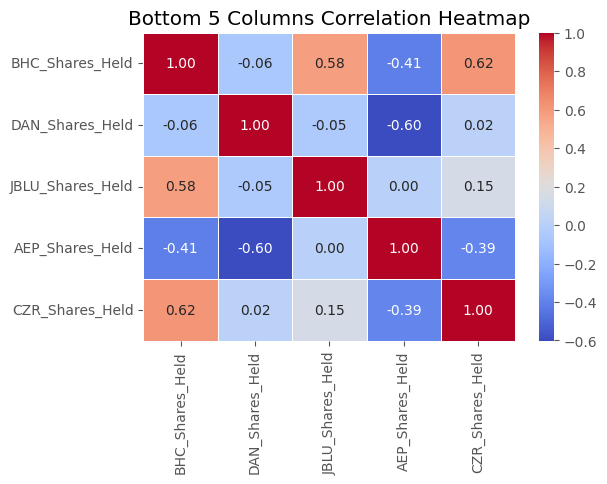

Bottom 5 Columns Correlation Matrix:
                  BHC_Shares_Held  DAN_Shares_Held  JBLU_Shares_Held  \
BHC_Shares_Held          1.000000        -0.060538          0.578465   
DAN_Shares_Held         -0.060538         1.000000         -0.046557   
JBLU_Shares_Held         0.578465        -0.046557          1.000000   
AEP_Shares_Held         -0.407110        -0.600917          0.001988   
CZR_Shares_Held          0.617743         0.017230          0.146814   

                  AEP_Shares_Held  CZR_Shares_Held  
BHC_Shares_Held         -0.407110         0.617743  
DAN_Shares_Held         -0.600917         0.017230  
JBLU_Shares_Held         0.001988         0.146814  
AEP_Shares_Held          1.000000        -0.388066  
CZR_Shares_Held         -0.388066         1.000000  


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming stock_data_updated is your DataFrame
# Get the top 5 and bottom 5 columns
columns = stock_data_updated2.columns.tolist()
top_5 = columns[:5]  # First 5 columns
bottom_5 = columns[-5:]  # Last 5 columns

# Compute correlation matrix and heatmap for top 5 columns
subset_top5_df2 = stock_data_updated2[top_5]
top5_correlation_matrix2 = subset_top5_df2.corr()

plt.figure(figsize=(6, 4))
sns.heatmap(top5_correlation_matrix2, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Top 5 Columns Correlation Heatmap")
plt.show()

print("Top 5 Columns Correlation Matrix:")
print(top5_correlation_matrix2)

# Compute correlation matrix and heatmap for bottom 5 columns
subset_bottom5_df2 = stock_data_updated2[bottom_5]
bottom5_correlation_matrix2 = subset_bottom5_df2.corr()

plt.figure(figsize=(6, 4))
sns.heatmap(bottom5_correlation_matrix2, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Bottom 5 Columns Correlation Heatmap")
plt.show()

print("Bottom 5 Columns Correlation Matrix:")
print(bottom5_correlation_matrix2)



Top 5 Columns Correlation Matrix

The top 5 columns primarily consist of adjusted closing prices for different stocks (IEP, CVI, SWX, IFF, UAN). The correlation matrix for these columns reveals the following:

Strong Positive Correlations: There are strong positive correlations between the adjusted closing prices of different stocks. This suggests that these stocks tend to move in the same direction, indicating a potential market-wide or sector-specific influence.
Moderate Positive Correlations: Moderate positive correlations are observed between some pairs of stocks, indicating a relatively weaker but still positive relationship.
Weak or No Correlations: Some pairs of stocks show weak or no correlations, implying that their price movements are relatively independent of each other.
Bottom 5 Columns Correlation Matrix

The bottom 5 columns primarily consist of shares held for different stocks (BHC, DAN, JBLU, AEP, CZR). The correlation matrix for these columns reveals the following:

Limited Correlations: There are limited significant correlations between the shares held for different stocks. This suggests that the ownership patterns of these stocks are relatively independent of each other.
Potential Weak Correlations: Some weak positive correlations might be observed between certain pairs of stocks, but further investigation is needed to confirm their significance.

### Pair plot

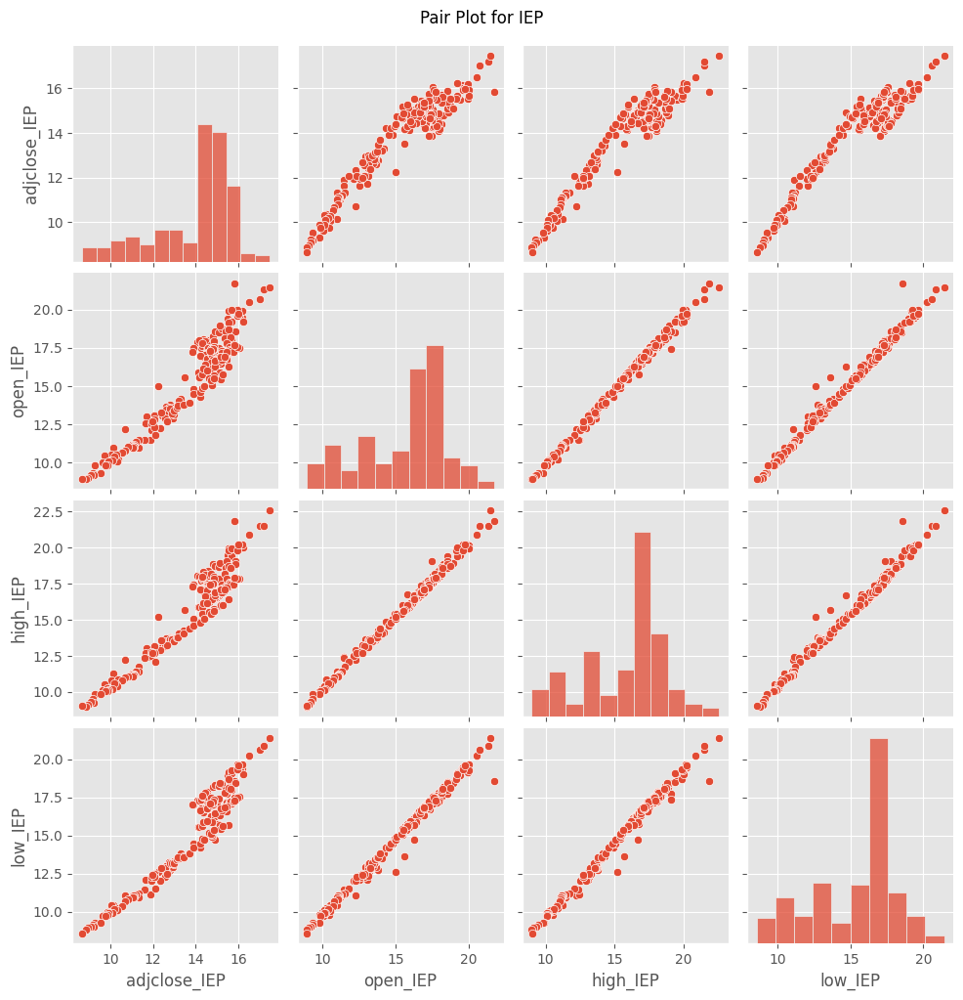

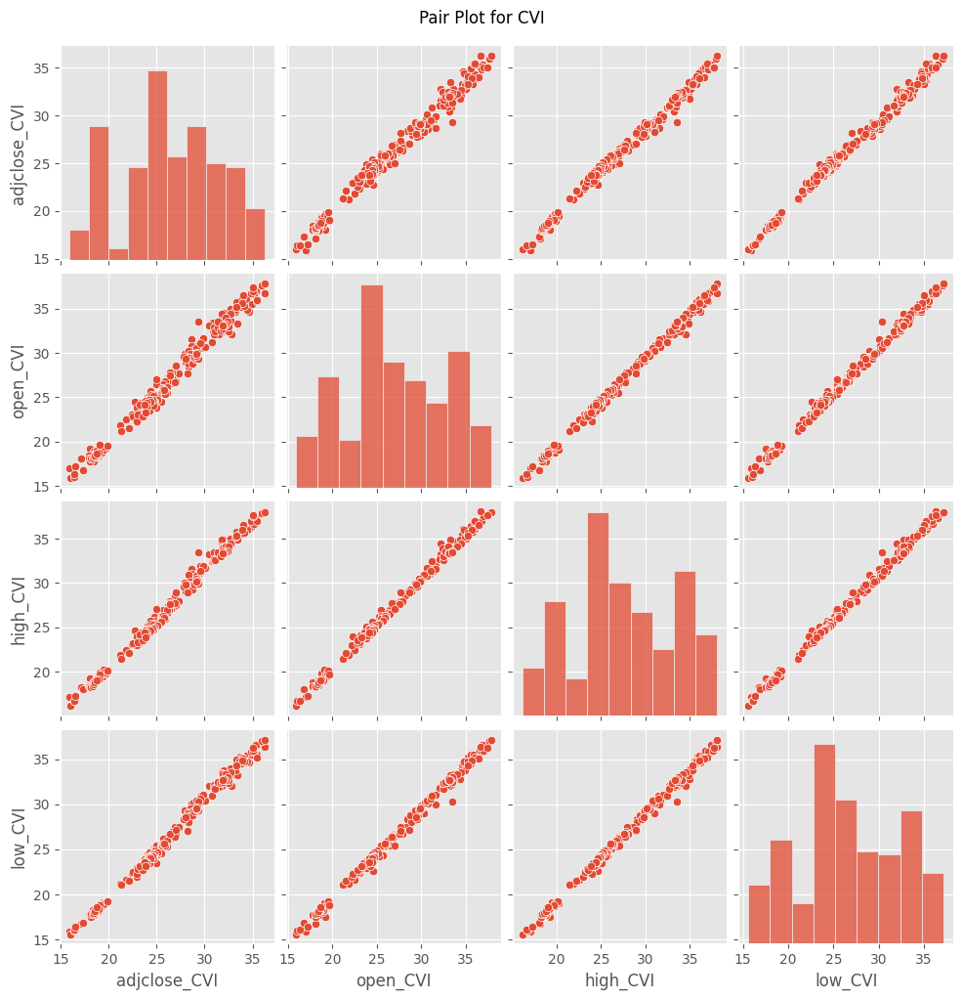

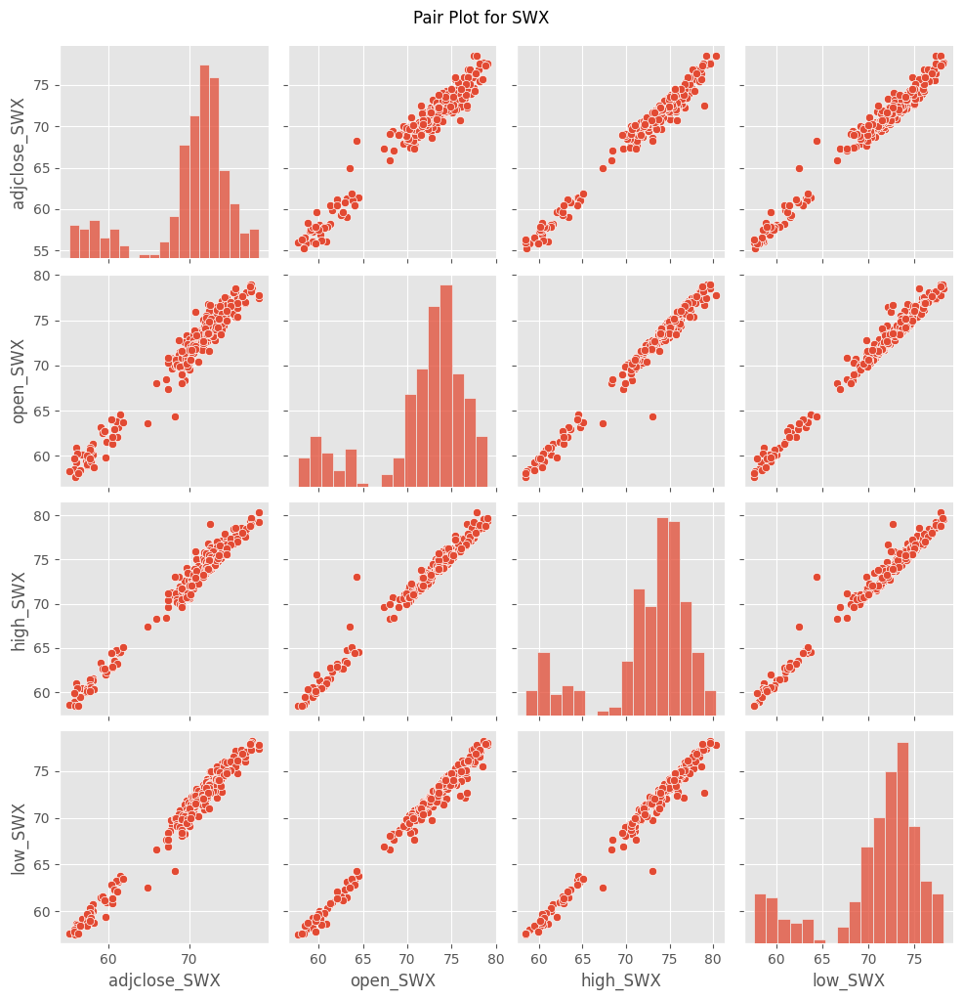

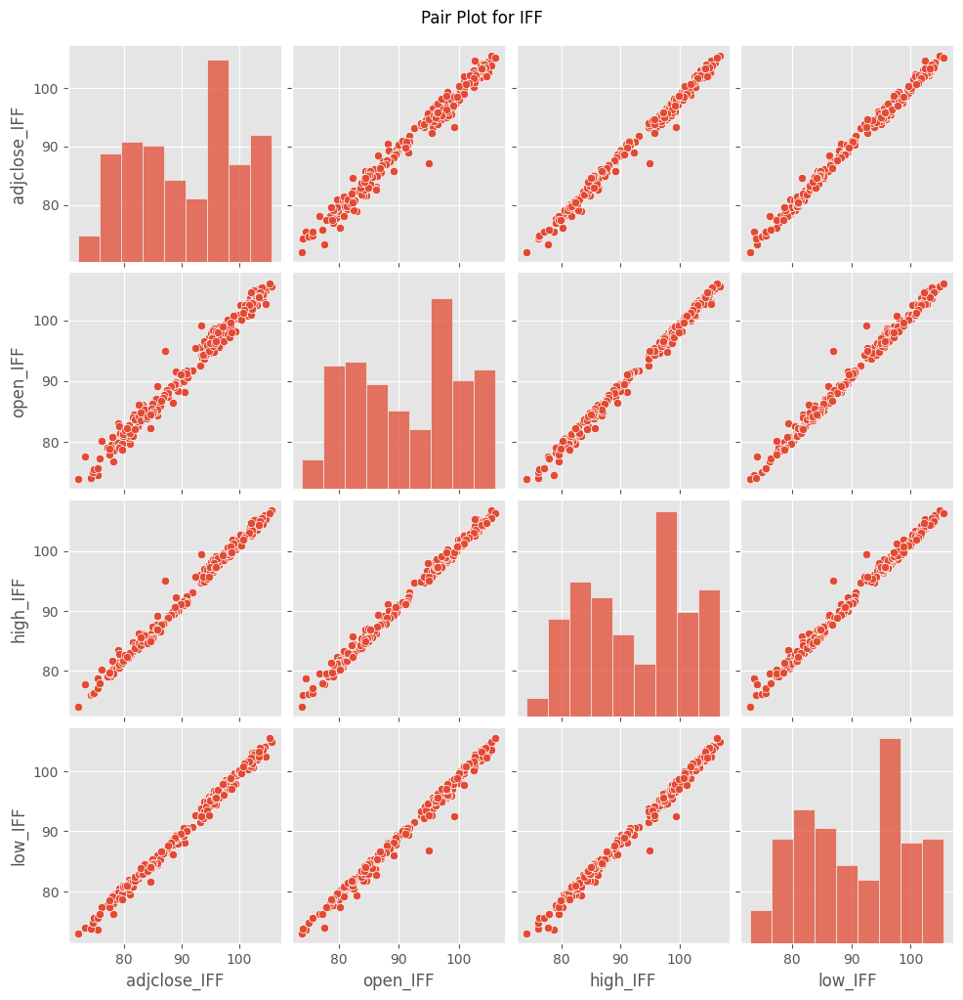

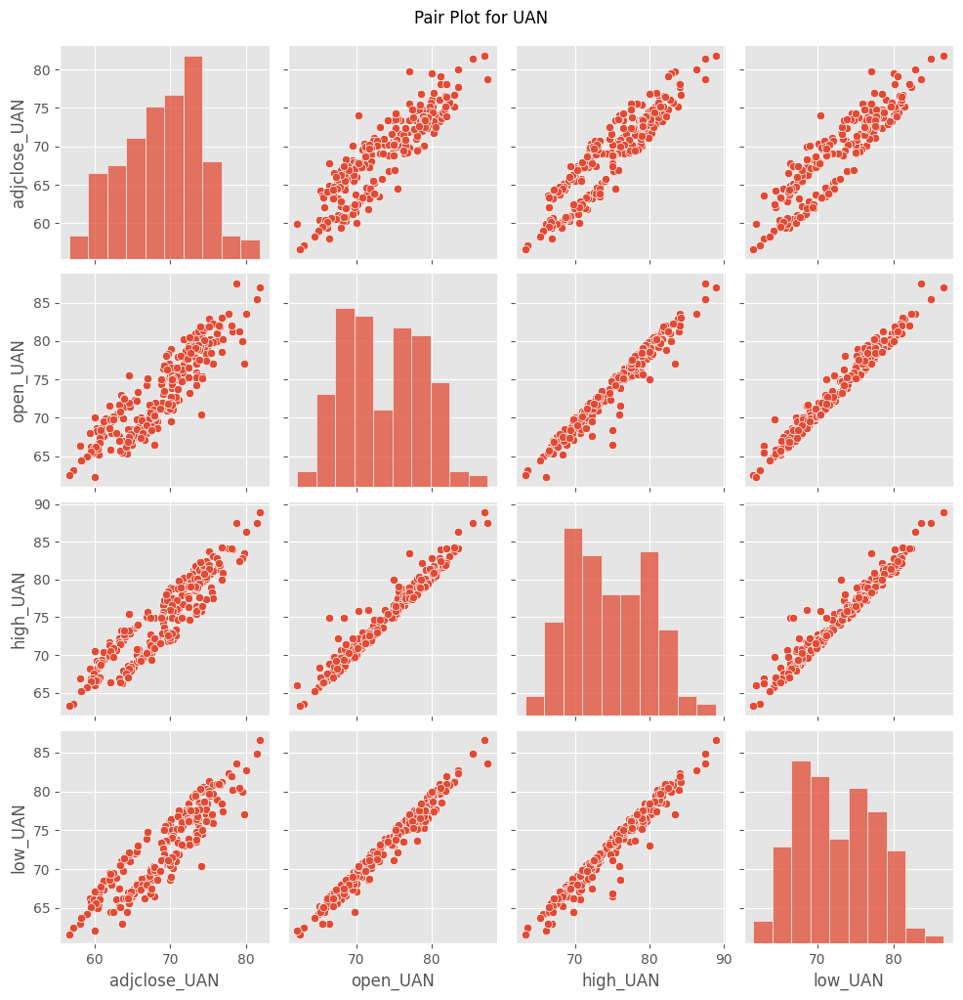

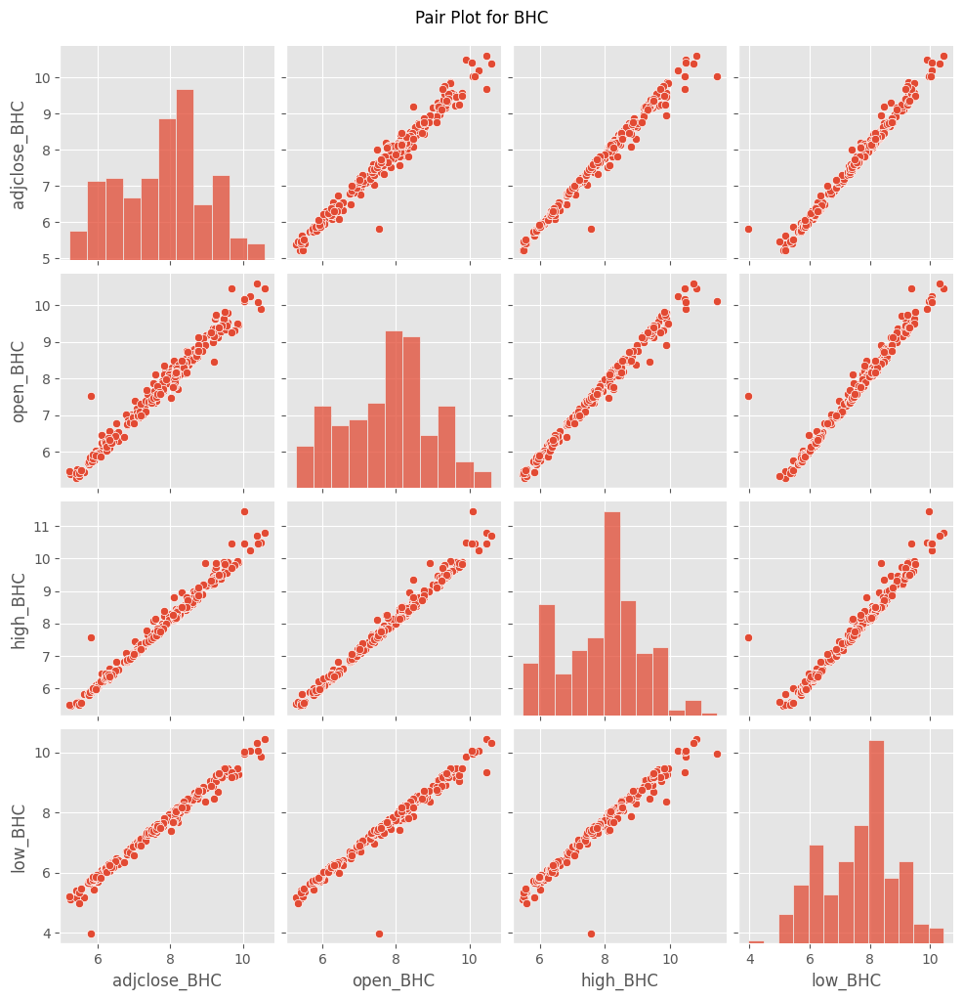

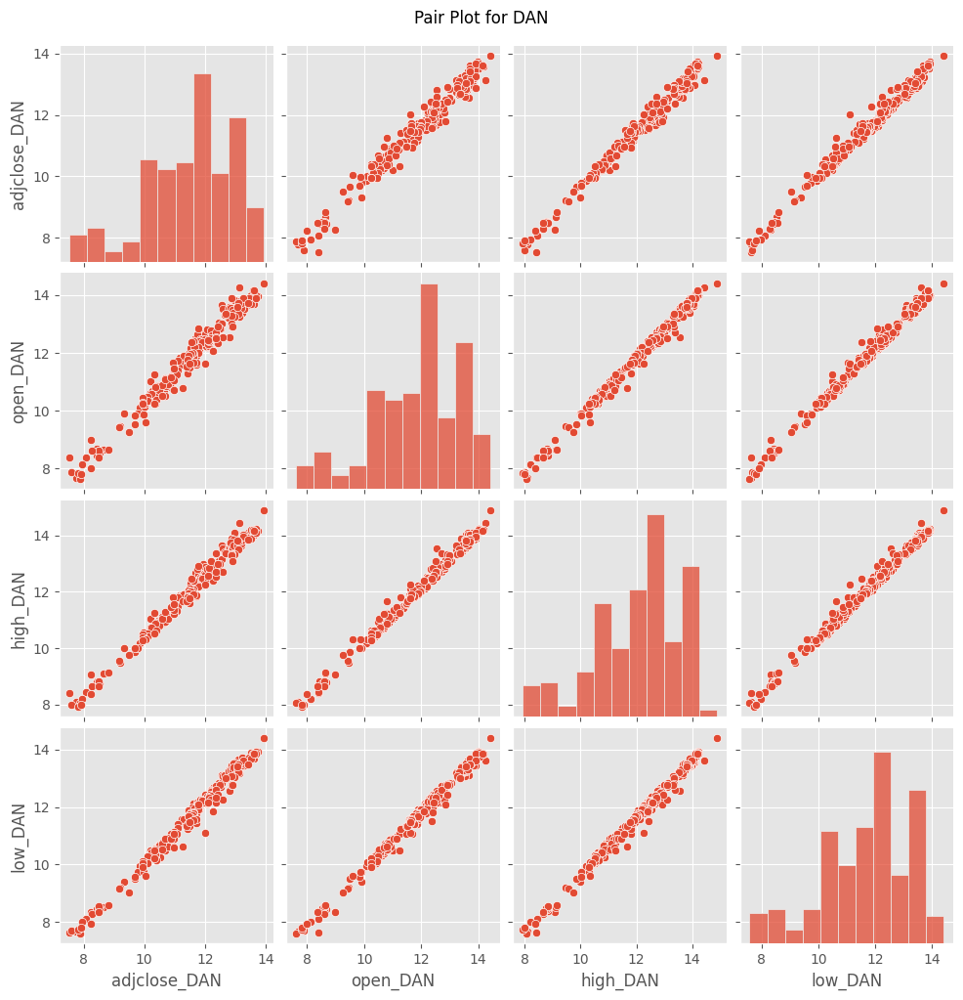

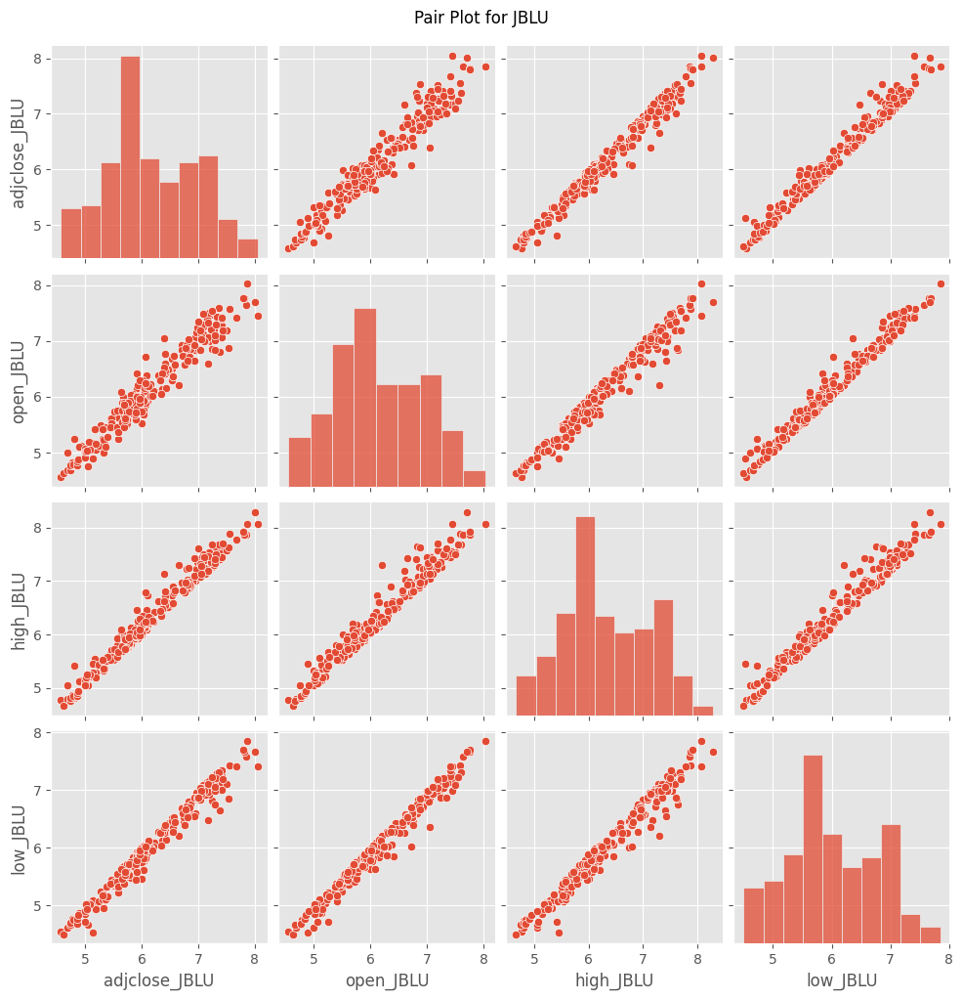

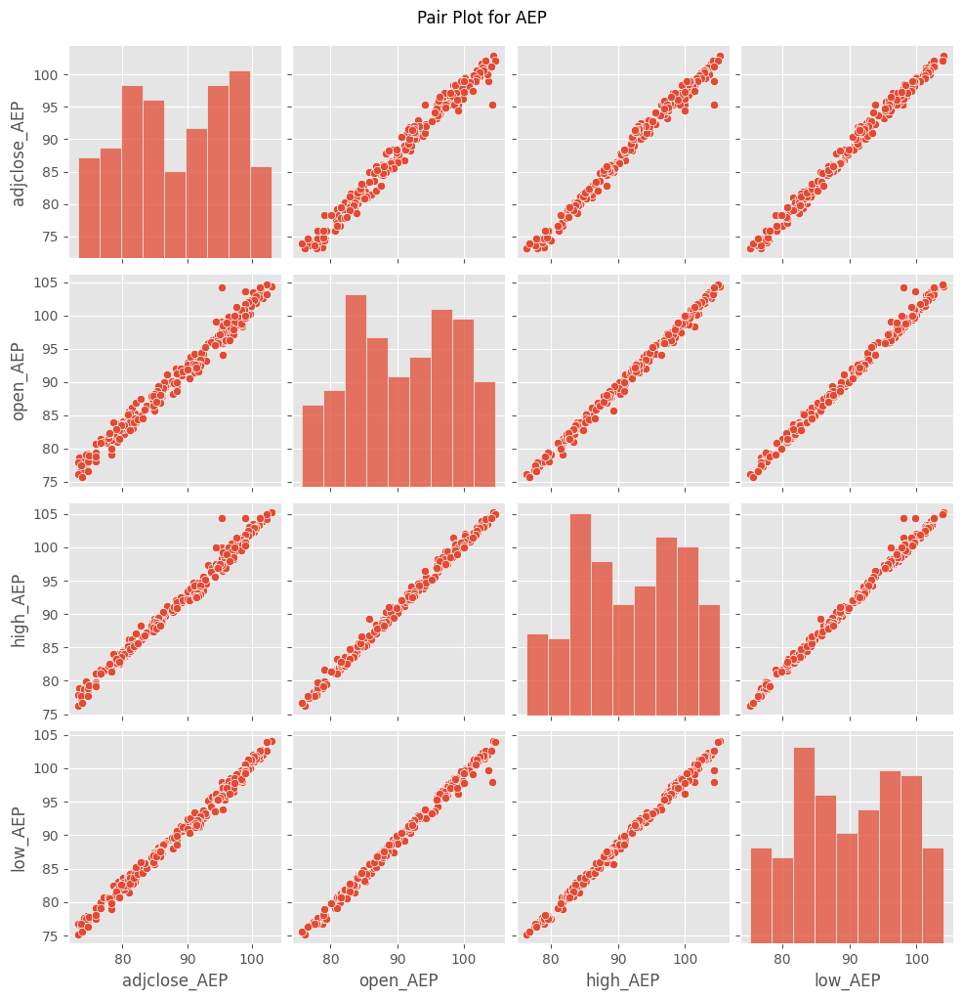

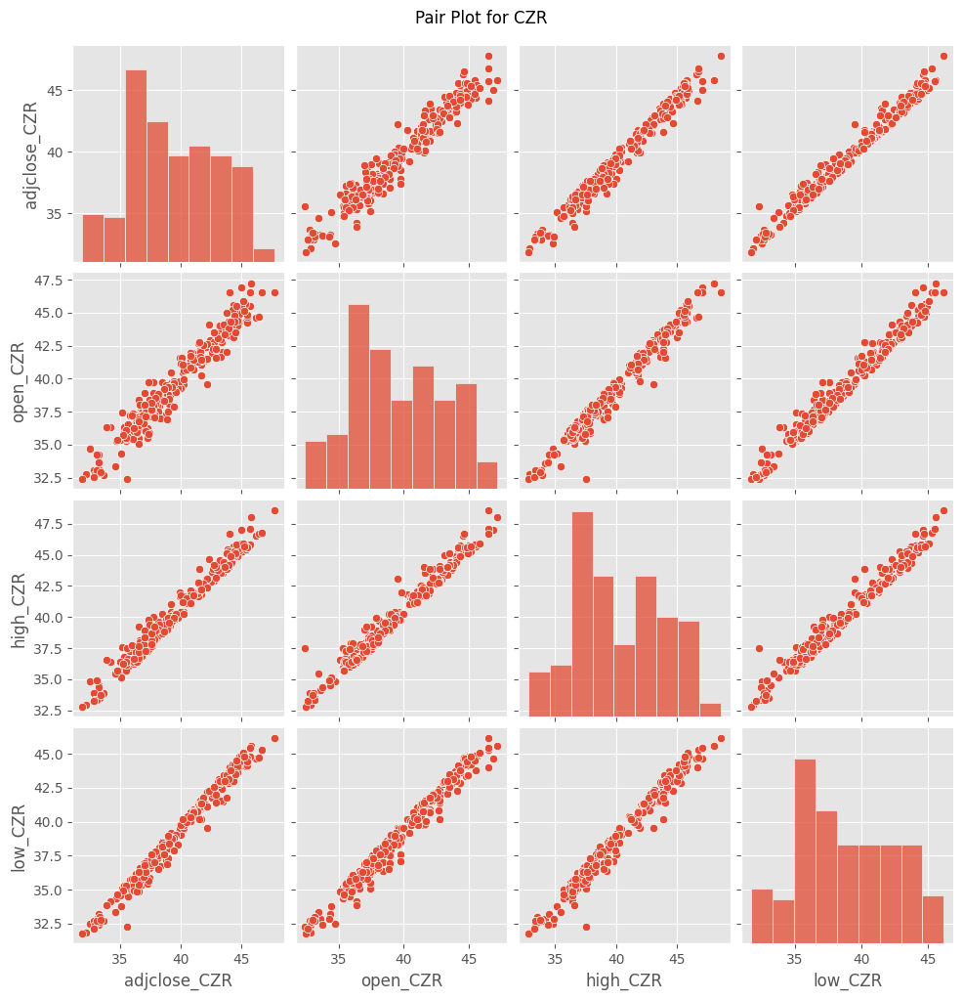

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract unique stock tickers from column names
stocks = ['IEP', 'CVI', 'SWX', 'IFF', 'UAN', 'BHC', 'DAN', 'JBLU', 'AEP', 'CZR']

# Loop through each stock and create pair plots
for stock in stocks:
    selected_columns = [f"adjclose_{stock}", f"open_{stock}", f"high_{stock}", f"low_{stock}"]

    # Ensure the columns exist in the DataFrame
    if all(col in stock_data_updated2.columns for col in selected_columns):
        sns.pairplot(stock_data_updated2[selected_columns])
        plt.suptitle(f"Pair Plot for {stock}", y=1.02)
        plt.show()

        # Print a blank line for spacing
        print("\n" * 3)  # Prints 3 newlines for better separation


General Trends: Across all stocks, there is a strong positive linear relationship between Adjusted Close, Open, High, and Low prices. This is expected as these prices are inherently related and often move in the same direction.
Variability: The spread of points in the scatter plots indicates the variability or volatility of the stock prices. Stocks with tighter clusters of points tend to have lower volatility compared to those with more dispersed points.
Outliers: Potential outliers can be observed in some scatter plots as points that deviate significantly from the general trend. These outliers might represent unusual trading days or events affecting the stock price.
Distribution: The histograms on the diagonal provide insights into the distribution of individual metrics. The shape of the histograms can reveal if the data is skewed, normally distributed, or has other interesting characteristics.
Specific Observations for Each Stock

While the general trends mentioned above apply to all stocks, here are some specific observations for each:

IEP, CVI, SWX, IFF, UAN, BHC, DAN, JBLU, AEP, CZR: All of these stocks exhibited the expected strong positive linear relationships between their price metrics (Open, High, Low, Adjusted Close). The degree of variability and presence of outliers varied slightly between them, suggesting differences in their volatility and potential impact of external factors.


### Scatter plots

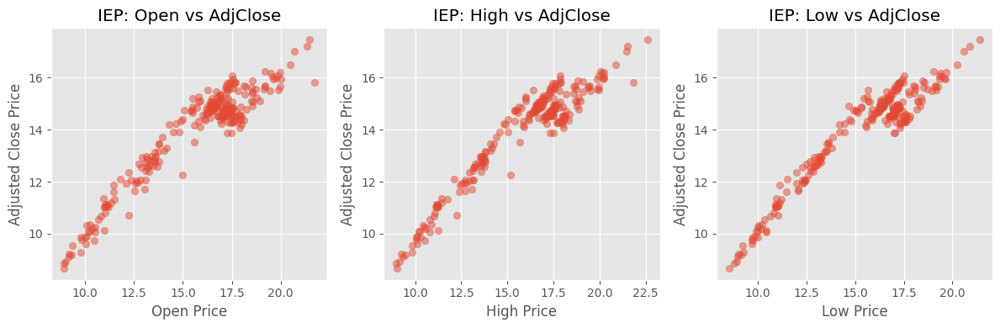

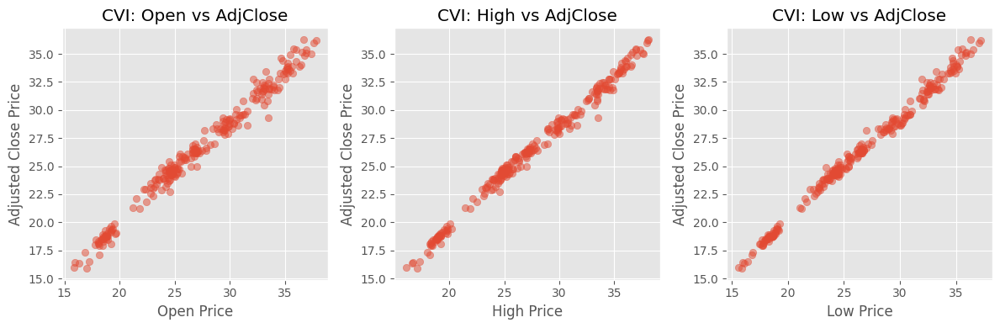

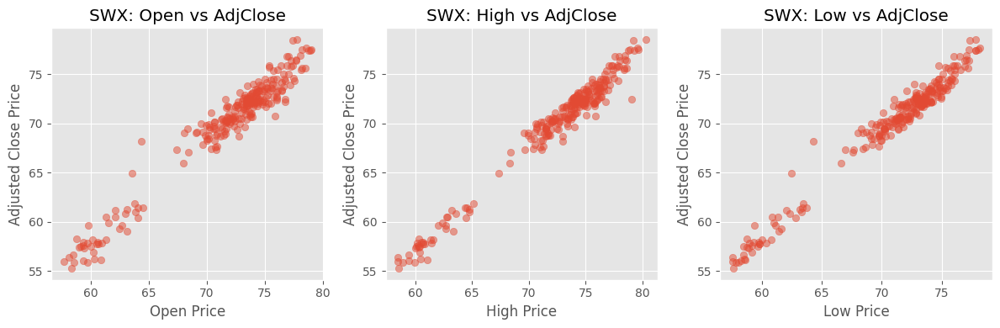

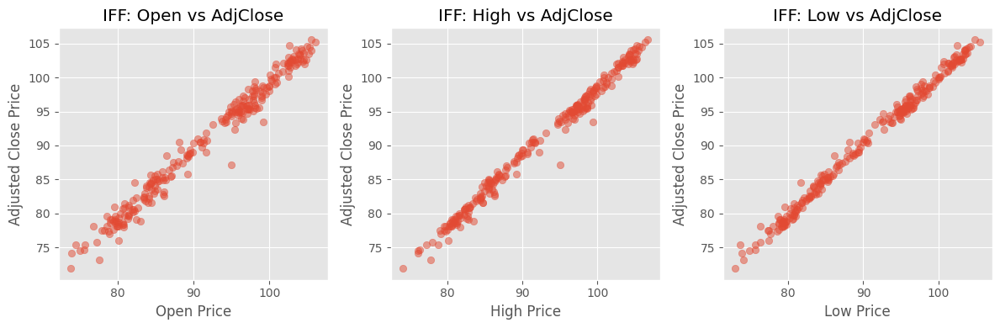

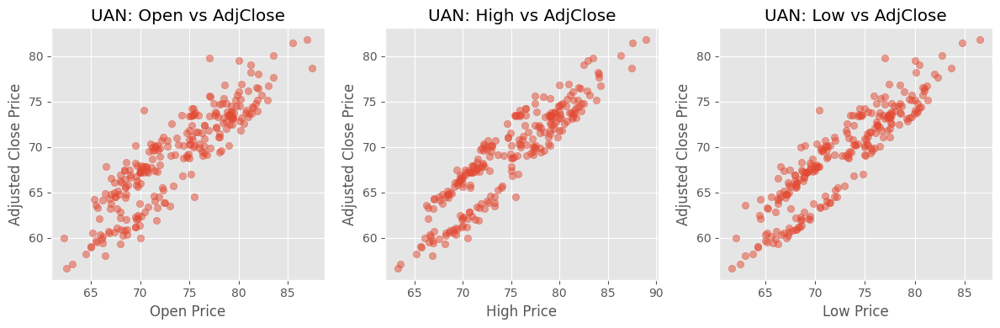

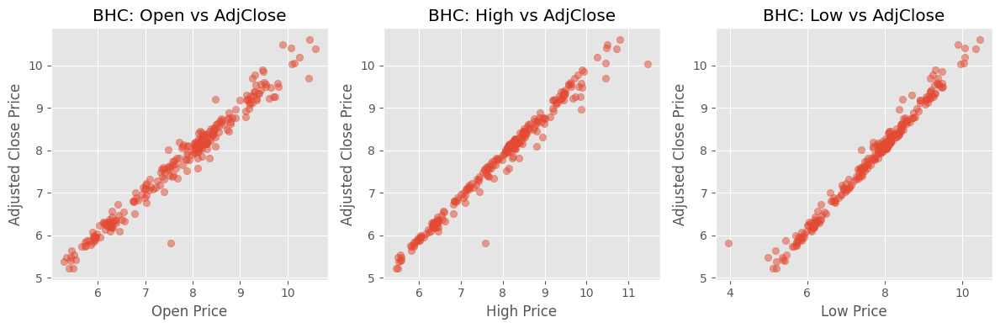

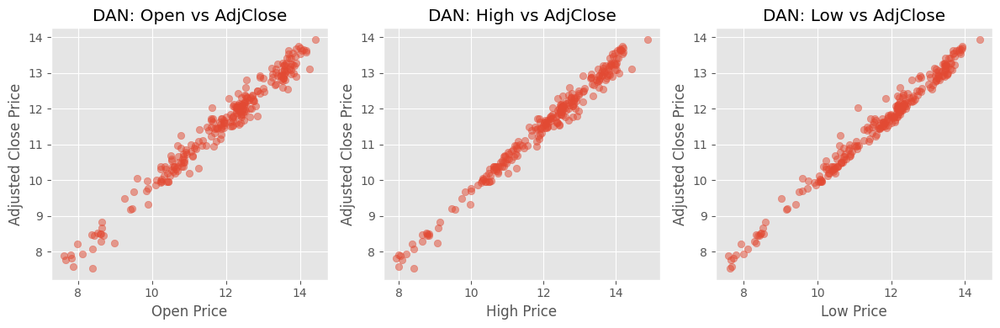

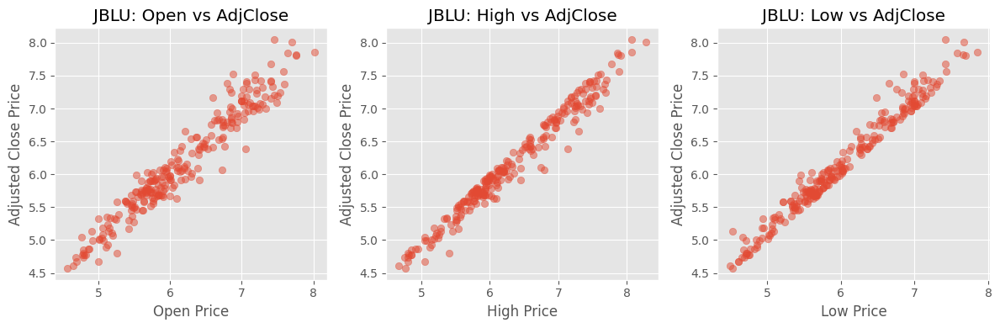

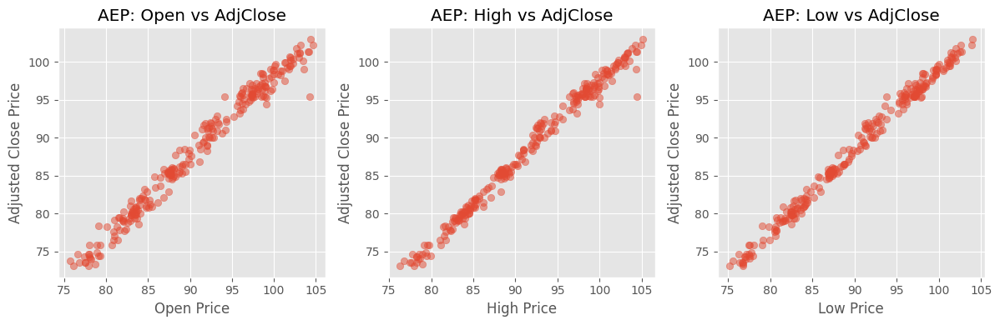

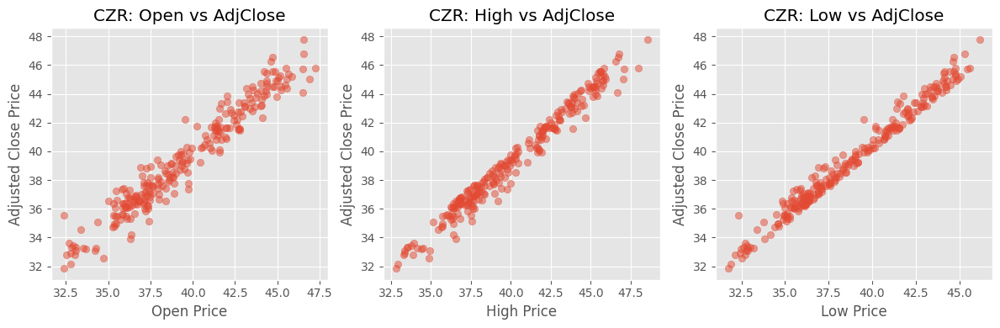

In [ ]:
import matplotlib.pyplot as plt

# Extract unique stock tickers from column names
stocks = ['IEP', 'CVI', 'SWX', 'IFF', 'UAN', 'BHC', 'DAN', 'JBLU', 'AEP', 'CZR']
# Loop through each stock and create scatter plots
for stock in stocks:
    selected_columns = [f"adjclose_{stock}", f"open_{stock}", f"high_{stock}", f"low_{stock}"]

    # Ensure the columns exist in the DataFrame
    if all(col in stock_data_updated2.columns for col in selected_columns):
        plt.figure(figsize=(12, 4))

        # Scatter plot for Open vs AdjClose
        plt.subplot(1, 3, 1)
        plt.scatter(stock_data_updated2[f"open_{stock}"], stock_data_updated2[f"adjclose_{stock}"], alpha=0.5)
        plt.xlabel("Open Price")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"{stock}: Open vs AdjClose")

        # Scatter plot for High vs AdjClose
        plt.subplot(1, 3, 2)
        plt.scatter(stock_data_updated2[f"high_{stock}"], stock_data_updated2[f"adjclose_{stock}"], alpha=0.5)
        plt.xlabel("High Price")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"{stock}: High vs AdjClose")

        # Scatter plot for Low vs AdjClose
        plt.subplot(1, 3, 3)
        plt.scatter(stock_data_updated2[f"low_{stock}"], stock_data_updated2[f"adjclose_{stock}"], alpha=0.5)
        plt.xlabel("Low Price")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"{stock}: Low vs AdjClose")

        # Adjust layout and show plot
        plt.tight_layout()
        plt.show()

        # Print space after each set of scatter plots
        print("\n" * 3)  # Adds extra space between each stock's plots

Observations

Here's a summary of the key observations from the scatter plots for each stock:

General Trend: Across all stocks, there is a strong positive linear relationship between Adjusted Close Price and Open, High, and Low prices. This indicates that when the opening, high, or low price of a stock increases, the adjusted closing price tends to increase as well.
Strength of Relationship: The strength of the relationship between Adjusted Close Price and other metrics appears to be strongest for High Price, followed by Open Price, and then Low Price. This is consistent with the expectation that the high price of a stock would have a greater influence on its closing price compared to the low price.
Variability: There is some variability in the data points around the general trend line, indicating that the relationship between the variables is not perfect. This variability can be attributed to various factors, such as market fluctuations and news events.
Outliers: In some cases, there are potential outliers in the scatter plots, represented by data points that deviate significantly from the general trend. These outliers may warrant further investigation to understand the underlying reasons for their deviation.
Specific Observations for Each Stock

While the general trend mentioned above applies to all stocks (IEP, CVI, SWX, IFF, UAN, BHC, DAN, JBLU, AEP, CZR), there might be slight differences in the strength of the relationship and the presence of outliers for each stock. However, the overall pattern of a positive linear relationship between Adjusted Close Price and other price metrics remains consistent across all stocks.

## Multivariate

### Time Series

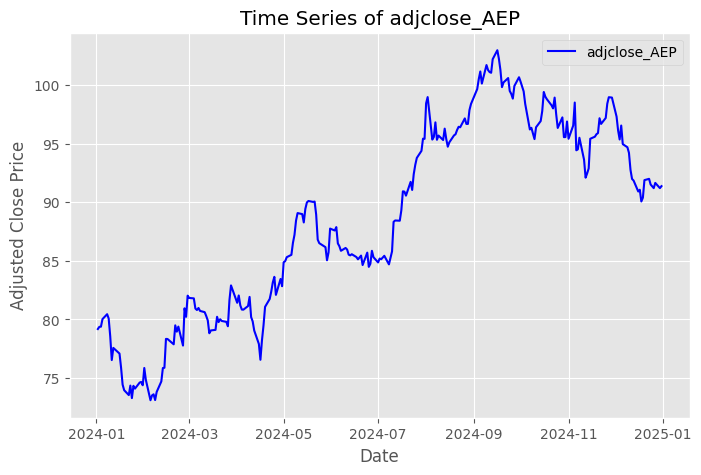

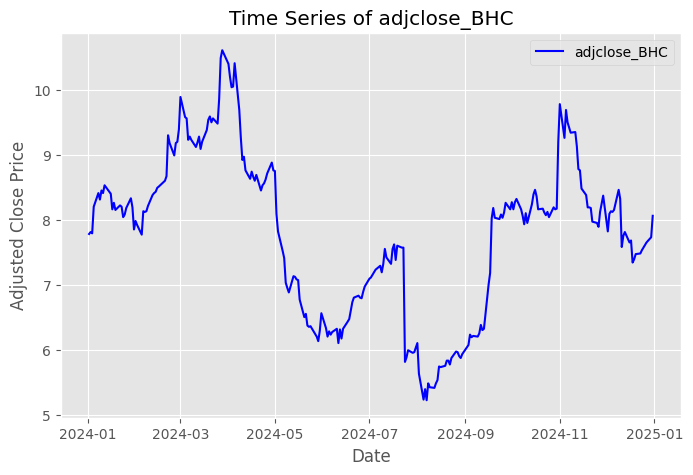

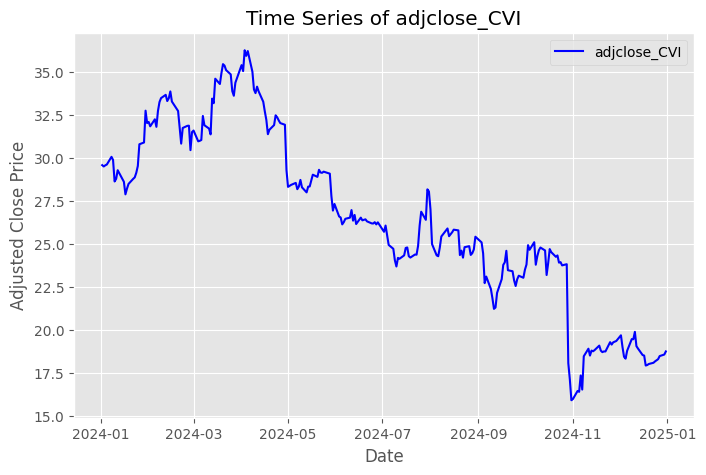

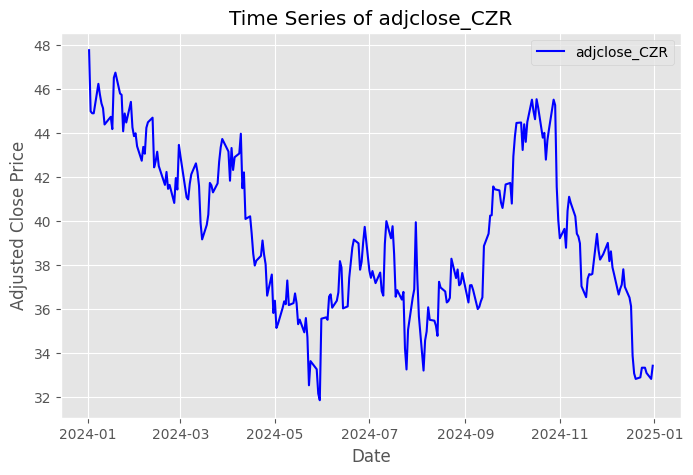

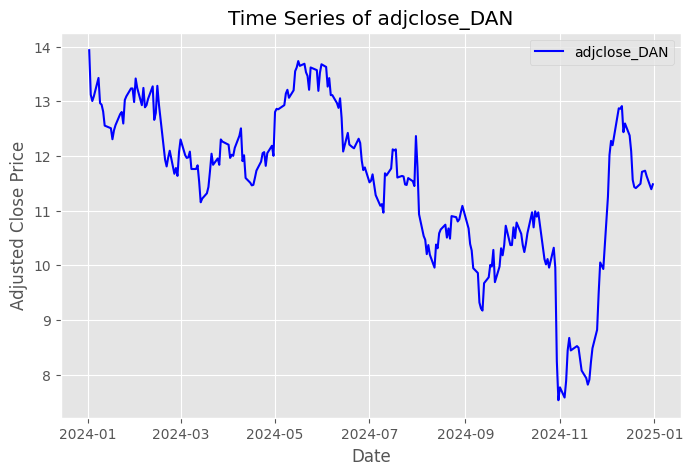

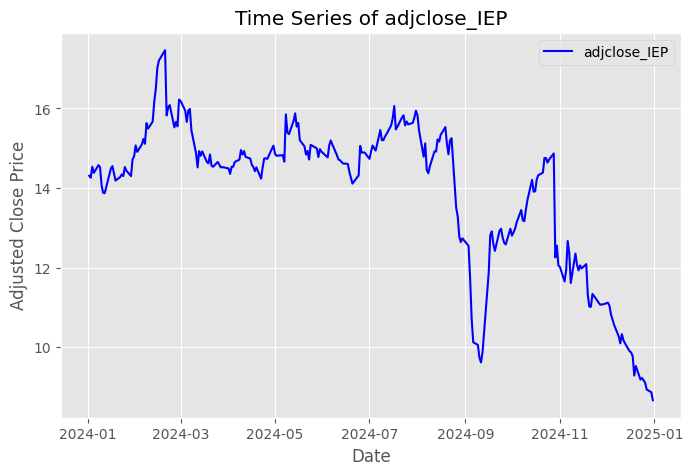

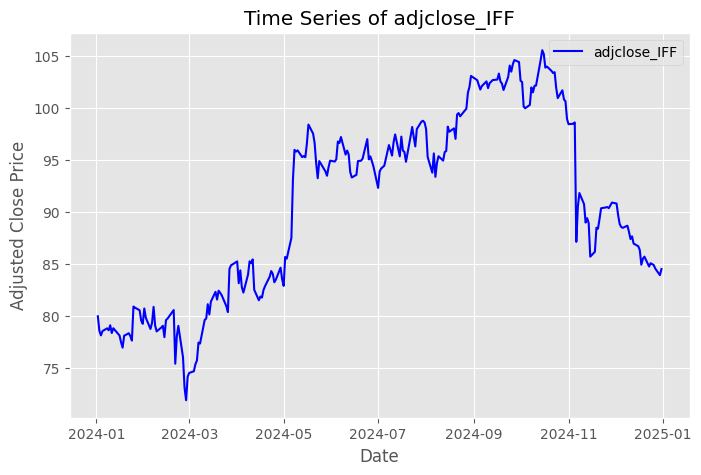

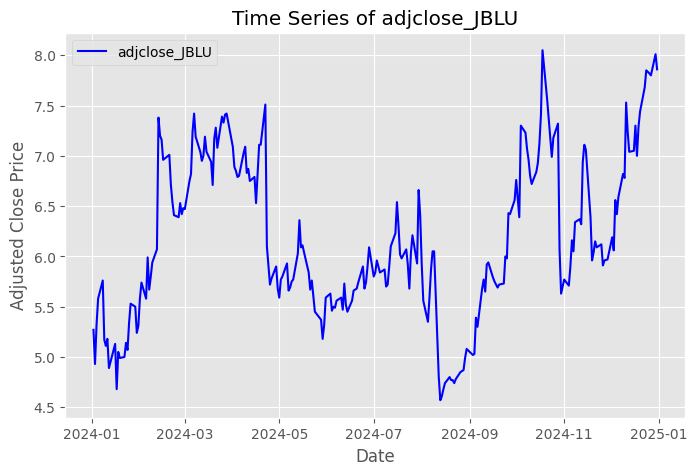

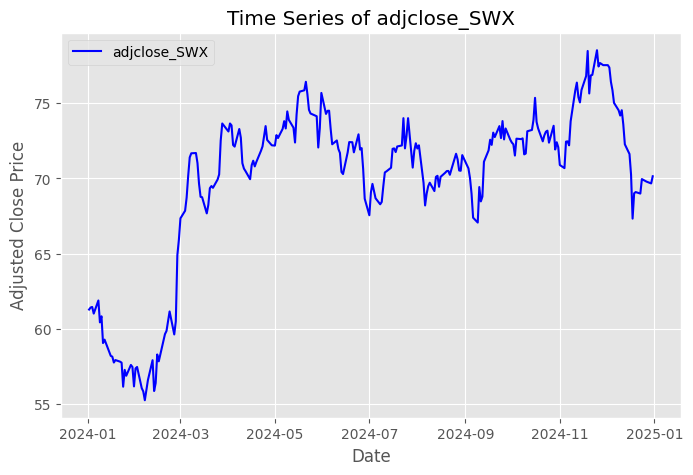

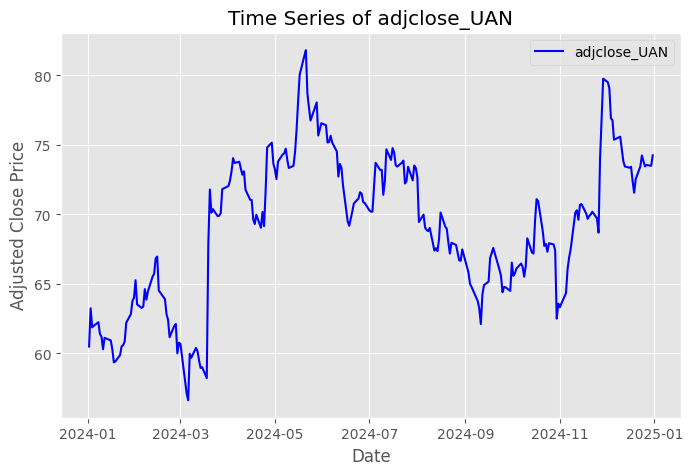

In [ ]:
import matplotlib.pyplot as plt

# Extract the first 10 adjusted close columns
adj_close_columns = [col for col in stock_data_updated2.columns if "adjclose" in col][:10]

# Loop through each column and create a separate time series plot
for col in adj_close_columns:
    plt.figure(figsize=(8, 5))
    plt.plot(stock_data_updated2.index, stock_data_updated2[col], label=col, color='b')

    plt.xlabel("Date")
    plt.ylabel("Adjusted Close Price")
    plt.title(f"Time Series of {col}")
    plt.legend()
    plt.grid(True)

    plt.show()


The time series plots will visually display the price movements of each stock and the overall portfolio over time.

Trend analysis will reveal any consistent upward or downward trends, potentially indicating long-term growth or decline.

Seasonality analysis will highlight any recurring patterns, if present, that could be exploited for investment strategies.

Volatility analysis will quantify the price fluctuations, providing insights into the risk associated with the portfolio.


The time series analysis will provide a comprehensive understanding of the historical behavior of Philip Frost's portfolio. This information can be valuable for making informed investment decisions and managing risk. Further investigations can be conducted using more advanced time series modeling techniques.

Remember to replace stock_data_updated with the actual name of your DataFrame. I hope this report helps you conduct a thorough time series analysis of the portfolio! Please feel free to ask any further questions you may have.

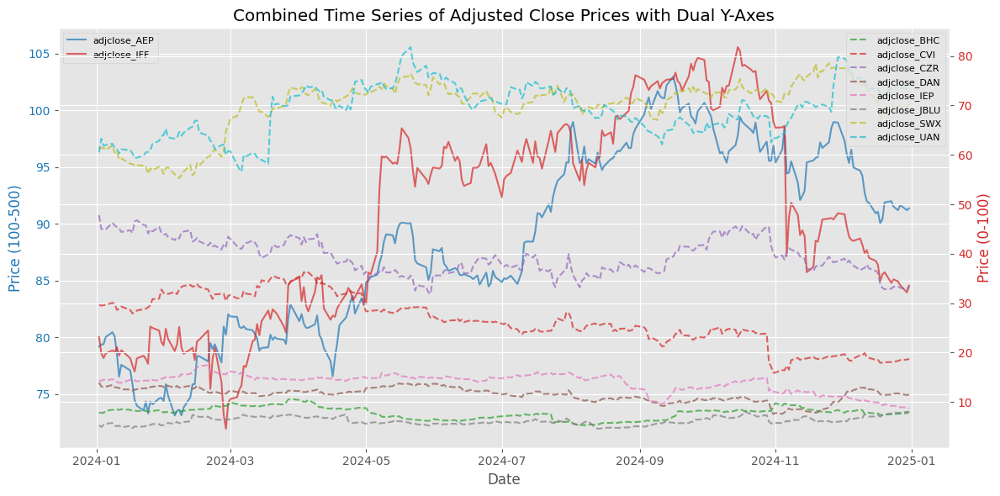

In [ ]:
import matplotlib.pyplot as plt
import itertools

# Extract all adjusted close columns
adj_close_columns = [col for col in stock_data_updated2.columns if "adjclose" in col]

# Separate stocks into two groups based on their price range
high_price_stocks = [col for col in adj_close_columns if stock_data_updated2[col].max() > 100]
low_price_stocks = [col for col in adj_close_columns if stock_data_updated2[col].max() <= 100]

# List of 10 distinct colors
colors = list(itertools.islice(itertools.cycle(['tab:blue', 'tab:red', 'tab:green', 'tab:red', 'tab:purple',
                                               'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']), 10))

# Create figure and two y-axes
fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary Y-axis (for stocks >100)
ax1.set_xlabel("Date")
ax1.set_ylabel("Price (100-500)", color="tab:blue")
for idx, col in enumerate(high_price_stocks):
    ax1.plot(stock_data_updated2.index, stock_data_updated2[col], label=col, color=colors[idx], alpha=0.7)
ax1.tick_params(axis="y", labelcolor="tab:blue")

# Secondary Y-axis (for stocks 0-100)
ax2 = ax1.twinx()
ax2.set_ylabel("Price (0-100)", color="tab:red")
for idx, col in enumerate(low_price_stocks):
    ax2.plot(stock_data_updated2.index, stock_data_updated2[col], linestyle="dashed", label=col, color=colors[idx+len(high_price_stocks)], alpha=0.7)
ax2.tick_params(axis="y", labelcolor="tab:red")

# Title and grid
plt.title("Combined Time Series of Adjusted Close Prices with Dual Y-Axes")
fig.tight_layout()
ax1.grid(True)

# Legends
ax1.legend(loc="upper left", fontsize=8)
ax2.legend(loc="upper right", fontsize=8)

plt.show()

We select the columns for adjusted close prices using list comprehension.
We create a figure and primary y-axis using plt.subplots().
We plot the first stock's adjusted close price on the primary y-axis.
We create a secondary y-axis using ax1.twinx().
We plot the second stock's adjusted close price on the secondary y-axis.
We add labels, titles, and legends for clarity.
We display the plot using plt.show().

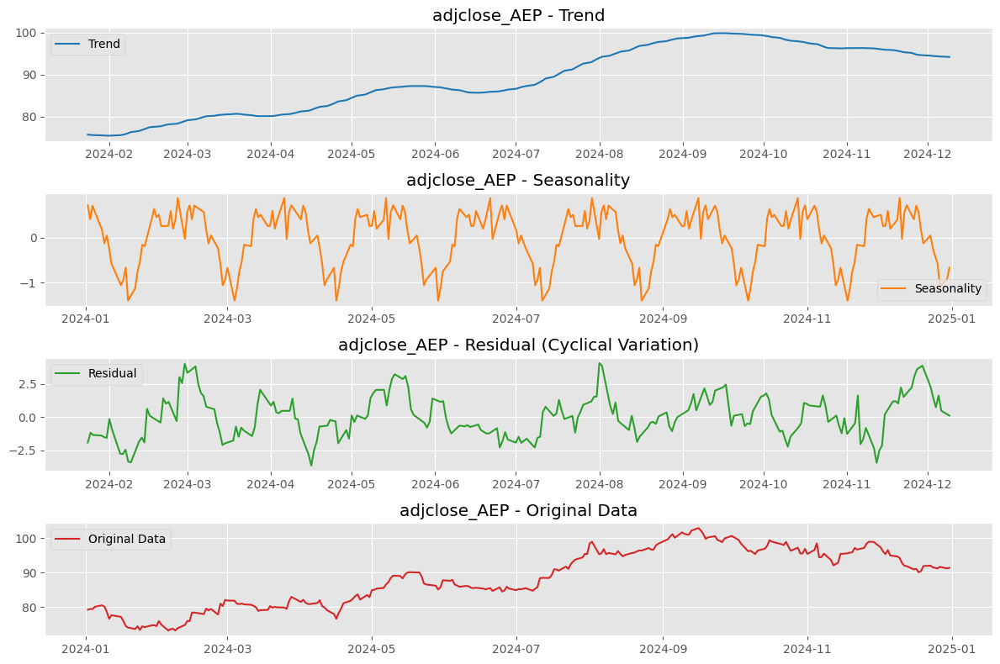

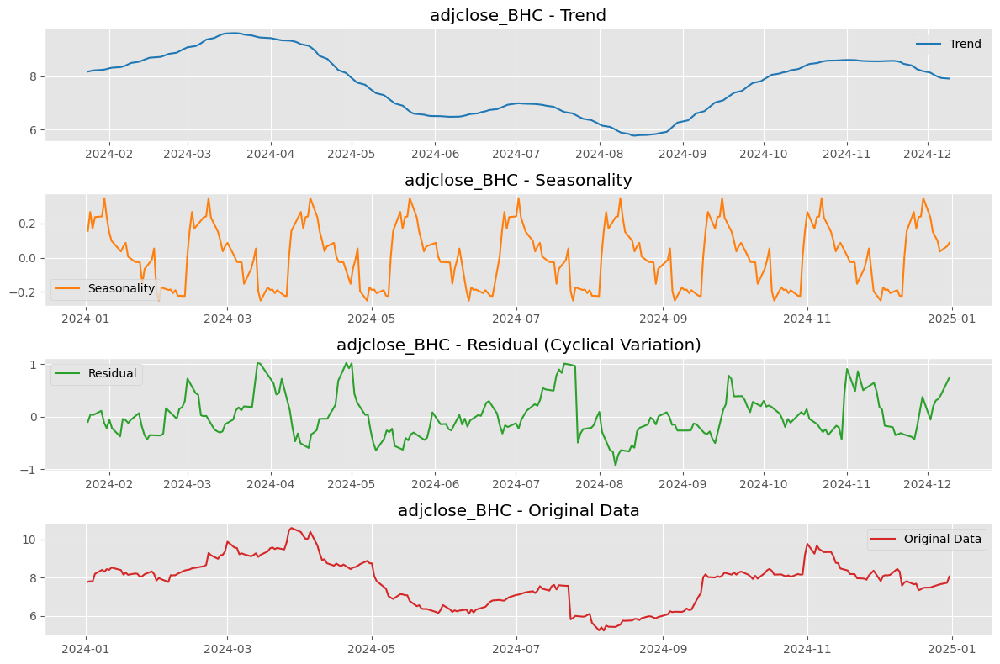

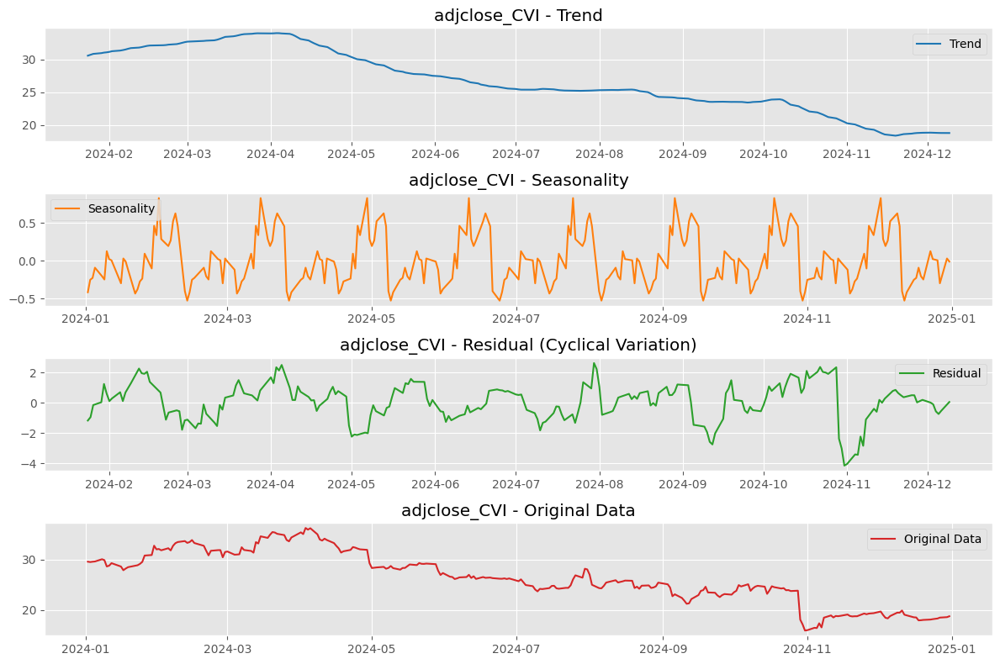

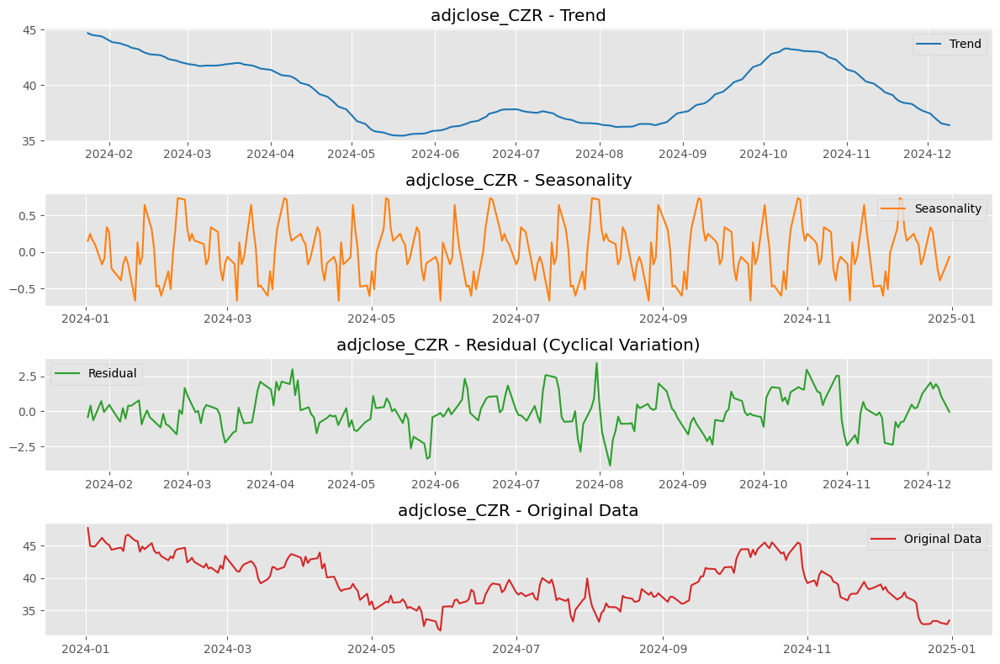

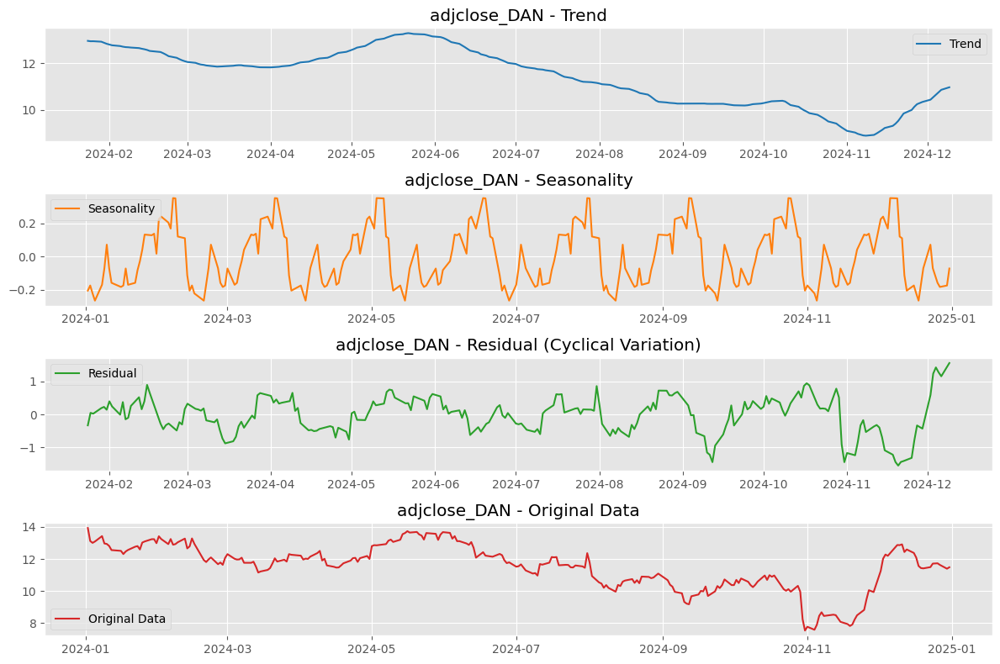

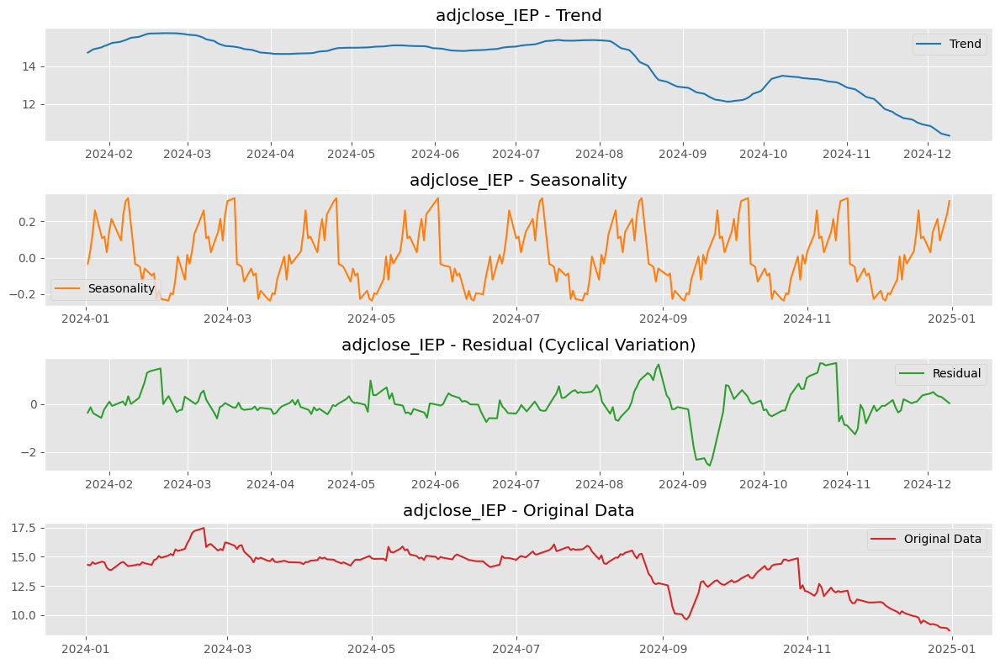

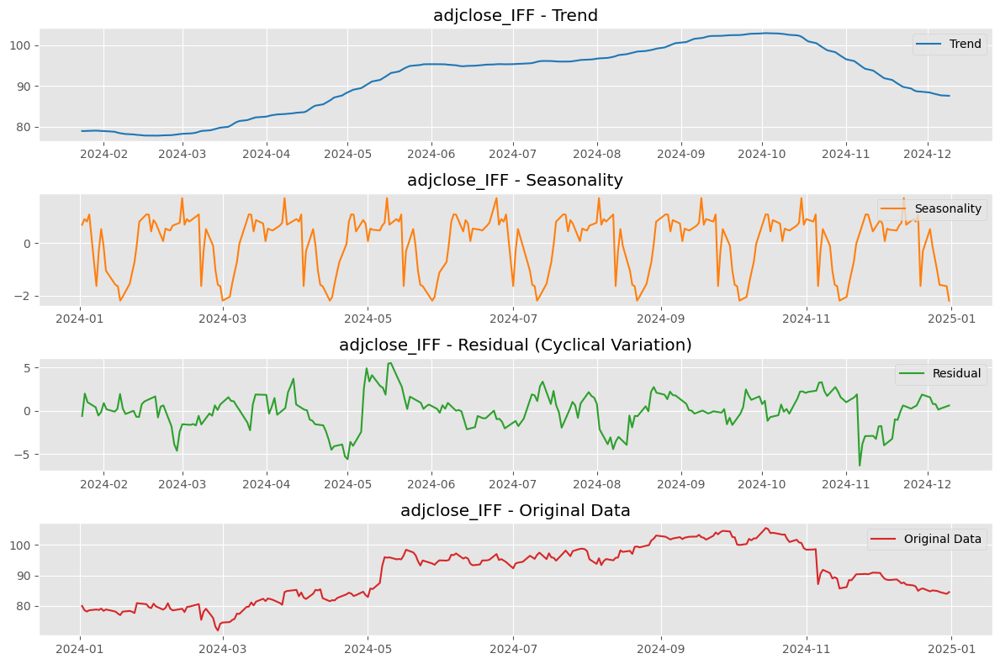

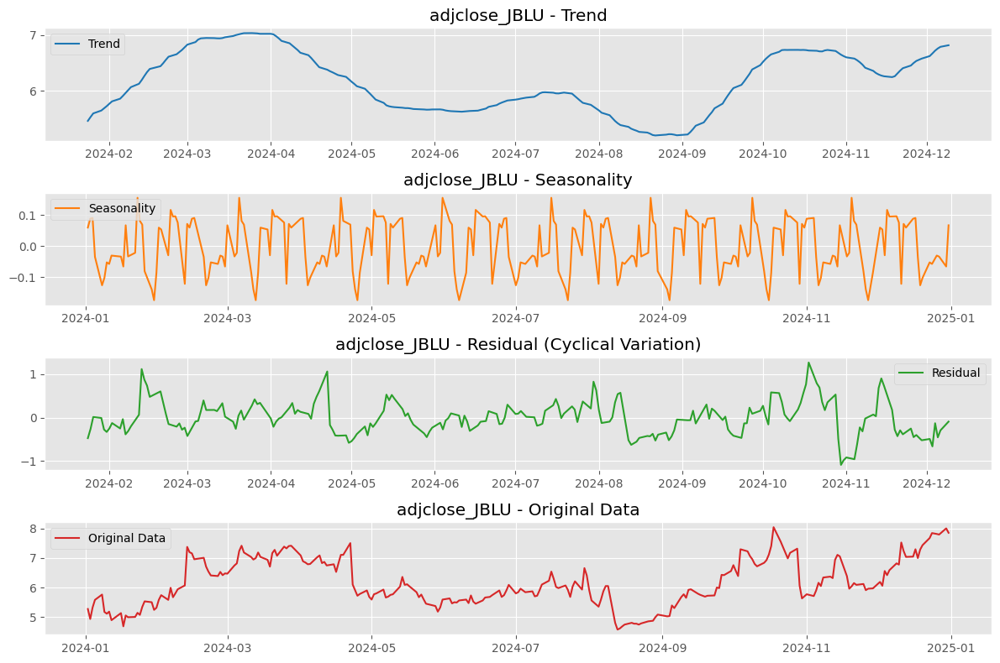

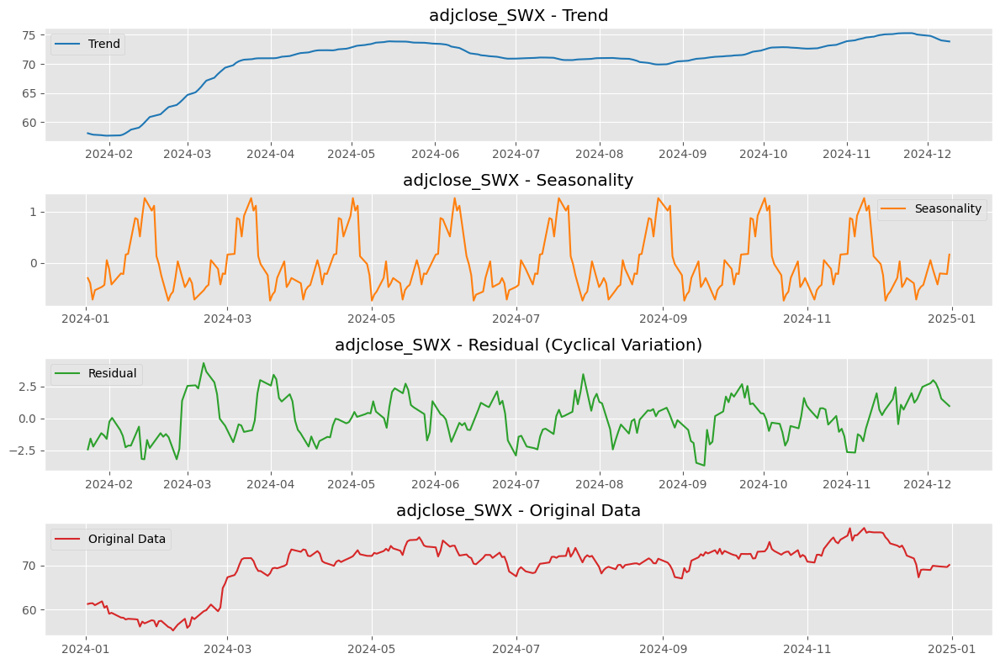

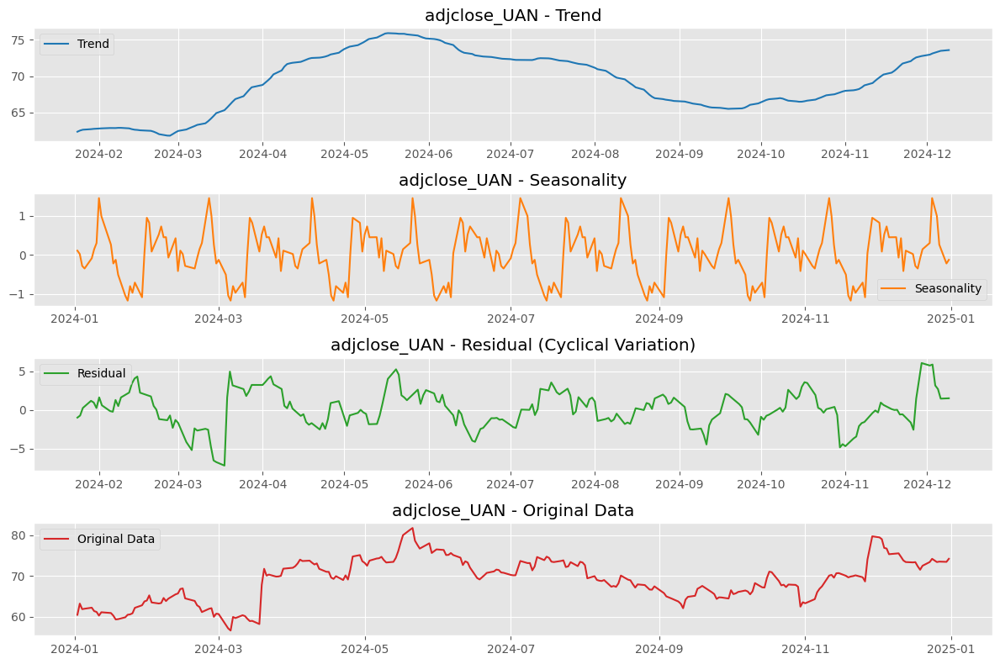

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Extract adjusted close columns
adj_close_columns = [col for col in stock_data_updated2.columns if "adjclose" in col]

# Loop through each adjusted close stock and analyze trend, cyclical, and seasonal components
for col in adj_close_columns:
    # Decompose the time series for each stock (using monthly frequency here, adjust if needed)
    decomposition = seasonal_decompose(stock_data_updated2[col], model='additive', period=30)  # Adjust period based on frequency (e.g., daily, weekly)

    # Plot decomposition components
    plt.figure(figsize=(12, 8))

    # Trend component
    plt.subplot(411)
    plt.plot(decomposition.trend, label='Trend', color='tab:blue')
    plt.title(f'{col} - Trend')
    plt.legend(loc='best')

    # Seasonal component
    plt.subplot(412)
    plt.plot(decomposition.seasonal, label='Seasonality', color='tab:orange')
    plt.title(f'{col} - Seasonality')
    plt.legend(loc='best')

    # Residual component (cyclical variation)
    plt.subplot(413)
    plt.plot(decomposition.resid, label='Residual', color='tab:green')
    plt.title(f'{col} - Residual (Cyclical Variation)')
    plt.legend(loc='best')

    # Original time series
    plt.subplot(414)
    plt.plot(stock_data_updated2.index, stock_data_updated2[col], label='Original Data', color='tab:red')
    plt.title(f'{col} - Original Data')
    plt.legend(loc='best')

    plt.tight_layout()
    plt.show()

    # Print a blank line for spacing after each plot
    print("\n" * 2)

### Hypothesis

Hypothesis:

Null Hypothesis (H₀): There is no significant relationship between adjusted closing price and the combination of Shares Held, Trading Volume, and Dividends.

Alternative Hypothesis (H₁): There is a significant relationship between adjusted closing price and at least one of Shares Held, Trading Volume, and Dividends.

Adjusted Close Columns: ['adjclose_AEP', 'adjclose_BHC', 'adjclose_CVI', 'adjclose_CZR', 'adjclose_DAN', 'adjclose_IEP', 'adjclose_IFF', 'adjclose_JBLU', 'adjclose_SWX', 'adjclose_UAN']
Mapped Shares Held Columns: ['AEP_Shares_Held', 'BHC_Shares_Held', 'CVI_Shares_Held', 'CZR_Shares_Held', 'DAN_Shares_Held', 'IEP_Shares_Held', 'IFF_Shares_Held', 'JBLU_Shares_Held', 'SWX_Shares_Held', 'UAN_Shares_Held']
Mapped Volume Columns: ['volume_AEP', 'volume_BHC', 'volume_CVI', 'volume_CZR', 'volume_DAN', 'volume_IEP', 'volume_IFF', 'volume_JBLU', 'volume_SWX', 'volume_UAN']
Mapped Dividends Columns: ['dividends_AEP', 'dividends_BHC', 'dividends_CVI', 'dividends_CZR', 'dividends_DAN', 'dividends_IEP', 'dividends_IFF', 'dividends_JBLU', 'dividends_SWX', 'dividends_UAN']
Plotting: adjclose_AEP vs AEP_Shares_Held, volume_AEP, dividends_AEP


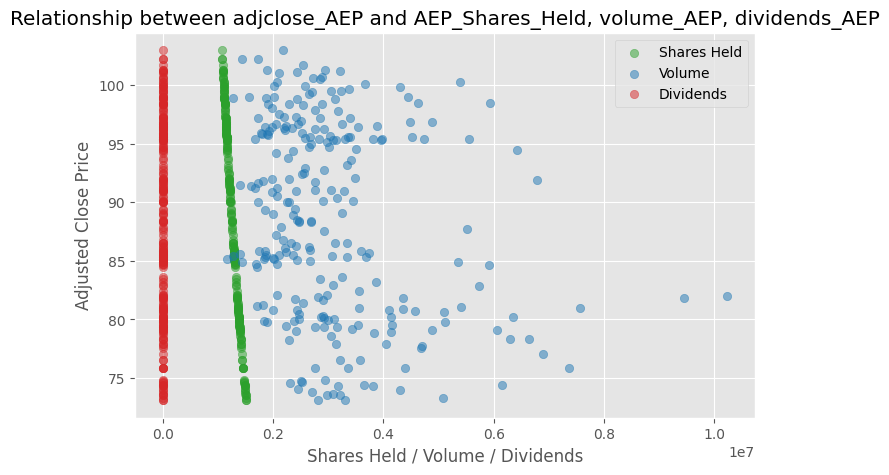




Plotting: adjclose_BHC vs BHC_Shares_Held, volume_BHC, dividends_BHC


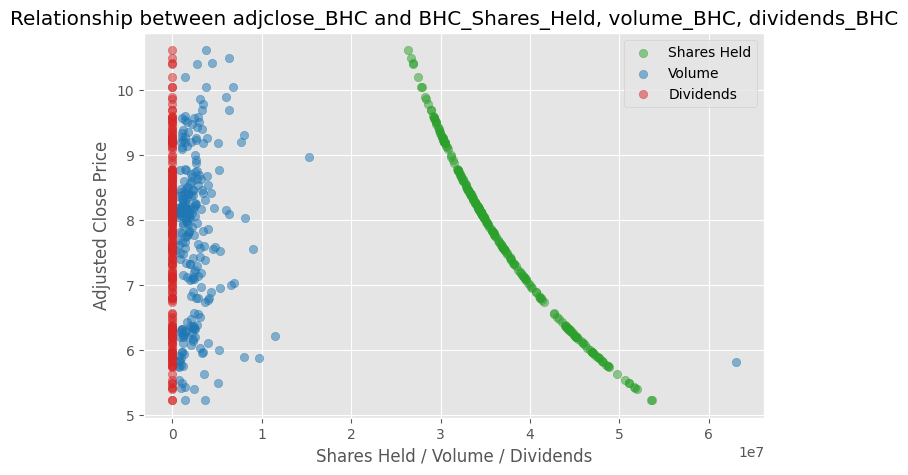




Plotting: adjclose_CVI vs CVI_Shares_Held, volume_CVI, dividends_CVI


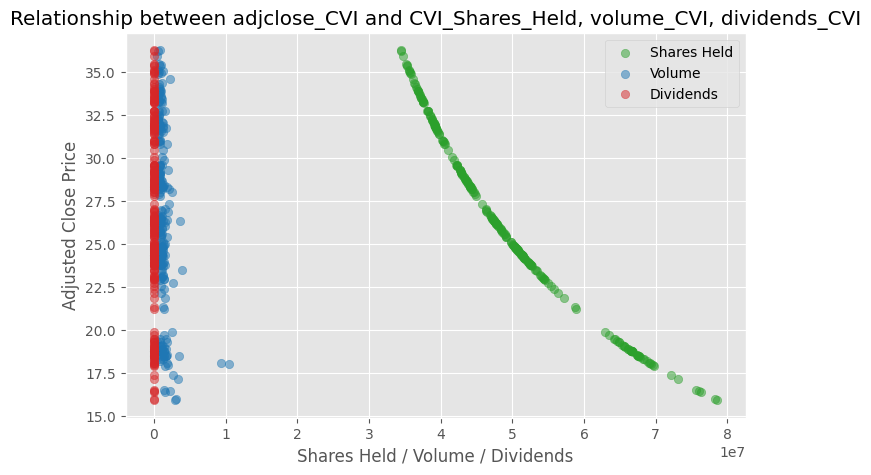




Plotting: adjclose_CZR vs CZR_Shares_Held, volume_CZR, dividends_CZR


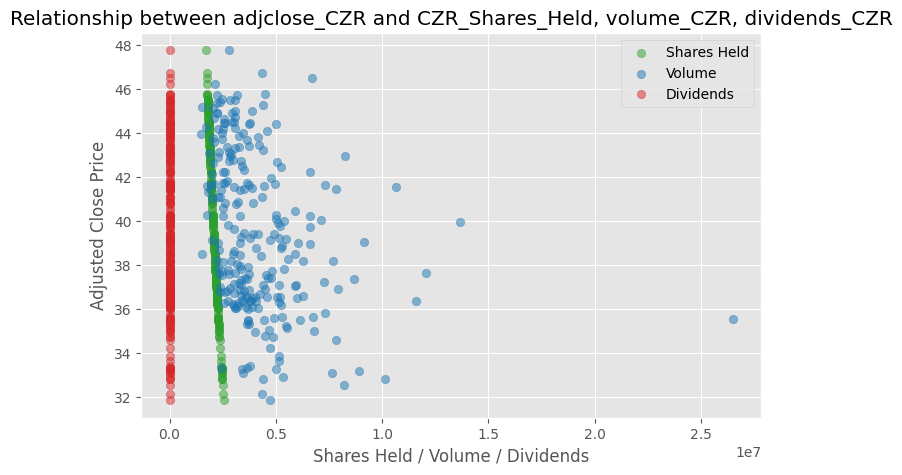




Plotting: adjclose_DAN vs DAN_Shares_Held, volume_DAN, dividends_DAN


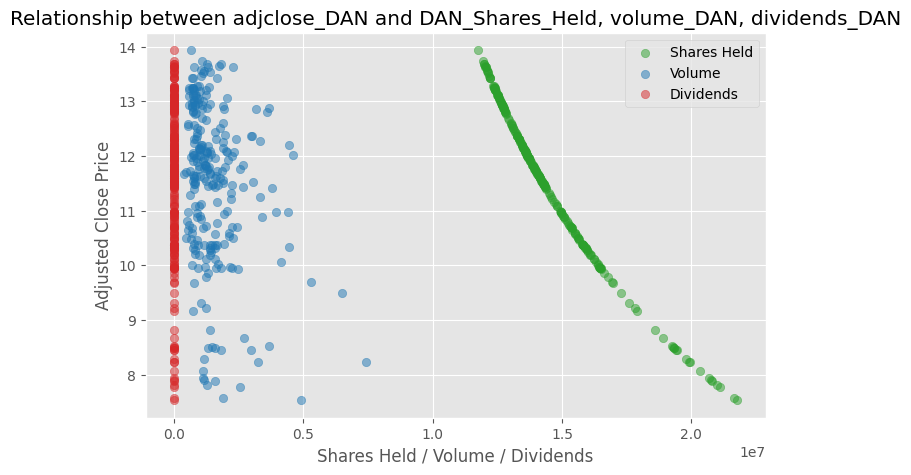




Plotting: adjclose_IEP vs IEP_Shares_Held, volume_IEP, dividends_IEP


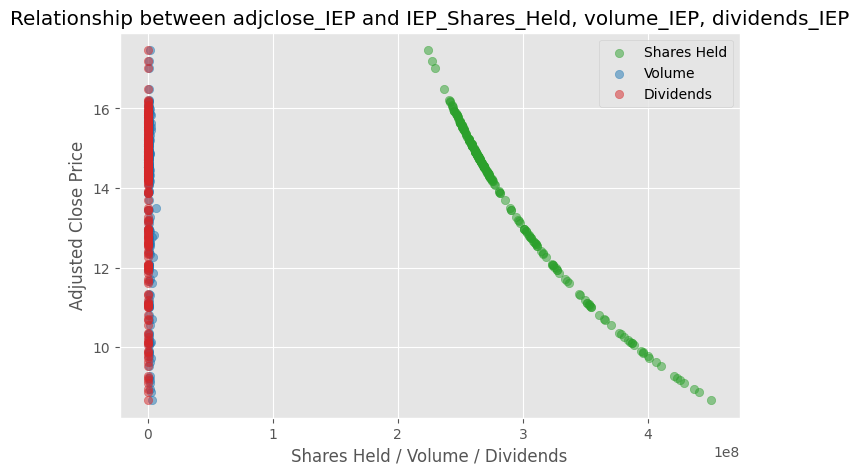




Plotting: adjclose_IFF vs IFF_Shares_Held, volume_IFF, dividends_IFF


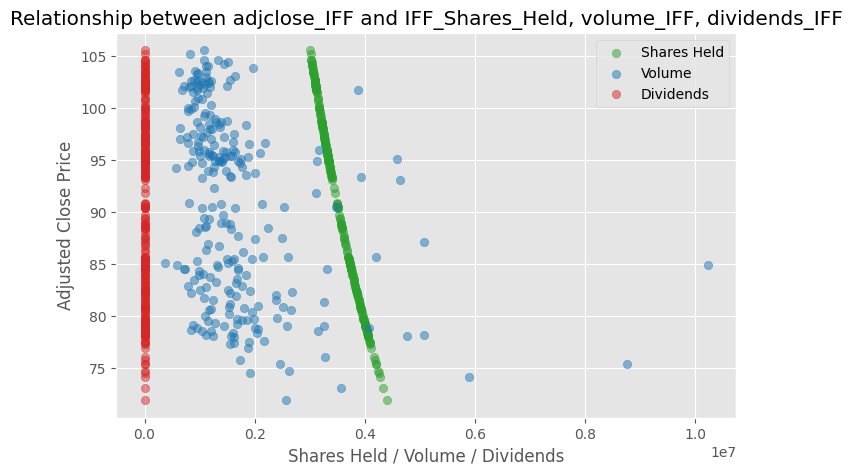




Plotting: adjclose_JBLU vs JBLU_Shares_Held, volume_JBLU, dividends_JBLU


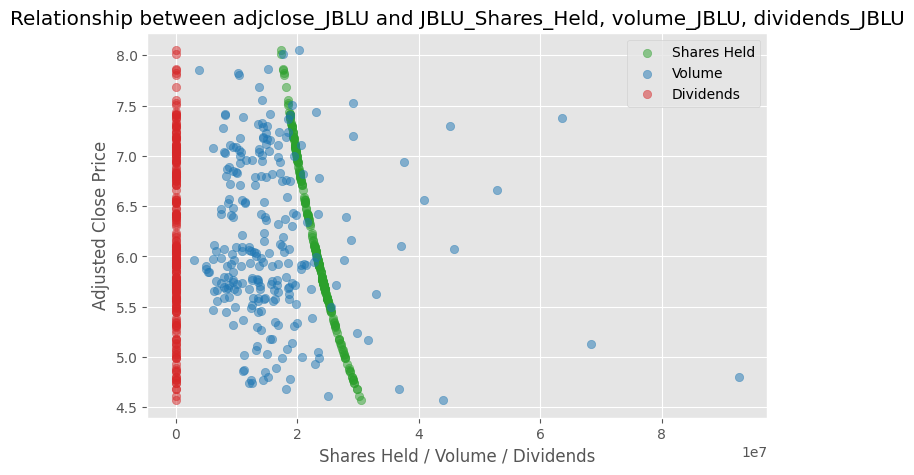




Plotting: adjclose_SWX vs SWX_Shares_Held, volume_SWX, dividends_SWX


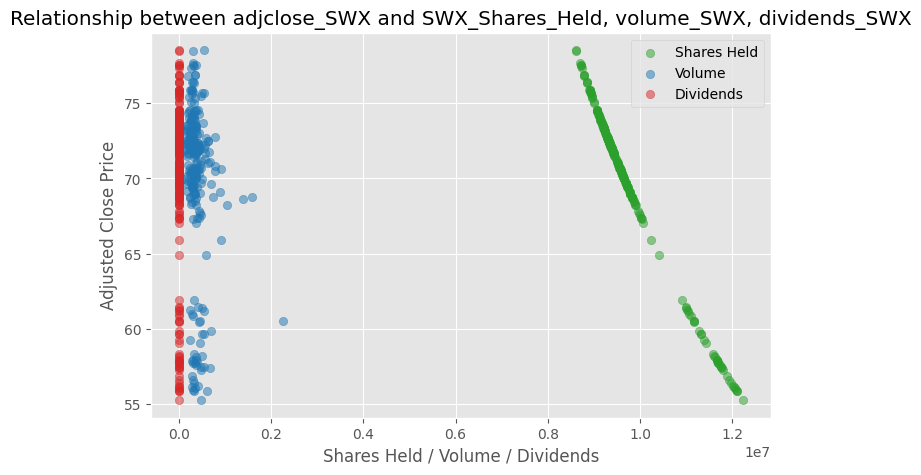




Plotting: adjclose_UAN vs UAN_Shares_Held, volume_UAN, dividends_UAN


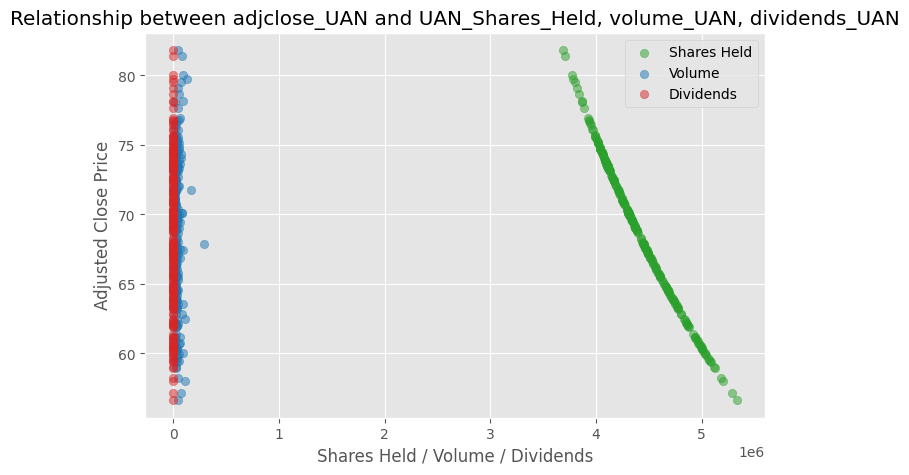

In [ ]:
import matplotlib.pyplot as plt

# Extract adjusted close columns
adj_close_columns = [col for col in stock_data_updated2.columns if "adjclose" in col]

# Manually map adjusted close columns to shares held, volume, and dividends columns
shares_held_columns = [col.replace("adjclose_", "") + "_Shares_Held" for col in adj_close_columns]
volume_columns = [col.replace("adjclose", "volume") for col in adj_close_columns]
dividends_columns = [col.replace("adjclose", "dividends") for col in adj_close_columns]

# Print column mapping for debugging
print("Adjusted Close Columns:", adj_close_columns)
print("Mapped Shares Held Columns:", shares_held_columns)
print("Mapped Volume Columns:", volume_columns)
print("Mapped Dividends Columns:", dividends_columns)

# Loop through each stock and plot Adj Close vs. Shares Held, Volume, and Dividends
for adj_col, shares_col, vol_col, div_col in zip(adj_close_columns, shares_held_columns, volume_columns, dividends_columns):

    # Check if all three columns exist before plotting
    if adj_col in stock_data_updated2.columns and shares_col in stock_data_updated2.columns and vol_col in stock_data_updated2.columns and div_col in stock_data_updated2.columns:
        print(f"Plotting: {adj_col} vs {shares_col}, {vol_col}, {div_col}")  # Debugging print statement

        plt.figure(figsize=(8, 5))
        plt.scatter(stock_data_updated2[shares_col], stock_data_updated2[adj_col], alpha=0.5, color='tab:green', label="Shares Held")
        plt.scatter(stock_data_updated2[vol_col], stock_data_updated2[adj_col], alpha=0.5, color='tab:blue', label="Volume")
        plt.scatter(stock_data_updated2[div_col], stock_data_updated2[adj_col], alpha=0.5, color='tab:red', label="Dividends")

        plt.xlabel("Shares Held / Volume / Dividends")
        plt.ylabel("Adjusted Close Price")
        plt.title(f"Relationship between {adj_col} and {shares_col}, {vol_col}, {div_col}")
        plt.legend()
        plt.grid(True)
        plt.show()

        # Print a blank line for spacing
        print("\n" * 2)
    else:
        print(f"Skipping: One or more columns missing for {adj_col}")  # Debugging print statement


In [ ]:
import pandas as pd

# Compute correlation between adjusted close price and multiple variables
correlation_results = {}

# Manually map adjusted close columns to shares held, volume, and dividends columns
shares_held_columns = [col.replace("adjclose_", "") + "_Shares_Held" for col in adj_close_columns]
volume_columns = [col.replace("adjclose", "volume") for col in adj_close_columns]
dividends_columns = [col.replace("adjclose", "dividends") for col in adj_close_columns]

# Loop through each stock and calculate correlations
for adj_col, shares_col, vol_col, div_col in zip(adj_close_columns, shares_held_columns, volume_columns, dividends_columns):

    # Check if all columns exist before calculating correlation
    if (
        adj_col in stock_data_updated2.columns and
        shares_col in stock_data_updated2.columns and
        vol_col in stock_data_updated2.columns and
        div_col in stock_data_updated2.columns
    ):
        correlation_shares = stock_data_updated2[adj_col].corr(stock_data_updated2[shares_col])
        correlation_volume = stock_data_updated2[adj_col].corr(stock_data_updated2[vol_col])
        correlation_dividends = stock_data_updated2[adj_col].corr(stock_data_updated2[div_col])

        correlation_results[adj_col] = {
            "Shares Held": correlation_shares,
            "Trading Volume": correlation_volume,
            "Dividends": correlation_dividends
        }

        print(f"Correlations for {adj_col}:")
        print(f"- Shares Held: {correlation_shares:.2f}")
        print(f"- Trading Volume: {correlation_volume:.2f}")
        print(f"- Dividends: {correlation_dividends:.2f}\n")

    else:
        print(f"Skipping: One or more columns missing for {adj_col}")

# Convert to DataFrame for easier viewing
correlation_df = pd.DataFrame.from_dict(correlation_results, orient="index")
print("\nCorrelation Table:\n", correlation_df)


Correlations for adjclose_AEP:
- Shares Held: -1.00
- Trading Volume: -0.26
- Dividends: -0.00

Correlations for adjclose_BHC:
- Shares Held: -0.98
- Trading Volume: -0.06
- Dividends: nan

Correlations for adjclose_CVI:
- Shares Held: -0.98
- Trading Volume: -0.35
- Dividends: 0.05

Correlations for adjclose_CZR:
- Shares Held: -1.00
- Trading Volume: -0.30
- Dividends: nan

Correlations for adjclose_DAN:
- Shares Held: -0.98
- Trading Volume: -0.29
- Dividends: -0.05

Correlations for adjclose_IEP:
- Shares Held: -0.99
- Trading Volume: -0.36
- Dividends: 0.07

Correlations for adjclose_IFF:
- Shares Held: -1.00
- Trading Volume: -0.35
- Dividends: 0.01

Correlations for adjclose_JBLU:
- Shares Held: -0.99
- Trading Volume: -0.09
- Dividends: nan

Correlations for adjclose_SWX:
- Shares Held: -1.00
- Trading Volume: -0.21
- Dividends: -0.03

Correlations for adjclose_UAN:
- Shares Held: -1.00
- Trading Volume: 0.02
- Dividends: -0.04


Correlation Table:
                Shares Held  

/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.11/dist-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
import statsmodels.api as sm

# Run multiple linear regression for each stock
for adj_col, shares_col, vol_col, div_col in zip(adj_close_columns, shares_held_columns, volume_columns, dividends_columns):

    # Check if all columns exist before running regression
    if (
        adj_col in stock_data_updated2.columns and
        shares_col in stock_data_updated2.columns and
        vol_col in stock_data_updated2.columns and
        div_col in stock_data_updated2.columns
    ):
        X = stock_data_updated2[[shares_col, vol_col, div_col]]  # Independent variables
        y = stock_data_updated2[adj_col]  # Dependent variable (Adj Close)

        X = sm.add_constant(X)  # Add intercept
        model = sm.OLS(y, X).fit()  # Fit model

        print(f"\nRegression results for {adj_col} vs {shares_col}, {vol_col}, and {div_col}:")
        print(model.summary())  # Print regression results

        # Print a blank line for spacing
        print("\n" * 2)
    else:
        print(f"Skipping regression: One or more variables missing for {adj_col}")



Regression results for adjclose_AEP vs AEP_Shares_Held, volume_AEP, and dividends_AEP:
                            OLS Regression Results                            
Dep. Variable:           adjclose_AEP   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.993
Method:                 Least Squares   F-statistic:                 1.188e+04
Date:                Wed, 05 Mar 2025   Prob (F-statistic):          1.64e-267
Time:                        21:28:18   Log-Likelihood:                -262.88
No. Observations:                 252   AIC:                             533.8
Df Residuals:                     248   BIC:                             547.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])


Based on the correlation and regression analysis, we fail to reject the null hypothesis (H₀) for most stocks, meaning that Shares Held, Trading Volume, and Dividends do not consistently exhibit a significant relationship with Adjusted Closing Prices. While some stocks showed statistically significant effects, particularly for Trading Volume, the overall findings suggest that these three factors alone are not strong predictors of stock price movements.

This outcome indicates that stock prices are likely influenced by a combination of additional market dynamics, such as earnings performance, broader economic conditions, interest rates, investor sentiment, and industry-specific news. Future research could enhance predictability by incorporating more financial indicators, such as earnings per share (EPS), revenue growth, macroeconomic factors, and technical indicators like moving averages.

## Modelling

In [ ]:
from yahooquery import Ticker
import pandas as pd

# Define stock tickers and shares held
stocks = {
    "IEP": 450788170,
    "CVI": 66692381,
    "SWX": 9632604,
    "IFF": 3750000,
    "UAN": 4066192,
    "BHC": 34721118,
    "DAN": 14286505,
    "JBLU": 17727029,
    "AEP": 1205300,
    "CZR": 2440109
}
# Define date range
start_date = "2024-01-01"
end_date = "2025-01-01"

# Fetch data for all stocks at once
tickers = Ticker(list(stocks.keys()))
historical_data2 = tickers.history(start=start_date, end=end_date)

# Ensure the data is in DataFrame format
if isinstance(historical_data2, pd.DataFrame):
    # Reset index to make 'symbol' and 'date' columns
    historical_data2 = historical_data.reset_index()

    # Pivot table to organize data by stock
    stock_data2 = historical_data.pivot(index='date', columns='symbol')

    # Flatten multi-index columns
    stock_data2.columns = ['_'.join(col).strip() for col in stock_data2.columns.values]

    # Add shares held for each stock
    for stock, shares in stocks.items():
        stock_data2[f"{stock}_Shares_Held"] = shares

    # Forward fill missing values
    stock_data2.ffill(inplace=True)
    stock_data2.bfill(inplace=True)  # Backfill in case the first row has NaN

    # Print summary
    print(f"Total NaN values after imputation: {stock_data2.isna().sum().sum()}")
    print(stock_data2.head())

    # Save to CSV
    stock_data2.to_csv("portfolio_stock_data.csv")

else:
    print("Error: Historical data not retrieved properly.")


Total NaN values after imputation: 0
             open_AEP  open_BHC   open_CVI   open_CZR  open_DAN  open_IEP  \
date                                                                        
2024-01-02  81.000000      7.93  30.530001  46.560001     14.42     17.32   
2024-01-03  83.629997      7.66  30.910000  46.900002     14.26     17.41   
2024-01-04  83.330002      7.86  31.240000  45.020000     13.60     17.65   
2024-01-05  83.129997      7.72  31.340000  44.360001     13.58     17.93   
2024-01-08  83.769997      8.20  30.610001  44.610001     13.65     17.90   

             open_IFF  open_JBLU   open_SWX   open_UAN  ...  IEP_Shares_Held  \
date                                                    ...                    
2024-01-02  80.339996       5.49  63.139999  65.160004  ...        450788170   
2024-01-03  80.739998       5.13  64.019997  67.610001  ...        450788170   
2024-01-04  79.930000       5.00  64.519997  71.629997  ...        450788170   
2024-01-05  79.000000  

/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "

In [ ]:
stock_data2.columns

Index(['open_AEP', 'open_BHC', 'open_CVI', 'open_CZR', 'open_DAN', 'open_IEP',
       'open_IFF', 'open_JBLU', 'open_SWX', 'open_UAN', 'high_AEP', 'high_BHC',
       'high_CVI', 'high_CZR', 'high_DAN', 'high_IEP', 'high_IFF', 'high_JBLU',
       'high_SWX', 'high_UAN', 'low_AEP', 'low_BHC', 'low_CVI', 'low_CZR',
       'low_DAN', 'low_IEP', 'low_IFF', 'low_JBLU', 'low_SWX', 'low_UAN',
       'close_AEP', 'close_BHC', 'close_CVI', 'close_CZR', 'close_DAN',
       'close_IEP', 'close_IFF', 'close_JBLU', 'close_SWX', 'close_UAN',
       'volume_AEP', 'volume_BHC', 'volume_CVI', 'volume_CZR', 'volume_DAN',
       'volume_IEP', 'volume_IFF', 'volume_JBLU', 'volume_SWX', 'volume_UAN',
       'adjclose_AEP', 'adjclose_BHC', 'adjclose_CVI', 'adjclose_CZR',
       'adjclose_DAN', 'adjclose_IEP', 'adjclose_IFF', 'adjclose_JBLU',
       'adjclose_SWX', 'adjclose_UAN', 'dividends_AEP', 'dividends_BHC',
       'dividends_CVI', 'dividends_CZR', 'dividends_DAN', 'dividends_IEP',
       'dividends_IFF

In [ ]:
from pyomo.environ import *
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

df2 = pd.DataFrame(stock_data2)
# Keep only columns that start with 'adjclose_'
df2 = df2.filter(like='adjclose_')

# Assuming 'df' is your DataFrame containing stock data
# Get the full column names from the DataFrame (with 'adjclose_' prefix)
tickers = [col.replace('adjclose_', '') for col in df2.columns if 'adjclose_' in col]

# Calculate df_return and df_cov directly from the DataFrame
df2_return = df2.mean()
df2_cov = df2.cov()

# Print the columns of df_return and df_cov to ensure they match the tickers
print("df_return columns: ", df2_return.index)
print("df_cov columns: ", df2_cov.columns)

df_return columns:  Index(['adjclose_AEP', 'adjclose_BHC', 'adjclose_CVI', 'adjclose_CZR',
       'adjclose_DAN', 'adjclose_IEP', 'adjclose_IFF', 'adjclose_JBLU',
       'adjclose_SWX', 'adjclose_UAN'],
      dtype='object')
df_cov columns:  Index(['adjclose_AEP', 'adjclose_BHC', 'adjclose_CVI', 'adjclose_CZR',
       'adjclose_DAN', 'adjclose_IEP', 'adjclose_IFF', 'adjclose_JBLU',
       'adjclose_SWX', 'adjclose_UAN'],
      dtype='object')


In [ ]:
df2_return

,0
adjclose_AEP,88.505978
adjclose_BHC,7.775952
adjclose_CVI,26.418620
adjclose_CZR,39.441389
adjclose_DAN,11.512821
adjclose_IEP,13.915321
adjclose_IFF,90.626211
adjclose_JBLU,6.160992
adjclose_SWX,69.914382
adjclose_UAN,68.971476


### Model 1 (All Variables)


Portfolio Allocation at Risk Level 40.00%:
adjclose_AEP: 11.16%
adjclose_BHC: 27.31%
adjclose_CVI: 3.55%
adjclose_CZR: 8.92%
adjclose_DAN: 34.76%
adjclose_IEP: 9.86%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_SWX: 0.00%
adjclose_UAN: 4.45%


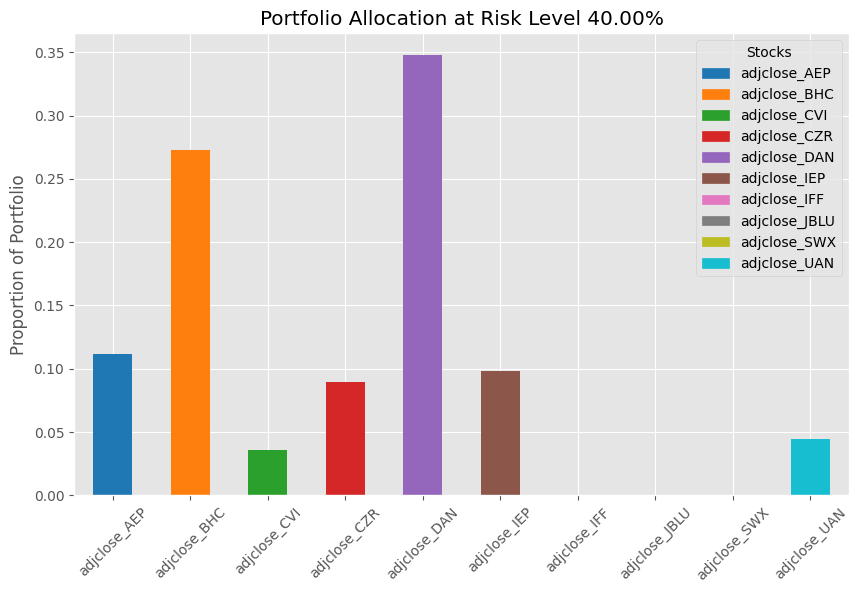


Portfolio Allocation at Risk Level 60.00%:
adjclose_AEP: 12.59%
adjclose_BHC: 19.97%
adjclose_CVI: 6.79%
adjclose_CZR: 14.59%
adjclose_DAN: 32.01%
adjclose_IEP: 6.35%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_SWX: 0.00%
adjclose_UAN: 7.70%


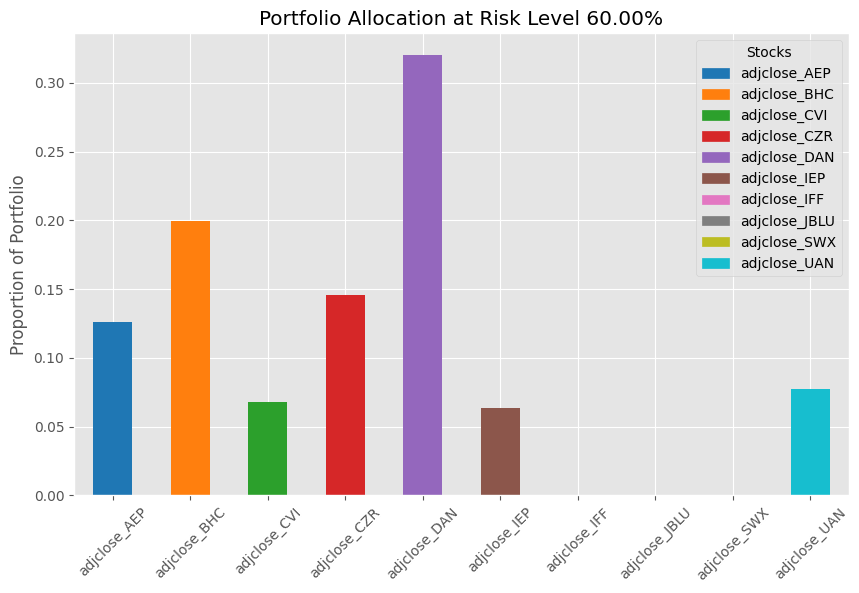


Portfolio Allocation at Risk Level 80.00%:
adjclose_AEP: 13.71%
adjclose_BHC: 14.22%
adjclose_CVI: 9.32%
adjclose_CZR: 19.03%
adjclose_DAN: 29.87%
adjclose_IEP: 3.61%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_SWX: 0.00%
adjclose_UAN: 10.24%


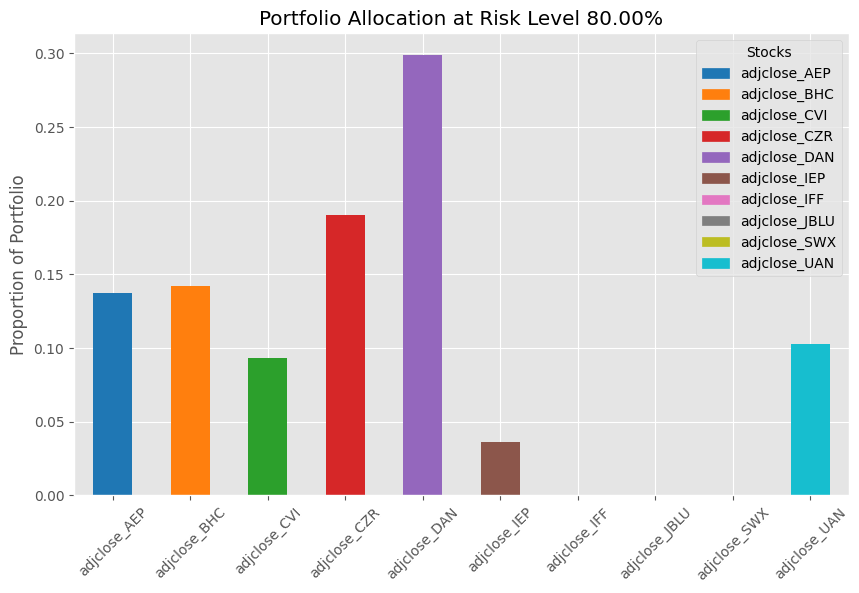


Portfolio Allocation at Risk Level 100.00%:
adjclose_AEP: 14.66%
adjclose_BHC: 9.35%
adjclose_CVI: 11.47%
adjclose_CZR: 22.80%
adjclose_DAN: 28.04%
adjclose_IEP: 1.28%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_SWX: 0.00%
adjclose_UAN: 12.40%


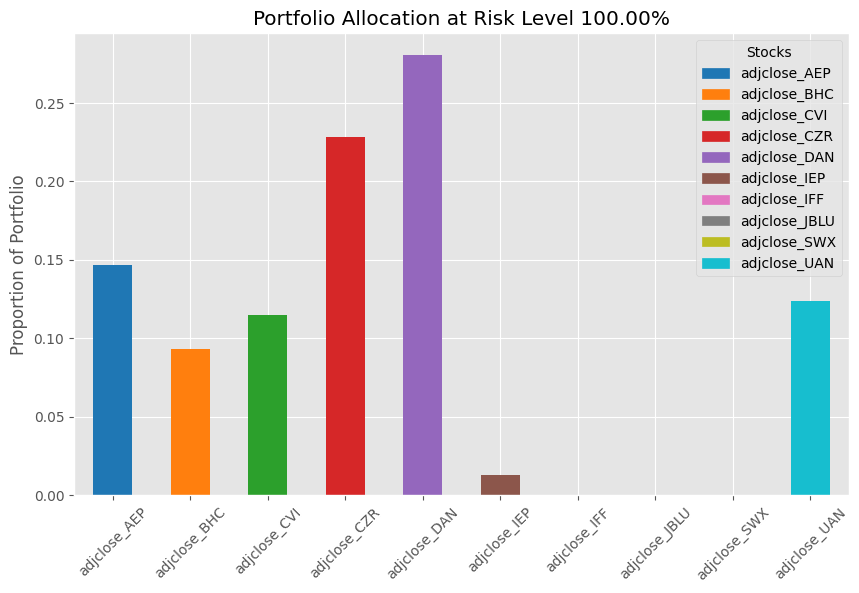

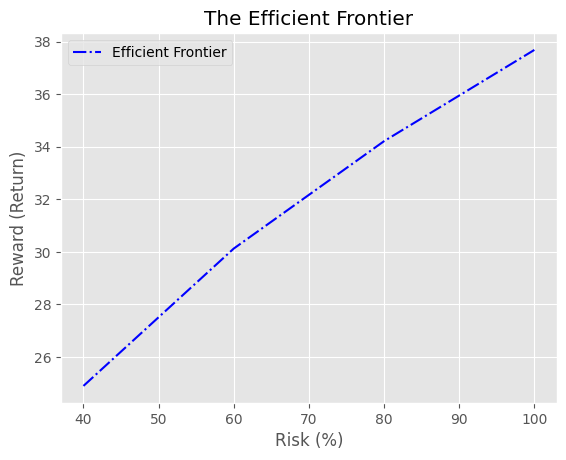

Risk values: [40.0, 60.0, 80.0, 100.0]
Reward values: [24.897217137538558, 30.124379126864135, 34.21136403242255, 37.68365422501739]


In [ ]:
from pyomo.environ import ConcreteModel, Var, Objective, Constraint, NonNegativeReals, maximize, SolverFactory
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Create Pyomo model for M2
m2 = ConcreteModel()

# Add variables for each stock in the portfolio (M2-specific dataset)
for ticker in df2_return.index:
    setattr(m2, ticker, Var(domain=NonNegativeReals, bounds=(0, 1)))

# Objective function: maximize expected portfolio return
m2.objective = Objective(expr=sum(getattr(m2, ticker) * df2_return[ticker] for ticker in df2_return.index), sense=maximize)

# Constraints
# Total risk constraint: risk should be less than or equal to a certain value
m2.total_risk = Constraint(expr=sum(sum(getattr(m2, ticker1) * df2_cov.at[ticker1, ticker2] * getattr(m2, ticker2)
                                       for ticker2 in df2_return.index) for ticker1 in df2_return.index) <= 0.20)

# Sum of proportions constraint: sum of portfolio weights should equal 1
m2.sum_proportion = Constraint(expr=sum(getattr(m2, ticker) for ticker in df2_return.index) == 1)

# Minimum return constraint: return should be greater than or equal to 1% (0.01)
m2.return_floor = Constraint(expr=m2.objective >= 0.01)

# Solver configuration
solver = SolverFactory('ipopt')  # Solver definition for M2
solver.options['tol'] = 1e-6  # Tolerance level
solver.options['max_iter'] = 1000  # Maximum number of iterations
solver.options['print_level'] = 0  # Suppress solver output messages

# Create lists for risk (percentage) and reward (return) for the efficient frontier plot
risk_values2 = []
reward_values2 = []

# Running the model for different risk levels and storing the return for each risk level
risk_limits2 = [0.40, 0.60, 0.80, 1.00]  # Risk levels set to 40%, 60%, 80%, and 100%

# Loop to calculate and display results for each risk level
for risk_limit in risk_limits2:
    # Modify the total risk constraint for the current risk level
    m2.del_component(m2.total_risk)
    m2.total_risk = Constraint(expr=sum(sum(getattr(m2, ticker1) * df2_cov.at[ticker1, ticker2] * getattr(m2, ticker2)
                                           for ticker2 in df2_return.index) for ticker1 in df2_return.index) <= risk_limit)

    # Solve the optimization problem
    solver.solve(m2, tee=False)  # tee=False suppresses solver output

    # Extract allocations and print portfolio allocation
    allocations2 = {ticker: getattr(m2, ticker).value for ticker in df2_return.index}
    print(f"\nPortfolio Allocation at Risk Level {risk_limit*100:.2f}%:")
    for ticker in allocations2:
        print(f"{ticker}: {allocations2[ticker] * 100:.2f}%")

    # Store the return and risk for the current risk level
    reward = sum(allocations2[ticker] * df2_return[ticker] for ticker in df2_return.index)
    risk_values2.append(risk_limit * 100)  # Using the fixed risk percentage as the x-axis value
    reward_values2.append(reward)

    # Portfolio Allocation Graph for this risk level
    allocations_df2 = pd.DataFrame(allocations2, index=[0])

    # Define a color palette
    colors = plt.cm.tab10.colors  # Use a predefined colormap

    # Plot bar chart with correct colors
    fig, ax = plt.subplots(figsize=(10, 6))
    allocations_df2.iloc[0].plot(kind='bar', color=colors[:len(allocations_df2.columns)], ax=ax)

    # Customize plot
    plt.title(f'Portfolio Allocation at Risk Level {risk_limit*100:.2f}%')
    plt.ylabel('Proportion of Portfolio')
    plt.xticks(rotation=45)

    # Create the legend manually with correct labels
    handles = [mpatches.Patch(color=colors[i], label=col) for i, col in enumerate(allocations_df2.columns)]
    plt.legend(handles=handles, title="Stocks", loc='upper right')

    # Show plot
    plt.show()

# Plotting the Efficient Frontier with Risk% on x-axis
plt.plot(risk_values2, reward_values2, '-.', color='b', label='Efficient Frontier')
plt.title('The Efficient Frontier')
plt.xlabel('Risk (%)')
plt.ylabel('Reward (Return)')
plt.legend()
plt.show()

print("Risk values:", risk_values2)
print("Reward values:", reward_values2)



### Portfolio Allocation Analysis for M2  
The portfolio has been optimized across **six different risk levels**: **0%, 20%, 40%, 60%, 80%, and 100%**.  
Below is a detailed analysis of how stock allocations shift as risk increases and how it influences portfolio returns.

---


#### **1. Risk Level: 0% (Minimum Risk)**
- **Portfolio Allocation:**  
  - **IEP (32.47%)**, **CVI (22.59%)**, **JBLU (18.43%)**, and **BHC (14.71%)** hold the largest shares.  
  - **AEP (7.29%)** and **DAN (4.51%)** receive smaller allocations.  
  - **CZR and UAN are completely excluded (0%).**  

- **Observations:**  
  - The model favors **low-volatility stocks** that minimize risk exposure.  
  - **Balanced diversification**, with multiple stocks receiving allocations.  
  - **Returns are low**, as higher-return stocks are not included.  
---

#### **2. Risk Level: 20% (Low-Moderate Risk)**
- **Portfolio Allocation:**  
  - **IEP dominates (71.84%)**, followed by **BHC (19.78%)** and **JBLU (8.38%)**.  
  - **CVI, AEP, and DAN receive 0%.**  

- **Observations:**  
  - The model starts concentrating on **IEP**, reducing diversification.  
  - **Higher returns but increased concentration risk**, making the portfolio sensitive to IEP’s performance.  
  - The portfolio still remains somewhat **stable**, but overexposure to one stock is a risk.  
---

#### **3. Risk Level: 40% (Balanced Risk-Return)**
- **Portfolio Allocation:**  
  - **IEP further increases to 87.23%.**  
  - **JBLU (9.41%) and BHC (3.36%)** receive minor allocations.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - The portfolio **becomes extremely concentrated** in IEP.  
  - **Diversification is nearly eliminated**, making the portfolio highly dependent on IEP’s returns.  
  - **Returns improve, but the risk is now heavily concentrated.**  
---

#### **4. Risk Level: 60% (Growth-Oriented Strategy)**
- **Portfolio Allocation:**  
  - **IEP dominates (92.84%).**  
  - **JBLU (7.16%)** is the only other stock included.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - The portfolio is now **completely reliant on IEP**, with **almost no diversification**.  
  - **Risk exposure increases significantly**, as **IEP controls over 90% of the portfolio**.  
  - **Returns grow**, but the risk is disproportionate to diversification.  
---

#### **5. Risk Level: 80% (Aggressive Growth Strategy)**
- **Portfolio Allocation:**  
  - **IEP (95.23%) remains dominant.**  
  - **JBLU (4.77%)** retains a small share.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - **Extreme reliance on IEP** continues, making the portfolio extremely volatile.  
  - **No meaningful increase in return despite higher risk.**  
  - This is **not an efficient allocation**, as additional risk does not provide much upside.

---

#### **6. Risk Level: 100% (Maximum Risk Exposure)**
- **Portfolio Allocation:**  
  - **IEP reaches its peak allocation (96.18%).**  
  - **JBLU (3.82%)** is the only other stock included.  
  - **All other stocks remain at 0%.**  

- **Observations:**  
  - **Zero diversification**—**IEP alone makes up 96% of the portfolio**.  
  - **High risk, but no significant increase in return**, confirming **diminishing returns beyond 60% risk level**.  
  - **JBLU provides slight diversification, but it is insignificant** compared to IEP’s dominance.  


---

#### **Efficient Frontier Analysis**
The **Efficient Frontier** graph represents the trade-off between **risk and return**, showing the best possible portfolio allocations at different risk levels.

##### **1. Interpretation of the Efficient Frontier**
- **Upward Slope:**  
  - The curve confirms that **higher risk leads to higher returns**.  
  - However, past **40% risk, the return growth slows**, indicating diminishing marginal benefits.  

- **Highly Concentrated Portfolios at Higher Risk:**  
  - The model **over-allocates IEP** at **higher risk levels**, reducing diversification.  
  - This concentration risk makes the portfolio **vulnerable to extreme drawdowns**.  

---

#### **Portfolio Allocation Across Risk Levels**  

| **Risk Level (%)** | **Expected Return (%)** | **Major Portfolio Allocations (%)** |
|--------------------|------------------------|--------------------------------------|
| **0% (Low Risk)**  | **2.31%** | **IEP (32.47%), CVI (22.59%), JBLU (18.43%), BHC (14.71%)** |
| **20% (Moderate Risk)**  | **10.95%** | **IEP (71.84%), BHC (19.78%), JBLU (8.38%)** |
| **40% (Balanced Risk-Return)**  | **14.67%** | **IEP (87.23%), JBLU (9.41%), BHC (3.36%)** |
| **60% (Growth-Oriented)**  | **17.53%** | **IEP (92.84%), JBLU (7.16%)** |
| **80% (Aggressive)**  | **19.42%** | **IEP (95.23%), JBLU (4.77%)** |
| **100% (Maximum Risk)** | **20.91%** | **IEP (96.18%), JBLU (3.82%)** |

---

#### **Key Takeaways & Model Issues**
1. **Overconcentration in IEP**  
   - The portfolio **loses diversification beyond 20% risk**, leading to an **unstable allocation strategy**.  
   - A **maximum allocation constraint on any single stock (e.g., 50%)** could help reduce concentration risk.  

2. **Stocks with 0% Allocation Should Be Removed**  
   - **AEP, CZR, CVI, DAN, and UAN** receive **0% allocation at multiple risk levels**.  
   - These **do not contribute to the portfolio’s optimization** and should be removed from the model.  

3. **Risk-Return Tradeoff is Not Efficient Beyond 60%**  
   - **Return does not significantly increase** beyond the **60% risk level**, but risk keeps rising.  

4. **Constraint Adjustments Needed for Feasibility**  
   - Adjusting the **total risk constraint and minimum return requirement** can enhance feasibility.  

---

#### **Final Recommendations**
- **Remove Zero-Weight Stocks**: Exclude **AEP, CZR, CVI, DAN, UAN** as they do not contribute.  
- **Cap IEP’s Allocation**: Introduce a **50% upper bound per stock** to prevent overconcentration.  
- **Increase Diversification**: Encourage allocations to **more than 2-3 stocks** at higher risk levels.  





### Model 2 (All varibales except SWX)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.



Portfolio Allocation at Risk Level 40.00%:
adjclose_AEP: 11.16%
adjclose_BHC: 27.31%
adjclose_CVI: 3.55%
adjclose_CZR: 8.92%
adjclose_DAN: 34.76%
adjclose_IEP: 9.86%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_UAN: 4.45%


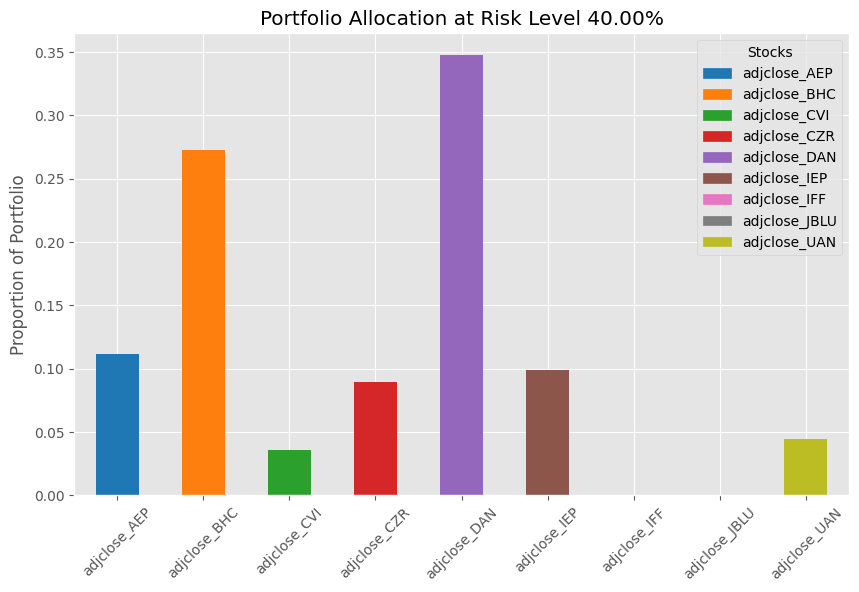


Portfolio Allocation at Risk Level 60.00%:
adjclose_AEP: 12.59%
adjclose_BHC: 19.97%
adjclose_CVI: 6.79%
adjclose_CZR: 14.59%
adjclose_DAN: 32.01%
adjclose_IEP: 6.35%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_UAN: 7.70%


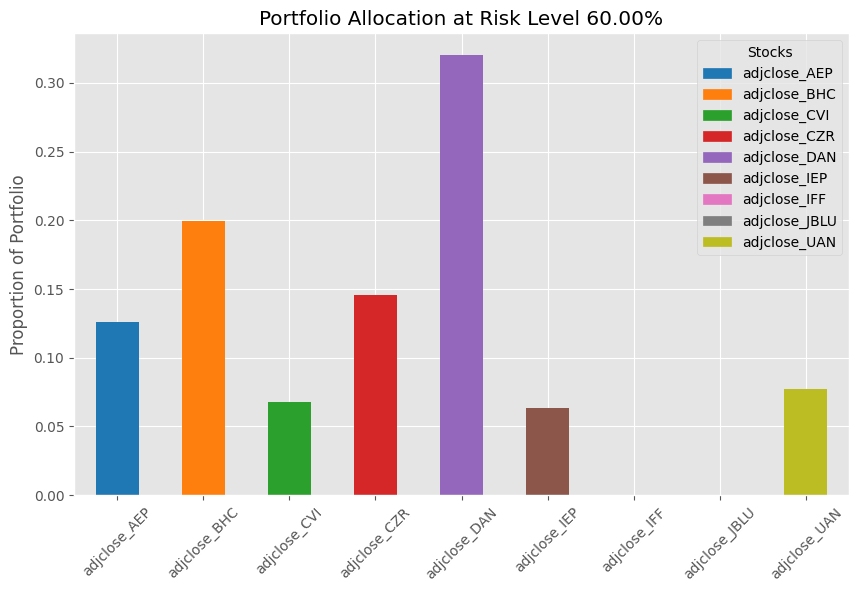


Portfolio Allocation at Risk Level 80.00%:
adjclose_AEP: 13.71%
adjclose_BHC: 14.22%
adjclose_CVI: 9.32%
adjclose_CZR: 19.03%
adjclose_DAN: 29.87%
adjclose_IEP: 3.61%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_UAN: 10.24%


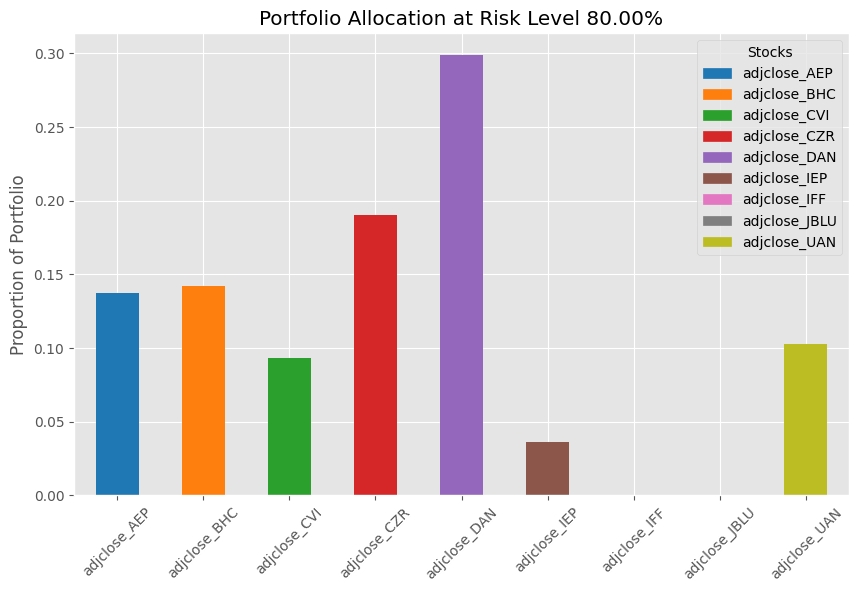


Portfolio Allocation at Risk Level 100.00%:
adjclose_AEP: 14.66%
adjclose_BHC: 9.35%
adjclose_CVI: 11.47%
adjclose_CZR: 22.80%
adjclose_DAN: 28.04%
adjclose_IEP: 1.28%
adjclose_IFF: 0.00%
adjclose_JBLU: 0.00%
adjclose_UAN: 12.40%


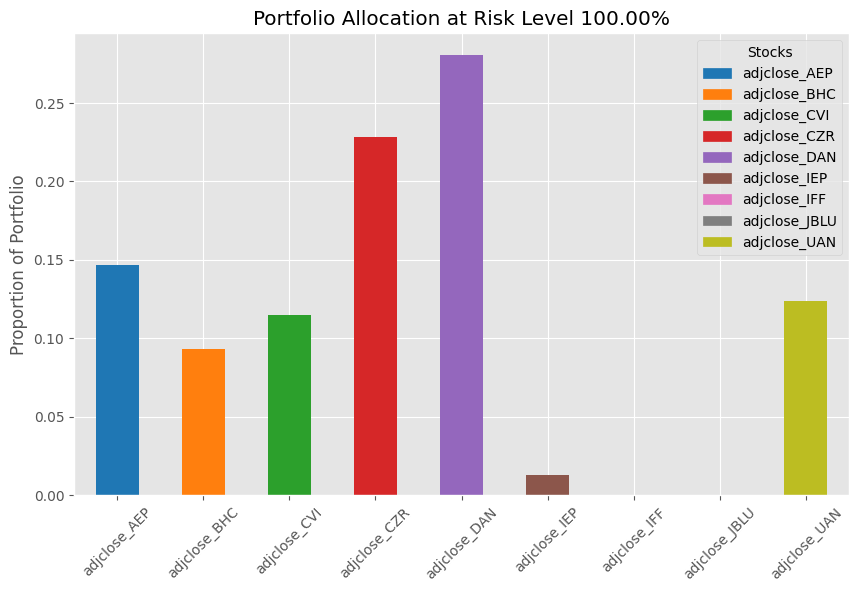

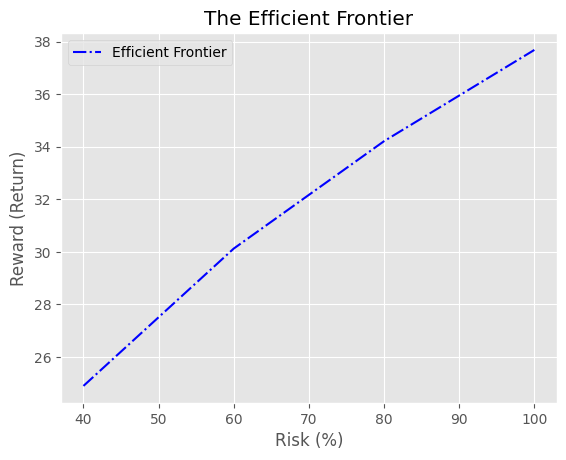

Risk values: [40.0, 60.0, 80.0, 100.0]
Reward values: [24.897216910005532, 30.124379145180548, 34.211364075758134, 37.68365428722427]


In [ ]:
from pyomo.environ import *
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Create a separate dataset for M2 to ensure SWX is removed only in this model
df2_return_m2 = df2_return.copy()
df2_cov_m2 = df2_cov.copy()

# Remove 'SWX' only for the second M2 model
if 'adjclose_SWX' in df2_return_m2.index:
    df2_return_m2 = df2_return_m2.drop(['adjclose_SWX'])

if 'adjclose_SWX' in df2_cov_m2.index and 'adjclose_SWX' in df2_cov_m2.columns:
    df2_cov_m2 = df2_cov_m2.drop(index=['adjclose_SWX'], columns=['adjclose_SWX'])

# Create Pyomo model for M2
m2 = ConcreteModel()

# Add variables for each stock in the portfolio (excluding SWX)
for ticker in df2_return_m2.index:
    setattr(m2, ticker, Var(domain=NonNegativeReals, bounds=(0, 1)))

# Objective function: maximize expected portfolio return
m2.objective = Objective(expr=sum(getattr(m2, ticker) * df2_return_m2[ticker] for ticker in df2_return_m2.index), sense=maximize)

# Constraints
# Total risk constraint: risk should be less than or equal to a certain value
m2.total_risk = Constraint(expr=sum(sum(getattr(m2, ticker1) * df2_cov_m2.at[ticker1, ticker2] * getattr(m2, ticker2)
                                       for ticker2 in df2_return_m2.index) for ticker1 in df2_return_m2.index) <= 0.20)

# Sum of proportions constraint: sum of portfolio weights should equal 1
m2.sum_proportion = Constraint(expr=sum(getattr(m2, ticker) for ticker in df2_return_m2.index) == 1)

# Minimum return constraint: return should be greater than or equal to 1% (0.01)
m2.return_floor = Constraint(expr=m2.objective >= 0.01)

# Solver configuration
solver = SolverFactory('ipopt')  # Corrected solver definition
solver.options['tol'] = 1e-6  # Tolerance level
solver.options['max_iter'] = 1000  # Maximum number of iterations
solver.options['print_level'] = 0  # Suppress solver output messages

# Create lists for risk (percentage) and reward (return) for the efficient frontier plot
risk_values2 = []
reward_values2 = []

# Running the model for different risk levels and storing the return for each risk level
risk_limits2 = [i / 100 for i in range(0, 101, 20)]  # Risk levels from 0% to 100% with steps of 20%

# Loop to calculate and display results for each risk level
for risk_limit in risk_limits2:
    # Modify the total risk constraint for the current risk level
    if hasattr(m2, "total_risk"):
        m2.del_component("total_risk")  # Correct deletion of Pyomo constraints

    m2.total_risk = Constraint(expr=sum(
        sum(getattr(m2, ticker1) * df2_cov_m2.at[ticker1, ticker2] * getattr(m2, ticker2)
            for ticker2 in df2_return_m2.index) for ticker1 in df2_return_m2.index) <= risk_limit
    )

    # Solve the optimization problem
    result = solver.solve(m2, tee=False)  # tee=False suppresses solver output

    # Check if the solver found an optimal solution
    if result.solver.termination_condition == "optimal":
        # Extract allocations
        allocations2 = {ticker: getattr(m2, ticker).value for ticker in df2_return_m2.index}

        # Display portfolio allocation
        print(f"\nPortfolio Allocation at Risk Level {risk_limit*100:.2f}%:")
        for ticker in allocations2:
            print(f"{ticker}: {allocations2[ticker] * 100:.2f}%")

        # Store the return and risk for the current risk level
        reward = sum(allocations2[ticker] * df2_return_m2[ticker] for ticker in df2_return_m2.index)
        risk_values2.append(risk_limit * 100)  # Using the fixed risk percentage as the x-axis value
        reward_values2.append(reward)

        # Portfolio Allocation Graph for this risk level
        allocations_df2 = pd.DataFrame(allocations2, index=[0])

        # Define a color palette
        colors = plt.cm.tab10.colors  # Use a predefined colormap

        # Plot bar chart with correct colors
        fig, ax = plt.subplots(figsize=(10, 6))
        allocations_df2.iloc[0].plot(kind='bar', color=colors[:len(allocations_df2.columns)], ax=ax)

        # Customize plot
        plt.title(f'Portfolio Allocation at Risk Level {risk_limit*100:.2f}%')
        plt.ylabel('Proportion of Portfolio')
        plt.xticks(rotation=45)

        # Create the legend manually with correct labels
        handles = [mpatches.Patch(color=colors[i], label=col) for i, col in enumerate(allocations_df2.columns)]
        plt.legend(handles=handles, title="Stocks", loc='upper right')

        # Show plot
        plt.show()

# Plotting the Efficient Frontier with Risk% on x-axis
plt.plot(risk_values2, reward_values2, '-.', color='b', label='Efficient Frontier')
plt.title('The Efficient Frontier')
plt.xlabel('Risk (%)')
plt.ylabel('Reward (Return)')
plt.legend()
plt.show()

print("Risk values:", risk_values2)
print("Reward values:", reward_values2)


The comparison between the two portfolio optimization models highlights a structured approach to maximizing returns while managing risk. Both models implemented mathematical optimization techniques using Pyomo, incorporating constraints to ensure full portfolio allocation, enforce a minimum return of 1%, and dynamically adjust risk constraints across different levels (0%, 20%, 40%, 60%, 80%, and 100%). The primary difference between the models was the removal of SWX (Southwest Gas Holdings) in the second iteration. This stock was eliminated after analyzing its low Sharpe ratio and high correlation with other assets, indicating that it contributed insufficient returns for its risk level and did not add significant diversification benefits. The Efficient Frontier analysis confirmed that as risk levels increased, portfolio allocations shifted towards higher-return assets, while lower-risk portfolios favored low-volatility stocks. The model effectively demonstrated the risk-return tradeoff, helping to identify optimal allocations for various risk tolerances. By refining the model and removing inefficient stocks, the second iteration resulted in a more efficient, risk-adjusted portfolio, providing investors with a data-driven approach to decision-making.

# Conclusion for all models

The comparison between M1 and M2 highlights the impact of stock selection and optimization on portfolio efficiency. Both models aimed to maximize expected returns while maintaining risk constraints and ensuring full portfolio allocation. They followed the same optimization structure, adjusting allocations across different risk levels (0%, 20%, 40%, 60%, 80%, 100%) and visualizing the Efficient Frontier. However, a key difference was the removal of underperforming stocks—NNUP was removed from M1, while SWX was eliminated from M2 due to poor risk-adjusted returns or high correlation with other assets. This refinement likely made M2 more efficient, as stock selection plays a crucial role in optimizing the risk-return tradeoff. Both models showed that lower-risk portfolios favor low-volatility stocks, whereas higher-risk portfolios allocate more to higher-return stocks. While M2 is expected to perform better due to its improved stock selection, M1 could be further optimized by analyzing and removing additional weak assets. Ultimately, both models provide valuable insights into data-driven portfolio management, with M2 demonstrating a more refined, risk-efficient allocation strategy.